# Explainable Attention-Based Autoencoder for Anomaly Detection in Ethereum Transactions

# 1 General Information

## 1.1 Notebook Usage Scenarios

**Scenario 1 — Full Reproduction**

Intended for verifying the reproducibility of the results. It involves sequential execution of all cells in the main part of the notebook in the following order:

- 1.2 — Importing Libraries and Configuring the Environment;
- 1.3 — Configuring Data and Artifact Loading;
- 2 — Preparing Training Data Splits;
- 3 — Creating Autoencoders;
- 4 — Creating Autoencoders with an Attention Mechanism;
- 5 — Implementing Explainability Methods;
- 6 — Comparing the Best Model with Alternative Methods;
- 7 — Final Evaluation of the Results;
- 8 — Performing Additional Checks.



**Scenario 2 — Using Previously Saved Artifacts**

Intended for performing individual checks without spending time rerunning previously completed computations:

- 1.2 — Importing Libraries and Configuring the Environment;
- 1.3 — Configuring Data and Artifact Loading;
- B.3 — Loading Prepared Data Splits;
- B.4 — Loading Saved Artifacts;
- 3.1 — General Experiment Setup;
- 4.1 — Creating the Attention Layer;
- 4.4 (cell No. 3, "Creating Model No. 6") — creating Model No. 6;
- B.6 — Loading Trained Models;
- B.7 — Loading Saved SHAP Artifacts;
- B.8 — Loading Attention Importance Scores;
- B.9 — Loading SHAP and Attention Importance Comparison Results;
- B.10 — Loading the Trained Isolation Forest Model;
- B.11 — Loading the Trained Local Outlier Factor Model;
- B.12 — Loading the Trained Variational Autoencoder;
- B.13 — Loading Saved Anomaly Detection Method Comparison Results;
- B.14 — Loading the Calibrated Decision Threshold for Model 6.

## 1.2 Importing Libraries and Configuring the Environment

In [1]:
pip install shap -q

In [2]:
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import tensorflow as tf

from scipy.stats import (
    mannwhitneyu,
    rankdata,
    spearmanr,
)
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

from pathlib import Path
from urllib.request import urlretrieve

## 1.3 Configuring Data and Artifact Loading

The source data and saved artifacts are loaded from the project's public GitHub repository. Files are downloaded as needed and cached in the local file system of the current runtime environment.

In [3]:
GITHUB_RAW_BASE = (
    "https://raw.githubusercontent.com/"
    "KozinIS/ethereum-anomaly-detection-xai/main"
)

CACHE_PATH = (
    Path.cwd()
    / ".cache"
    / "ethereum-anomaly-detection-xai"
)


def github_file(relative_path):
    local_path = CACHE_PATH / relative_path

    local_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    if not local_path.exists():
        url = (
            f"{GITHUB_RAW_BASE}/"
            f"{relative_path}"
        )

        urlretrieve(
            url,
            local_path
        )

    return str(local_path)

---
Intermediate results are not saved by default.

When **SAVE_ARTIFACTS = True**, Google Drive is mounted automatically, and the generated artifacts are saved to **MyDrive/ethereum-anomaly-detection-xai/** while preserving the project's directory structure.

In [4]:
SAVE_ARTIFACTS = False      # <===== Set to True to save generated artifacts
                            #        to Google Drive

SAVE_ROOT = None

if SAVE_ARTIFACTS:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError(
            "Artifact saving is configured for Google Colab. "
            "Run the notebook in Colab or set "
            "SAVE_ARTIFACTS = False."
        ) from exc

    drive.mount("/content/drive")

    SAVE_ROOT = (
        Path("/content/drive/MyDrive")
        / "ethereum-anomaly-detection-xai"
    )

    SAVE_ROOT.mkdir(
        parents=True,
        exist_ok=True
    )

    print(
        f"Artifacts will be saved to: {SAVE_ROOT}"
    )


def save_path(relative_path):
    """
    Return a Google Drive path for a generated artifact
    and create its parent directory if necessary.
    """

    if SAVE_ROOT is None:
        raise RuntimeError(
            "Artifact saving is disabled. "
            "Set SAVE_ARTIFACTS = True."
        )

    path = SAVE_ROOT / relative_path

    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    return str(path)

print(
    f"Artifact saving enabled: {SAVE_ARTIFACTS}"
)

if not SAVE_ARTIFACTS:
    print(
        "Generated artifacts will not be saved "
        "to Google Drive."
    )

Artifact saving enabled: False
Generated artifacts will not be saved to Google Drive.


# 2 Preparing Training Data Splits

## 2.1 Loading Raw Data

In [ ]:
df = pd.read_csv(
    github_file("data/source/01_ethereum_raw.csv"),
    low_memory=False
)

In [ ]:
print(df.shape)
print(df['label'].value_counts())

(88145, 22)
label
0    86751
1     1394
Name: count, dtype: int64


## 2.2 Description and Validation of Raw Data

**Exploring the Data**

Data Types

In [ ]:
df.dtypes

,0
blockNumber,int64
blockHash,object
timeStamp,int64
hash,object
nonce,int64
transactionIndex,int64
from,object
to,object
value,object
gas,int64


Missing Values

In [ ]:
print(df.isnull().sum())

blockNumber              0
blockHash                0
timeStamp                0
hash                     0
nonce                    0
transactionIndex         0
from                     0
to                     924
value                    0
gas                      0
gasPrice                 0
input                    0
methodId                 0
functionName         27339
contractAddress      87221
cumulativeGasUsed        0
txreceipt_status      6268
gasUsed                  0
confirmations            0
isError                  0
label                    0
source_address           0
dtype: int64


Sample Data

In [ ]:
df.head(5)

,blockNumber,blockHash,timeStamp,hash,nonce,transactionIndex,from,to,value,gas,...,methodId,functionName,contractAddress,cumulativeGasUsed,txreceipt_status,gasUsed,confirmations,isError,label,source_address
0,24638050,0x1f7adcd4b1297b32c79cbe2a7338bd72d2d4b277ba1f...,1773278303,0x64070c28121ccde020b606188dbe24b55e02073ba1c7...,767,521,0x52ac12480565555257a77c9f79f5b7ac770cfa09,0xd8da6bf26964af9d7eed9e03e53415d37aa96045,10000000000000,21227,...,0x,NaN,NaN,39705572,1.0,21062,3145,0,0,0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045
1,24619744,0xdd875125316eebf8aaf8aa2a19490ad4320889318ab8...,1773057215,0xf1f160954915d3fc39207909e63adaaae1378c238fc7...,0,536,0xe76e2ac03c3eec2215d82f468ce30bbd36afa0f9,0xd8da6bf26964af9d7eed9e03e53415d37aa96045,1000000000000,21227,...,0x,NaN,NaN,40015753,1.0,21062,21451,0,0,0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045
2,24619362,0x5cabdf245a4bdb20d389790dae0c592c652faa255a88...,1773052619,0x2f7d79cf42604139d9b11be504f47437c3caee931c21...,31,53,0xfe306beff935e46c92efb78f4c0795f6a09c4201,0xd8da6bf26964af9d7eed9e03e53415d37aa96045,10000000000000,53701,...,0x23204d61,NaN,NaN,5110379,1.0,35440,21833,0,0,0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045
3,24616030,0xbca331a398eb2c7862babdeee0a8a88f0825ecb2d438...,1773012479,0xed6bd8a5ad0bd100be6cd4b2815a6aacac4d44df30ed...,0,166,0xaefc626213e35a7d3a73d2fc1f3dad4f33ee1ef1,0xd8da6bf26964af9d7eed9e03e53415d37aa96045,5130000000000000,31840,...,0x,NaN,NaN,24679733,1.0,21062,25165,0,0,0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045
4,24603012,0x86b18699670ac1e5c54305afeee51e4f6b7275db579c...,1772855555,0xf7cf7796d5280fac7f1108143c8d554970b25b9773db...,3,29,0x3d7c4c93a23ea09f7b73b83f29e06100f4d4fb75,0xd8da6bf26964af9d7eed9e03e53415d37aa96045,5324524823240,23350,...,0x,NaN,NaN,2157483,1.0,21062,38183,0,0,0xd8dA6BF26964aF9D7eEd9e03E53415D37aA96045


**General Description of the Columns**



---

*[blockNumber]*

Purpose: the number of the block in which the transaction is recorded.

Parsing decision: remove.

---

*[blockHash]*

Purpose: the block hash (unique block identifier).

Parsing decision: remove.


---



*[timeStamp]*

Purpose: the transaction time in Unix timestamp format (seconds since 01.01.1970 UTC).

Parsing decision: extract time and day-of-week information => remove the column.


---



*[hash]*

Purpose: the unique transaction hash.

Parsing decision: remove before model training (identifiers do not carry useful information for the model), but retain it until the end of feature engineering to allow any record to be traced back to its source.

---



*[nonce]*

Purpose: the sender's transaction sequence number (a counter of all outgoing transactions from the address).

Parsing decision: retain without changes.


---



*[transactionIndex]*

Purpose: the transaction sequence number within the block.

Parsing decision: remove.


---



*[from]*

Purpose: the sender address (a 20-byte hexadecimal identifier).

Parsing decision: do not remove immediately; use it only to compute sender-level aggregates, and then drop it (the aggregates will be calculated using only the Train reference set).


---



*[to]*

Purpose: the recipient address; the value is empty if the transaction creates a new smart contract.

Note: 924 missing values occur because the recipient address is empty when a transaction creates a new smart contract (in this case, the contract address appears in `contractAddress`). These rows must be handled appropriately when computing the `is_self_tx` feature.

Parsing decision: do not remove immediately; use it only to compute sender-level aggregates, and then drop it.


---



*[value]*

Purpose: the transferred amount in Wei (1 ETH = 10¹⁸ Wei); the data type is `object` due to the large numeric values.

Parsing decision: convert the data type from `object` to `float`.

---



*[gas]*

Purpose: the maximum gas limit specified by the sender for executing the transaction.

Parsing decision: retain without changes.


---



*[gasPrice]*

Purpose: the price per unit of gas in Wei, specified by the sender.

Parsing decision: retain without changes.


---



*[input]*

Purpose: the smart contract call input data in hexadecimal format; `"0x"` for simple ETH transfers.

Parsing decision: extract the data length in bytes and a flag indicating the presence of input data (`!= "0x"`), then remove the column.

---



*[methodId]*

Purpose: the first 4 bytes of the `input` field, representing the identifier of the smart contract function being called.

Parsing decision: retain without changes until the data are split into subsets; after splitting, use it to create a numerical feature based on the `methodId` frequency calculated exclusively from the Train set, and then remove the original column.


---



*[functionName]*

Purpose: the human-readable name of the function being called (identified by Etherscan based on `methodId`; often missing).

Note: 27,339 missing values occur because Etherscan cannot always determine the function name from `methodId`. This field is not used.

Parsing decision: remove.


---



*[contractAddress]*

Purpose: the address of the created smart contract; populated only for contract deployment transactions.

Note: this field is almost entirely empty because it is populated only when a transaction creates a new contract. In our dataset, almost all transactions are either regular transfers or calls to existing contracts.

Parsing decision: remove.


---



*[cumulativeGasUsed]*

Purpose: the cumulative gas consumed by all transactions in the block, including the current transaction.

Note: this is a block-level characteristic rather than a transaction-level characteristic.

Parsing decision: remove.


---



*[txreceipt_status]*

Purpose: the transaction execution status; semantically duplicates `isError` using inverse binary encoding. The value is missing for transactions preceding the Byzantium hard fork (2017).

Note: this field was introduced in Ethereum after the Byzantium hard fork (2017). Before that, it was not populated, which accounts for the 6,268 missing values.

Parsing decision: remove.


---



*[gasUsed]*

Purpose: the actual amount of gas consumed during transaction execution.

Parsing decision: retain without changes.

---



*[confirmations]*

Purpose: the number of blocks added to the blockchain after the block containing the given transaction, measured at the time of data collection.

Note: this field is not informative because the number of blocks added after a transaction depends on when the data were collected rather than on the transaction itself.

Parsing decision: remove.


---



*[isError]*

Purpose: the transaction execution error flag: 1 indicates an error, and 0 indicates successful execution.

Parsing decision: retain without changes.


---



*[label]*

Purpose: the class label: 0 indicates a normal transaction, and 1 indicates an anomalous (fraudulent) transaction.

Parsing decision: retain without changes.


---



*[source_address 	]*

Purpose: the address from the list of queried addresses for which the transaction was retrieved (a service column).

Note: identifiers do not carry useful information for the model.

Parsing decision: remove.


---


**Checking Transaction Uniqueness**

In [ ]:
duplicate_hashes = df['hash'].duplicated().sum()

print(f'Number of duplicate transaction hashes: {duplicate_hashes}')

assert duplicate_hashes == 0, \
    'Duplicate transactions detected based on transaction hash'

Number of duplicate transaction hashes: 0


In [ ]:
label_conflicts = (
    df.groupby('hash')['label']
      .nunique()
      .gt(1)
      .sum()
)

print(f'Number of transaction hashes with conflicting labels: {label_conflicts}')

assert label_conflicts == 0, \
    'Identical transactions with conflicting labels detected'

Number of transaction hashes with conflicting labels: 0


## 2.3 Parsing

---
Removing Unnecessary Columns:
*   [blockNumber];
*   [blockHash];
*   [transactionIndex];
*   [functionName];
*   [contractAddress];
*   [cumulativeGasUsed];
*   [txreceipt_status];
*   [confirmations];
*   [source_address].


In [ ]:
cols_to_drop = ['blockNumber', 'blockHash', 'transactionIndex', 'functionName',
                'contractAddress', 'cumulativeGasUsed', 'txreceipt_status', 'confirmations',
                'source_address']

df = df.drop(columns=cols_to_drop)
print('Remaining columns:', list(df.columns))

Remaining columns: ['timeStamp', 'hash', 'nonce', 'from', 'to', 'value', 'gas', 'gasPrice', 'input', 'methodId', 'gasUsed', 'isError', 'label']


---
[Value]: changing the data type from `object` to `float`

In [ ]:
print(df['value'].dtype)
print(df['value'].head(10).tolist())

object
['10000000000000', '1000000000000', '10000000000000', '5130000000000000', '5324524823240', '1337', '12500000000000', '1337', '1337', '50000000000000']


In [ ]:
df['value'] = df['value'].astype(float)
print(df['value'].dtype)
print(df['value'].head(5).tolist())

float64
[10000000000000.0, 1000000000000.0, 10000000000000.0, 5130000000000000.0, 5324524823240.0]


*Note: The `value` field (Wei) is converted to `float64`, resulting in a loss of the least significant digits for values exceeding 10¹⁵–10¹⁷ Wei. For the anomaly detection task, which relies on ranking reconstruction errors after normalization, a relative error on the order of 10⁻¹⁵ has no significant impact.*

---
[TimeStamp]:
*   changing the data type from int64 to datetime;
*   extracting the hour into ['hour'];
*   extracting the day of the week into ['day_of_week'].

In [ ]:
df['datetime'] = pd.to_datetime(df['timeStamp'], unit='s', utc=True)
print(df['datetime'].head(5).tolist())
print(df['datetime'].dtype)

[Timestamp('2026-03-12 01:18:23+0000', tz='UTC'), Timestamp('2026-03-09 11:53:35+0000', tz='UTC'), Timestamp('2026-03-09 10:36:59+0000', tz='UTC'), Timestamp('2026-03-08 23:27:59+0000', tz='UTC'), Timestamp('2026-03-07 03:52:35+0000', tz='UTC')]
datetime64[ns, UTC]


In [ ]:
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek  # Monday=0, Sunday=6
print(df[['datetime', 'hour', 'day_of_week']].head(5))

                   datetime  hour  day_of_week
0 2026-03-12 01:18:23+00:00     1            3
1 2026-03-09 11:53:35+00:00    11            0
2 2026-03-09 10:36:59+00:00    10            0
3 2026-03-08 23:27:59+00:00    23            6
4 2026-03-07 03:52:35+00:00     3            5


---
[input]:
* extracting the length in bytes into [input_len_bytes];
* extracting the data presence flag into [is_contract_call].


In [ ]:
df['input_len_bytes'] = df['input'].apply(
    lambda x: max(0, (len(str(x)) - 2) // 2) if pd.notna(x) else 0
)
df['is_contract_call'] = df['input'].apply(
    lambda x: 1 if (pd.notna(x) and x != '0x') else 0
).astype(int)

print(df[['input', 'input_len_bytes', 'is_contract_call']].head(10))

                                               input  input_len_bytes  \
0                                                 0x                0   
1                                                 0x                0   
2  0x23204d61726b65745f5374617475735f5265706f7274...              361   
3                                                 0x                0   
4                                                 0x                0   
5  0x506f556b2f38343634656f304948536a793676634c75...             3072   
6                                                 0x                0   
7  0x50654b4d6f73676c4e384971787353527946686e2b64...             3072   
8  0x645a4a6447783667654635326c7a536d736972506977...             3072   
9                                                 0x                0   

   is_contract_call  
0                 0  
1                 0  
2                 1  
3                 0  
4                 0  
5                 1  
6                 0  
7                 1 

---
[to]:
*   replacing missing values with an empty string.



In [ ]:
df['to'] = df['to'].fillna('')
print('Missing values in [to]:', df['to'].isnull().sum())

Missing values in [to]: 0


---
Preliminary parsing results

In [ ]:
print('=== Parsing Results ===')
print(f'value:            {df["value"].dtype}')
print(f'datetime:         {df["datetime"].dtype}')
print(f'hour:             {df["hour"].dtype}')
print(f'day_of_week:      {df["day_of_week"].dtype}')
print(f'input_len_bytes:  {df["input_len_bytes"].dtype}')
print(f'is_contract_call: {df["is_contract_call"].dtype}')
print(f'\nMissing values in the DataFrame: {df.isnull().sum().sum()}')

=== Parsing Results ===
value:            float64
datetime:         datetime64[ns, UTC]
hour:             int32
day_of_week:      int32
input_len_bytes:  int64
is_contract_call: int64

Missing values in the DataFrame: 0


---
Removing the parsed fields [timeStamp], [input], [datetime]

In [ ]:
cols_to_drop2 = ['timeStamp', 'input', 'datetime']

parsed_df = df.drop(columns=cols_to_drop2)
print('Remaining columns:', list(parsed_df.columns))

Remaining columns: ['hash', 'nonce', 'from', 'to', 'value', 'gas', 'gasPrice', 'methodId', 'gasUsed', 'isError', 'label', 'hour', 'day_of_week', 'input_len_bytes', 'is_contract_call']


**Summary of the Parsing Performed**

[blockNumber] - removed

[blockHash] - removed

[timeStamp] - parsed:
* [hour] and [day_of_week] were created;
* [timeStamp] was removed.

[hash] - left unchanged

[nonce] - left unchanged

[transactionIndex] - removed

[from] - left unchanged

[to] - parsed

[value] - parsed

[gas] - left unchanged

[gasPrice] - left unchanged

[input] - parsed:
* [input_len_bytes] and [is_contract_call] were created;
* [input] was removed.

[methodId] - left unchanged

[functionName] - removed

[contractAddress] - removed

[cumulativeGasUsed] - removed

[txreceipt_status] - removed

[gasUsed] - left unchanged

[confirmations] - removed

[isError] - left unchanged

[label] - left unchanged

[source_address] - removed

Added columns:
* [hour]
* [day_of_week]
* [input_len_bytes]
* [is_contract_call]



**Summary Results:**

- the `value` column was converted to `float64`;
- `hour` and `day_of_week` were extracted from `timeStamp`, and the original column was removed;
- `input_len_bytes` and `is_contract_call` were extracted from `input`, and the original column was removed;
- missing values in `to` were filled;
- 11 uninformative columns were removed.

**Intermediate conclusion:** 15 columns remain in the dataset.

**Saving the Parsed Dataset**

In [ ]:
if SAVE_ARTIFACTS:
    parsed_path = save_path(
        "data/source/02_ethereum_parsed.csv"
    )

    parsed_df.to_csv(
        parsed_path,
        index=False
    )

    print(
        f"Parsed dataset saved to: {parsed_path}"
    )

print(f"Shape: {parsed_df.shape}")

## 2.4 Creating Data Splits

**Problem Statement**

1. All normal transactions (label=0) must be distributed across four data splits:
* Train (70%) - for training the autoencoder on normal behavior;
* Validation (15%) - for monitoring overfitting, early stopping, and determining a heuristic reconstruction error threshold based on the error distribution of normal transactions;
* Calibration (7.5%) - for selecting the optimal reconstruction error threshold and comparing the fixed model variants;
* Holdout Test (7.5%) - for a one-time final evaluation of the selected model after the architecture, hyperparameters, and threshold have been fixed.

2. All anomalous transactions (label=1) must be split 50/50 between:

* Calibration - for threshold selection and comparison of the fixed models;
* Holdout Test - exclusively for final evaluation.

3. Anomalous transactions must not be included in Train or Validation.

**Splitting the Data**

In [ ]:
RANDOM_STATE = 42

# Separate normal and fraudulent transactions
normal = parsed_df[
    parsed_df['label'] == 0
].copy()

fraud = parsed_df[
    parsed_df['label'] == 1
].copy()

print(f'Normal transactions: {len(normal):,}')
print(f'Fraud transactions:  {len(fraud):,}')

Normal transactions: 86,751
Fraud transactions:  1,394


In [ ]:
# ------------------------------------------------------------
# 1. Split normal transactions:
#    Train      - 70%
#    Validation - 15%
#    Calibration + Holdout Test - 15%
# ------------------------------------------------------------

train_df, normal_temp = train_test_split(
    normal,
    test_size=0.30,
    random_state=RANDOM_STATE,
    shuffle=True
)

val_df, normal_eval = train_test_split(
    normal_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)

# Split the remaining 15% of normal transactions equally
# between Calibration and Holdout Test
cal_normal, holdout_normal = train_test_split(
    normal_eval,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)


# ------------------------------------------------------------
# 2. Split fraudulent transactions equally:
#    Calibration - 50%
#    Holdout Test - 50%
# ------------------------------------------------------------

cal_fraud, holdout_fraud = train_test_split(
    fraud,
    test_size=0.50,
    random_state=RANDOM_STATE,
    shuffle=True
)


# ------------------------------------------------------------
# 3. Create Calibration and Holdout Test datasets
# ------------------------------------------------------------

calibration_df = pd.concat(
    [cal_normal, cal_fraud],
    ignore_index=True
)

holdout_test_df = pd.concat(
    [holdout_normal, holdout_fraud],
    ignore_index=True
)

# Shuffle rows after combining the classes
calibration_df = calibration_df.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

holdout_test_df = holdout_test_df.sample(
    frac=1,
    random_state=RANDOM_STATE
).reset_index(drop=True)

# Reset indices for Train and Validation
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

**Verifying the Split Results**

In [ ]:
def print_split_info(name, data):
    normal_count = (data['label'] == 0).sum()
    fraud_count = (data['label'] == 1).sum()

    print(
        f'{name:<13} '
        f'Total: {len(data):>6,} | '
        f'Normal: {normal_count:>6,} | '
        f'Fraud: {fraud_count:>4,}'
    )


print_split_info('Train', train_df)
print_split_info('Validation', val_df)
print_split_info('Calibration', calibration_df)
print_split_info('Holdout Test', holdout_test_df)

print(f'\nTotal transactions: '
      f'{len(train_df) + len(val_df) + len(calibration_df) + len(holdout_test_df):,}')

Train         Total: 60,725 | Normal: 60,725 | Fraud:    0
Validation    Total: 13,013 | Normal: 13,013 | Fraud:    0
Calibration   Total:  7,203 | Normal:  6,506 | Fraud:  697
Holdout Test  Total:  7,204 | Normal:  6,507 | Fraud:  697

Total transactions: 88,145


**Checking Sender Overlap Across Data Splits**

In [ ]:
sender_sets = {
    'Train': set(train_df['from'].str.lower().dropna()),
    'Validation': set(val_df['from'].str.lower().dropna()),
    'Calibration': set(calibration_df['from'].str.lower().dropna()),
    'Holdout Test': set(holdout_test_df['from'].str.lower().dropna())
}

# Number of unique senders in each dataset
print('Unique senders:')
for name, senders in sender_sets.items():
    print(f'{name:<13} | {len(senders):>6,}')

print('\nPairwise sender overlap:')

names = list(sender_sets.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        name_a = names[i]
        name_b = names[j]

        overlap = sender_sets[name_a] & sender_sets[name_b]

        print(
            f'{name_a:<13} / {name_b:<13} | '
            f'Overlapping senders: {len(overlap):>6,}'
        )

Unique senders:
Train         | 17,821
Validation    |  4,874
Calibration   |  2,771
Holdout Test  |  2,809

Pairwise sender overlap:
Train         / Validation    | Overlapping senders:  1,803
Train         / Calibration   | Overlapping senders:  1,097
Train         / Holdout Test  | Overlapping senders:  1,085
Validation    / Calibration   | Overlapping senders:    596
Validation    / Holdout Test  | Overlapping senders:    570
Calibration   / Holdout Test  | Overlapping senders:    456


Conclusion:

Sender overlap is observed across all data splits because the data are split at the transaction level rather than at the sender level. Sender-level statistics for all evaluation datasets are derived exclusively from the training set; therefore, this overlap does not introduce data leakage during preprocessing. Nevertheless, the evaluation datasets contain transactions from both previously seen and new senders. Consequently, the obtained results should not be interpreted as performance estimates for entirely unseen senders.

## 2.5 Feature Engineering

**2.5.1 Creating Reference Statistics from Train**

In [ ]:
# Train must contain only normal transactions
assert (train_df['label'] == 0).all(), \
    'Train contains fraudulent transactions'

# Row-level gas efficiency is used only to calculate sender statistics
train_gas_efficiency = (
    train_df['gasUsed'] /
    train_df['gas'].replace(0, np.nan)
)

# Sender statistics are calculated ONLY from Train
sender_stats = (
    train_df
    .assign(_gas_efficiency=train_gas_efficiency)
    .groupby('from')
    .agg(
        sender_tx_count=('hash', 'count'),
        sender_avg_value_eth=('value', lambda x: x.mean() / 1e18),
        sender_error_rate=('isError', 'mean'),
        sender_avg_gas_eff=('_gas_efficiency', 'mean'),
        sender_unique_to=('to', 'nunique')
    )
)

# Replace possible NaN values in gas efficiency
train_gas_eff_median = train_gas_efficiency.median()
sender_stats['sender_avg_gas_eff'] = (
    sender_stats['sender_avg_gas_eff']
    .fillna(train_gas_eff_median)
)

# Neutral values for senders that are absent from Train
sender_defaults = sender_stats.median(numeric_only=True)

print('Number of senders in Train:', len(sender_stats))
print('\nDefault values for unseen senders:')
print(sender_defaults)

Number of senders in Train: 17821

Default values for unseen senders:
sender_tx_count         1.000000
sender_avg_value_eth    0.000000
sender_error_rate       0.000000
sender_avg_gas_eff      0.726493
sender_unique_to        1.000000
dtype: float64


**2.5.2 Frequency encoding for methodId**

In [ ]:
method_id_frequency = (
    train_df['methodId']
    .value_counts(normalize=True)
)

print(f'Unique methodId values in Train: {len(method_id_frequency):,}')

print('\nMost frequent methodId values in Train:')
print(method_id_frequency.head(10))

Unique methodId values in Train: 792

Most frequent methodId values in Train:
methodId
0xa9059cbb    0.242437
0x            0.207131
0x3593564c    0.066217
0x22895118    0.035076
0x12aa3caf    0.034352
0x5f575529    0.034203
0x414bf389    0.027979
0xa94c7c65    0.022742
0x04e45aaf    0.020782
0x2e2d726c    0.018543
Name: proportion, dtype: float64


**2.5.3 Function for Generating 21 Features**

In [ ]:
def build_features(data, sender_stats, sender_defaults, method_id_frequency):
    feat = pd.DataFrame(index=data.index)

    # Transaction identifiers and labels
    feat['hash'] = data['hash']
    feat['label'] = data['label'].astype(int)

    # --------------------------------------------------------
    # Group 1 - Transaction value
    # --------------------------------------------------------
    feat['value_eth'] = data['value'] / 1e18
    feat['is_zero_value'] = (data['value'] == 0).astype(int)

    # --------------------------------------------------------
    # Group 2 - Gas
    # --------------------------------------------------------
    feat['gas_price_gwei'] = data['gasPrice'] / 1e9
    feat['gas_used'] = data['gasUsed'].astype(float)
    feat['gas_limit'] = data['gas'].astype(float)

    feat['gas_efficiency'] = (
        data['gasUsed'] /
        data['gas'].replace(0, np.nan)
    ).fillna(0)

    # --------------------------------------------------------
    # Group 3 - Time
    # --------------------------------------------------------
    feat['hour_sin'] = np.sin(
        2 * np.pi * data['hour'] / 24
    )

    feat['hour_cos'] = np.cos(
        2 * np.pi * data['hour'] / 24
    )

    feat['is_weekend'] = (
        data['day_of_week']
        .isin([5, 6])
        .astype(int)
    )

    # --------------------------------------------------------
    # Group 4 - Contract interaction
    # --------------------------------------------------------
    feat['is_contract_call'] = (
        data['is_contract_call']
        .astype(int)
    )

    feat['input_len_bytes'] = (
        data['input_len_bytes']
        .astype(float)
    )

    # --------------------------------------------------------
    # Group 5 - Transaction status
    # --------------------------------------------------------
    feat['is_error'] = data['isError'].astype(int)

    # --------------------------------------------------------
    # Group 6 - Nonce and address
    # --------------------------------------------------------
    feat['nonce'] = data['nonce'].astype(float)

    feat['is_first_tx'] = (
        data['nonce'] == 0
    ).astype(int)

    feat['is_self_tx'] = (
        data['from'].str.lower() ==
        data['to'].str.lower()
    ).astype(int)

    # --------------------------------------------------------
    # Group 7 - Sender aggregates
    # Reference statistics are derived ONLY from Train
    # --------------------------------------------------------
    for col in sender_stats.columns:
        feat[col] = (
            data['from']
            .map(sender_stats[col])
            .fillna(sender_defaults[col])
            .astype(float)
        )

    # --------------------------------------------------------
    # Group 8 - methodId frequency encoding
    # Mapping is derived ONLY from Train
    # --------------------------------------------------------
    feat['method_id_frequency'] = (
        data['methodId']
        .map(method_id_frequency)
        .fillna(0.0)
        .astype(float)
    )

    return feat.reset_index(drop=True)

**2.5.4 Generating All Four Feature Sets**

In [ ]:
train_features = build_features(
    train_df,
    sender_stats,
    sender_defaults,
    method_id_frequency
)

val_features = build_features(
    val_df,
    sender_stats,
    sender_defaults,
    method_id_frequency
)

calibration_features = build_features(
    calibration_df,
    sender_stats,
    sender_defaults,
    method_id_frequency
)

holdout_test_features = build_features(
    holdout_test_df,
    sender_stats,
    sender_defaults,
    method_id_frequency
)

**2.5.5 Checking for New/Unseen Senders and methodId Values**

In [ ]:
datasets = {
    'Train': train_df,
    'Validation': val_df,
    'Calibration': calibration_df,
    'Holdout Test': holdout_test_df
}

train_senders = set(sender_stats.index)
train_methods = set(method_id_frequency.index)

for name, data in datasets.items():
    unseen_senders = (~data['from'].isin(train_senders)).sum()
    unseen_methods = (~data['methodId'].isin(train_methods)).sum()

    print(
        f'{name:<13} | '
        f'Unseen senders: {unseen_senders:>6,} '
        f'({unseen_senders / len(data):>6.2%}) | '
        f'Unseen methodId: {unseen_methods:>6,} '
        f'({unseen_methods / len(data):>6.2%})'
    )

Train         | Unseen senders:      0 ( 0.00%) | Unseen methodId:      0 ( 0.00%)
Validation    | Unseen senders:  3,149 (24.20%) | Unseen methodId:    143 ( 1.10%)
Calibration   | Unseen senders:  2,062 (28.63%) | Unseen methodId:    106 ( 1.47%)
Holdout Test  | Unseen senders:  2,090 (29.01%) | Unseen methodId:     84 ( 1.17%)


In [ ]:
train_senders = set(train_df['from'])

for name, data in {
    'Validation': val_df,
    'Calibration': calibration_df,
    'Holdout Test': holdout_test_df
}.items():

    print(f'\n{name}')

    for label, label_name in [(0, 'Normal'), (1, 'Fraud')]:
        subset = data[data['label'] == label]

        if len(subset) == 0:
            continue

        unseen = (~subset['from'].isin(train_senders)).sum()

        print(
            f'  {label_name:<6} | '
            f'Unseen senders: {unseen:>5,} / {len(subset):>5,} '
            f'({unseen / len(subset):>6.2%})'
        )


Validation
  Normal | Unseen senders: 3,149 / 13,013 (24.20%)

Calibration
  Normal | Unseen senders: 1,537 / 6,506 (23.62%)
  Fraud  | Unseen senders:   525 /   697 (75.32%)

Holdout Test
  Normal | Unseen senders: 1,591 / 6,507 (24.45%)
  Fraud  | Unseen senders:   499 /   697 (71.59%)



Conclusion:

A substantial proportion of transactions in the test set, particularly fraudulent ones, are associated with senders that were not present in the training set. For such transactions, sender-related features are replaced with median values calculated exclusively from the training set. This avoids data leakage but limits the informativeness of sender-related features for previously unseen senders.

**2.5.6 Final Verification of the Feature Space**

In [ ]:
feature_cols = [
    'value_eth',
    'is_zero_value',
    'gas_price_gwei',
    'gas_used',
    'gas_limit',
    'gas_efficiency',
    'hour_sin',
    'hour_cos',
    'is_weekend',
    'is_contract_call',
    'input_len_bytes',
    'is_error',
    'nonce',
    'is_first_tx',
    'is_self_tx',
    'sender_tx_count',
    'sender_avg_value_eth',
    'sender_error_rate',
    'sender_avg_gas_eff',
    'sender_unique_to',
    'method_id_frequency'
]

feature_datasets = {
    'Train': train_features,
    'Validation': val_features,
    'Calibration': calibration_features,
    'Holdout Test': holdout_test_features
}

for name, data in feature_datasets.items():
    missing = data[feature_cols].isna().sum().sum()
    finite = np.isfinite(data[feature_cols].to_numpy()).all()

    print(
        f'{name:<13} | '
        f'Shape: {data.shape} | '
        f'Features: {len(feature_cols)} | '
        f'Missing: {missing} | '
        f'Finite: {finite}'
    )

assert len(feature_cols) == 21

Train         | Shape: (60725, 23) | Features: 21 | Missing: 0 | Finite: True
Validation    | Shape: (13013, 23) | Features: 21 | Missing: 0 | Finite: True
Calibration   | Shape: (7203, 23) | Features: 21 | Missing: 0 | Finite: True
Holdout Test  | Shape: (7204, 23) | Features: 21 | Missing: 0 | Finite: True


## 2.6 Feature Scaling

**2.6.1 Scaling**

In [ ]:
scaler = StandardScaler()

# Fit ONLY on Train
train_features[feature_cols] = scaler.fit_transform(
    train_features[feature_cols]
)

# Apply the same scaling parameters to all other datasets
val_features[feature_cols] = scaler.transform(
    val_features[feature_cols]
)

calibration_features[feature_cols] = scaler.transform(
    calibration_features[feature_cols]
)

holdout_test_features[feature_cols] = scaler.transform(
    holdout_test_features[feature_cols]
)

print('Feature scaling completed.')
print('StandardScaler was fitted on Train only.')

Feature scaling completed.
StandardScaler was fitted on Train only.


**2.6.2 Verifying the Results**

In [ ]:
scaled_datasets = {
    'Train': train_features,
    'Validation': val_features,
    'Calibration': calibration_features,
    'Holdout Test': holdout_test_features
}

for name, data in scaled_datasets.items():
    missing = data[feature_cols].isna().sum().sum()
    finite = np.isfinite(data[feature_cols].to_numpy()).all()

    print(
        f'{name:<13} | '
        f'Shape: {data.shape} | '
        f'Missing: {missing} | '
        f'Finite: {finite}'
    )

Train         | Shape: (60725, 23) | Missing: 0 | Finite: True
Validation    | Shape: (13013, 23) | Missing: 0 | Finite: True
Calibration   | Shape: (7203, 23) | Missing: 0 | Finite: True
Holdout Test  | Shape: (7204, 23) | Missing: 0 | Finite: True


In [ ]:
print('Train feature means after scaling:')
print(train_features[feature_cols].mean().round(4))

print('\nTrain feature standard deviations after scaling:')
print(train_features[feature_cols].std(ddof=0).round(4))

Train feature means after scaling:
value_eth               0.0
is_zero_value           0.0
gas_price_gwei         -0.0
gas_used               -0.0
gas_limit              -0.0
gas_efficiency          0.0
hour_sin                0.0
hour_cos               -0.0
is_weekend              0.0
is_contract_call        0.0
input_len_bytes        -0.0
is_error               -0.0
nonce                   0.0
is_first_tx             0.0
is_self_tx             -0.0
sender_tx_count        -0.0
sender_avg_value_eth   -0.0
sender_error_rate       0.0
sender_avg_gas_eff      0.0
sender_unique_to       -0.0
method_id_frequency     0.0
dtype: float64

Train feature standard deviations after scaling:
value_eth               1.0
is_zero_value           1.0
gas_price_gwei          1.0
gas_used                1.0
gas_limit               1.0
gas_efficiency          1.0
hour_sin                1.0
hour_cos                1.0
is_weekend              1.0
is_contract_call        1.0
input_len_bytes         1.0
is_e

## 2.7 Result

Four prepared data splits (Train, Validation, Calibration, and Holdout Test) with 21 input features were created.

To prevent data leakage, the parameters of all data-dependent transformations were determined exclusively from the training set. The same transformations were then applied to the remaining data splits without refitting.

There are no missing or infinite values.

**Saving the Data Splits**

In [ ]:
if SAVE_ARTIFACTS:
    train_features.to_csv(
        save_path(
            "data/splits/11_train.csv"
        ),
        index=False
    )

    val_features.to_csv(
        save_path(
            "data/splits/12_validation.csv"
        ),
        index=False
    )

    calibration_features.to_csv(
        save_path(
            "data/splits/13_calibration.csv"
        ),
        index=False
    )

    holdout_test_features.to_csv(
        save_path(
            "data/splits/14_holdout_test.csv"
        ),
        index=False
    )

    print("Prepared datasets saved successfully:")
    print(f"  11_train.csv         — model training {train_features.shape};")
    print(f"  12_validation.csv    — training monitoring and early stopping {val_features.shape};")
    print(f"  13_calibration.csv   — threshold calibration and model selection {calibration_features.shape};")
    print(f"  14_holdout_test.csv  — final evaluation {holdout_test_features.shape}.")

**Saving Preprocessing Artifacts**

In [ ]:
if SAVE_ARTIFACTS:
    sender_stats.to_csv(
        save_path(
            "preprocessing/21_sender_stats.csv"
        )
    )
    print("Sender Stats         - saved successfully.")

    method_id_frequency.to_csv(
        save_path(
            "preprocessing/22_method_id_frequency.csv"
        )
    )
    print("Method ID Frequency  - saved successfully.")

    joblib.dump(
        scaler,
        save_path(
            "preprocessing/23_standard_scaler.pkl"
        )
    )
    print("Standard Scaler      - saved successfully.")

# 3 Autoencoders without an Attention Mechanism

## 3.1 General Experiment Setup

### 3.1.1 Preparing Input Data for the Model

Task statement:
Create a simple baseline autoencoder: input layer => several encoder layers => compressed representation => several decoder layers => output layer.

Training is performed on Train; overfitting monitoring and early stopping are performed on Validation; optimal anomaly detection threshold selection and comparison of fixed model variants are performed on Calibration; a one-time final evaluation of the selected model after fixing the architecture, hyperparameters, and threshold is performed on Holdout Test.

In [9]:
print('GPU available:', len(tf.config.list_physical_devices('GPU')) > 0)

GPU available: True


In [10]:
# Feature matrices
X_train = train_features[feature_cols].to_numpy()
X_val = val_features[feature_cols].to_numpy()
X_calibration = calibration_features[feature_cols].to_numpy()
X_holdout_test = holdout_test_features[feature_cols].to_numpy()

# Labels for datasets containing fraudulent transactions
y_calibration = calibration_features["label"].to_numpy()
y_holdout_test = holdout_test_features["label"].to_numpy()

print(f"Train:        {X_train.shape}")
print(f"Validation:   {X_val.shape}")
print(f"Calibration:  {X_calibration.shape}")
print(f"Holdout Test: {X_holdout_test.shape}")

print()
print(f"Fraud in Calibration:  {y_calibration.sum()}")
print(f"Fraud in Holdout Test: {y_holdout_test.sum()}")

Train:        (60725, 21)
Validation:   (13013, 21)
Calibration:  (7203, 21)
Holdout Test: (7204, 21)

Fraud in Calibration:  697
Fraud in Holdout Test: 697


### 3.1.2 General Reproducibility Parameters

In [11]:
# Reproducibility settings
SEED = 42

def reset_seed(seed=SEED):
    # Set Python, NumPy, and TensorFlow random seeds
    tf.keras.utils.set_random_seed(seed)

# Enable deterministic TensorFlow operations where supported
tf.config.experimental.enable_op_determinism()

reset_seed()

print(f"Random seed: {SEED}")
print("TensorFlow deterministic operations: enabled")

Random seed: 42
TensorFlow deterministic operations: enabled


In [12]:
# Common experimental settings
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
EPOCHS = 300
EARLY_STOP_PATIENCE = 20

# Sanity check
assert INPUT_DIM == len(feature_cols) == 21

print("=== Experimental Configuration ===")
print()
print(f"INPUT_DIM = {INPUT_DIM}")
print(f"BATCH_SIZE = {BATCH_SIZE}")
print(f"LEARNING_RATE = {LEARNING_RATE}")
print(f"EPOCHS = {EPOCHS}")
print(f"EARLY_STOP_PATIENCE = {EARLY_STOP_PATIENCE}")

=== Experimental Configuration ===

INPUT_DIM = 21
BATCH_SIZE = 256
LEARNING_RATE = 0.001
EPOCHS = 300
EARLY_STOP_PATIENCE = 20


### 3.1.3 Determining the Optimal Threshold

In [13]:
def select_f1_optimal_threshold(y_true, anomaly_scores):
    """
    Select the anomaly-score threshold that maximizes Fraud F1
    on the Calibration set.

    If multiple thresholds yield the same maximum F1,
    the threshold with the highest Fraud Recall is selected.
    """

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        anomaly_scores,
        pos_label=1
    )

    # The last precision/recall pair has no corresponding threshold
    precision = precision[:-1]
    recall = recall[:-1]

    if thresholds.size == 0:
        raise ValueError("No valid thresholds were generated.")

    # Compute F1 for every available threshold
    denominator = precision + recall

    f1_scores = np.divide(
        2 * precision * recall,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

    # Find the maximum Fraud F1
    best_f1 = np.max(f1_scores)

    # Identify all thresholds with the same maximum F1
    best_indices = np.flatnonzero(
        np.isclose(
            f1_scores,
            best_f1,
            rtol=0.0,
            atol=1e-12
        )
    )

    # Tie-breaker: prefer higher Fraud Recall
    best_idx = best_indices[
        np.argmax(recall[best_indices])
    ]

    return (
        float(thresholds[best_idx]),
        float(f1_scores[best_idx])
    )

## 3.2 Model No. 1

**Creating Model No. 1**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_1 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(16, activation="relu", name="encoder_dense_1")(inputs_1)
x = layers.Dense(8, activation="relu", name="encoder_dense_2")(x)

# Bottleneck
bottleneck_1 = layers.Dense(4, activation="relu", name="bottleneck")(x)

# Decoder
x = layers.Dense(8, activation="relu", name="decoder_dense_1")(bottleneck_1)
x = layers.Dense(16, activation="relu", name="decoder_dense_2")(x)

# Output layer
outputs_1 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_1 = keras.Model(
    inputs=inputs_1,
    outputs=outputs_1,
    name="autoencoder_model_1"
)

model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_1.summary()

Model: "autoencoder_model_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 16)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │           357 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,065 (4.16 KB)

 Trainable params: 1,065 (4.16 KB)

 Non-trainable params: 0 (0.00 B)

**Training Model No. 1**

In [ ]:
early_stopping_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_1 = model_1.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_1],
    verbose=1
)
best_epoch_1 = int(np.argmin(history_1.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_1.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_1}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.8838 - val_loss: 0.6542
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6742 - val_loss: 0.5719
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.6249 - val_loss: 0.5400
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5917 - val_loss: 0.5135
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5593 - val_loss: 0.4847
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5223 - val_loss: 0.4434
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4836 - val_loss: 0.4066
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4611 - val_loss: 0.3925
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4492 - val_loss: 0.3836
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4437 - val_loss: 0.3788
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4340 - val_loss: 0.3708
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━━━━━

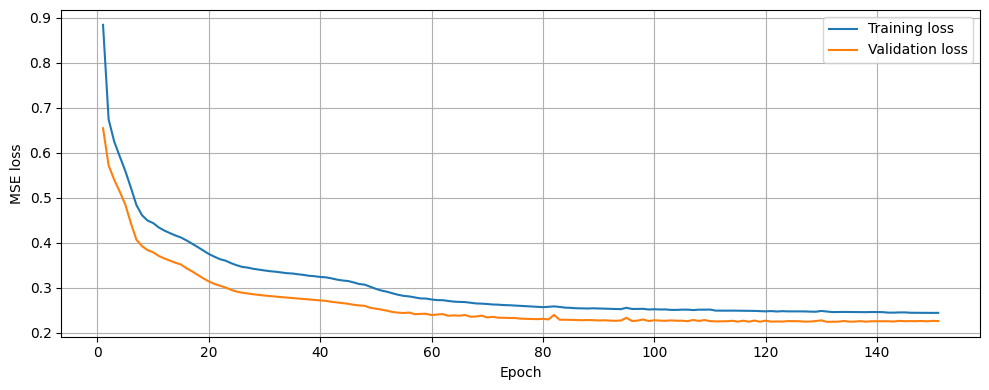

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_1.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_1.history["loss"],
    label="Training loss"
)
plt.plot(
    epochs_ran,
    history_1.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "31_model_1_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 1**

In [ ]:
if SAVE_ARTIFACTS:
    model_1.save(
        save_path(
            "models/autoencoders/41_model_1.keras"
        )
    )

**Experiment 1.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_1 = model_1.predict(X_val, verbose=0)

val_mse_1 = np.mean(
    np.square(X_val - val_recon_1),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_1 = np.mean(val_mse_1) + 2 * np.std(val_mse_1)

# Reconstruction errors on the Calibration set
calibration_recon_1 = model_1.predict(
    X_calibration,
    verbose=0
)

calibration_mse_1 = np.mean(
    np.square(X_calibration - calibration_recon_1),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_1:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_1):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_1):.6f}")

Heuristic threshold: 2.146864
Mean Validation MSE:  0.224297
Std Validation MSE:   0.961284


In [ ]:
# Predictions on the Calibration set
y_pred_heur_1 = (
    calibration_mse_1 > threshold_heur_1
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_1,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_1):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_1 = confusion_matrix(
    y_calibration,
    y_pred_heur_1
)

print(cm_heur_1)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.91      0.99      0.95      6506
       Fraud       0.53      0.07      0.12       697

    accuracy                           0.90      7203
   macro avg       0.72      0.53      0.53      7203
weighted avg       0.87      0.90      0.87      7203

AUC-ROC: 0.7353

=== Calibration Confusion Matrix ===
[[6465   41]
 [ 650   47]]


**Conclusion Based on the Results of Experiment 1.1**

The heuristic threshold results in a low false positive rate but detects only a small proportion of fraudulent transactions. On the Calibration set, Model 1 identifies 47 out of 697 fraudulent transactions, corresponding to a fraud detection recall of approximately 0.07 and a fraud detection precision of approximately 0.53. Thus, the heuristic threshold represents an overly restrictive operating point for Model 1.

**Experiment 1.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_1, best_f1_1 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_1
)

print(f"Optimized threshold: {threshold_opt_1:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_1:.4f}")
print()

Optimized threshold: 1.868172
Best Calibration Fraud F1: 0.4659



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_1 = (
    calibration_mse_1 >= threshold_opt_1
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_1,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_1):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_1 = confusion_matrix(
    y_calibration,
    y_pred_opt_1
)

print(cm_opt_1)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.80      0.33      0.47       697

    accuracy                           0.93      7203
   macro avg       0.87      0.66      0.71      7203
weighted avg       0.92      0.93      0.91      7203

AUC-ROC: 0.7353

=== Calibration Confusion Matrix ===
[[6449   57]
 [ 468  229]]


**Conclusion Based on the Results of Experiment 1.2**

Optimizing the reconstruction error threshold on the Calibration set substantially improves the threshold-dependent anomaly detection metrics. Fraud Recall increases from approximately 0.07 to 0.33, while Fraud Precision increases from approximately 0.53 to 0.80. As a result, Fraud F1 increases from approximately 0.12 to 0.47.

AUC-ROC remains unchanged at 0.7353 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness rather than classification performance at a specific operating point.

## 3.3 Model No. 2

Model 2 extends Model 1 by increasing the depth and width of the autoencoder and adding Dropout regularization.

**Creating Model No. 2**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_2 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(inputs_2)
x = layers.Dropout(0.2, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.Dropout(0.2, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Bottleneck
bottleneck_2 = layers.Dense(8, activation="relu", name="bottleneck")(x)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_2)
x = layers.Dropout(0.2, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.Dropout(0.2, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_2 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_2 = keras.Model(
    inputs=inputs_2,
    outputs=outputs_2,
    name="autoencoder_model_2"
)

model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_2.summary()

Model: "autoencoder_model_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,317 (32.49 KB)

 Trainable params: 8,317 (32.49 KB)

 Non-trainable params: 0 (0.00 B)

**Training Model No. 2**

In [ ]:
early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_2 = model_2.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_2],
    verbose=1
)
best_epoch_2 = int(np.argmin(history_2.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_2.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_2}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.8150 - val_loss: 0.5130
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.6019 - val_loss: 0.4194
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.5274 - val_loss: 0.3392
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.4921 - val_loss: 0.3209
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4733 - val_loss: 0.3123
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.4538 - val_loss: 0.3013
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.4410 - val_loss: 0.2968
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4207 - val_loss: 0.2890
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4156 - val_loss: 0.2776
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.4074 - val_loss: 0.2683
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3919 - val_loss: 0.2641
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━━━━━

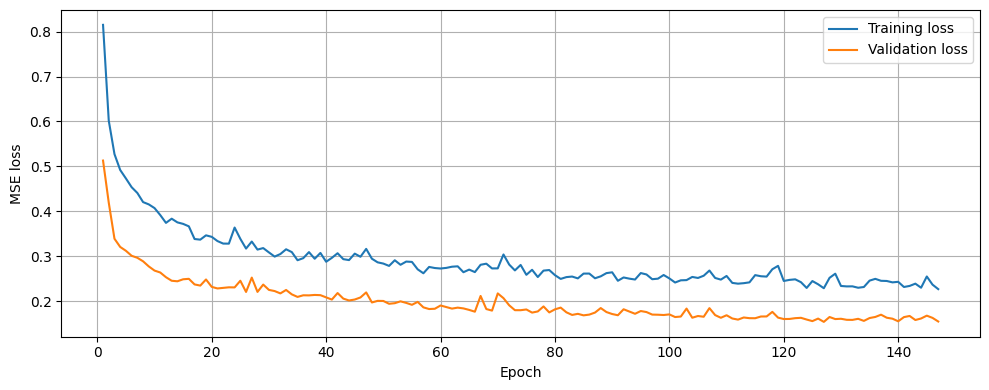

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_2.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_2.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_2.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "32_model_2_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 2**

In [ ]:
if SAVE_ARTIFACTS:
    model_2.save(
        save_path(
            "models/autoencoders/42_model_2.keras"
        )
    )

**Experiment 2.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_2 = model_2.predict(X_val, verbose=0)

val_mse_2 = np.mean(
    np.square(X_val - val_recon_2),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_2 = np.mean(val_mse_2) + 2 * np.std(val_mse_2)

# Reconstruction errors on the Calibration set
calibration_recon_2 = model_2.predict(
    X_calibration,
    verbose=0
)

calibration_mse_2 = np.mean(
    np.square(X_calibration - calibration_recon_2),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_2:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_2):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_2):.6f}")

Heuristic threshold: 1.521816
Mean Validation MSE:  0.154248
Std Validation MSE:   0.683784


In [ ]:
# Predictions on the Calibration set
y_pred_heur_2 = (
    calibration_mse_2 > threshold_heur_2
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_2,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_2):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_2 = confusion_matrix(
    y_calibration,
    y_pred_heur_2
)

print(cm_heur_2)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.91      0.99      0.95      6506
       Fraud       0.53      0.08      0.13       697

    accuracy                           0.90      7203
   macro avg       0.72      0.53      0.54      7203
weighted avg       0.87      0.90      0.87      7203

AUC-ROC: 0.7631

=== Calibration Confusion Matrix ===
[[6459   47]
 [ 644   53]]


**Conclusion Based on the Results of Experiment 2.1**

The heuristic threshold results in a low false positive rate but detects only a small proportion of fraudulent transactions. On the Calibration set, Model 2 identifies 53 out of 697 fraudulent transactions, corresponding to a fraud detection recall of approximately 0.08 and a fraud detection precision of approximately 0.53. Thus, the resulting operating point is overly restrictive for Model 2.

**Experiment 2.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_2, best_f1_2 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_2
)

print(f"Optimized threshold: {threshold_opt_2:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_2:.4f}")
print()

Optimized threshold: 1.133180
Best Calibration Fraud F1: 0.4646



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_2 = (
    calibration_mse_2 >= threshold_opt_2
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_2,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_2):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_2 = confusion_matrix(
    y_calibration,
    y_pred_opt_2
)

print(cm_opt_2)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.76      0.33      0.46       697

    accuracy                           0.93      7203
   macro avg       0.85      0.66      0.71      7203
weighted avg       0.92      0.93      0.91      7203

AUC-ROC: 0.7631

=== Calibration Confusion Matrix ===
[[6433   73]
 [ 464  233]]


**Conclusion Based on the Results of Experiment 2.2**

Optimizing the reconstruction error threshold on the Calibration set substantially improves the threshold-dependent anomaly detection metrics. Fraud Recall increases from approximately 0.08 to 0.33, while Fraud Precision increases from approximately 0.53 to 0.76. As a result, Fraud F1 increases from approximately 0.13 to 0.46.

AUC-ROC remains unchanged at 0.7631 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness rather than classification performance at a specific operating point.

**Overall Conclusion Based on the Evaluation Results of Model 2**

Compared with Model 1, Model 2 demonstrates a higher AUC-ROC on the Calibration set: 0.7631 versus 0.7353. This indicates an improvement in the model's overall ability to rank fraudulent and normal transactions based on reconstruction error.

At the threshold optimized for Fraud F1, the Fraud Recall and Fraud F1 values of Models 1 and 2 remain almost identical: Fraud Recall is approximately 0.33, while Fraud F1 is approximately 0.47. At the same time, Fraud Precision for Model 2 is slightly lower — approximately 0.76 compared with 0.80 for Model 1. Thus, increasing the depth and width of the architecture together with adding Dropout improves the model's threshold-independent ranking ability but does not improve Fraud F1 at the selected operating point.

The next experiment evaluates whether adding BatchNormalization can further improve model performance.

## 3.4 Model No. 3

Model 3 extends Model 2 by adding BatchNormalization layers while preserving the rest of the architecture and the Dropout regularization rate.

**Creating Model No. 3**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_3 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(inputs_3)
x = layers.BatchNormalization(name="encoder_batch_norm_1")(x)
x = layers.Dropout(0.2, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.BatchNormalization(name="encoder_batch_norm_2")(x)
x = layers.Dropout(0.2, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Bottleneck
bottleneck_3 = layers.Dense(8, activation="relu", name="bottleneck")(x)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_3)
x = layers.BatchNormalization(name="decoder_batch_norm_1")(x)
x = layers.Dropout(0.2, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.BatchNormalization(name="decoder_batch_norm_2")(x)
x = layers.Dropout(0.2, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_3 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_3 = keras.Model(
    inputs=inputs_3,
    outputs=outputs_3,
    name="autoencoder_model_3"
)

model_3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_3.summary()

Model: "autoencoder_model_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_batch_norm_1            │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_batch_norm_2            │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_batch_norm_1            │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_batch_norm_2            │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,893 (34.74 KB)

 Trainable params: 8,605 (33.61 KB)

 Non-trainable params: 288 (1.12 KB)

**Training Model No. 3**

In [ ]:
early_stopping_3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_3 = model_3.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_3],
    verbose=1
)
best_epoch_3 = int(np.argmin(history_3.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_3.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_3}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.8666 - val_loss: 0.4877
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.5982 - val_loss: 0.3342
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5297 - val_loss: 0.2937
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4805 - val_loss: 0.2659
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4576 - val_loss: 0.2496
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4389 - val_loss: 0.2342
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.4240 - val_loss: 0.2210
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4111 - val_loss: 0.2043
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3967 - val_loss: 0.1949
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.3748 - val_loss: 0.1941
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3582 - val_loss: 0.1971
Epoch 12/300
238/238 ━━━━━━━━━

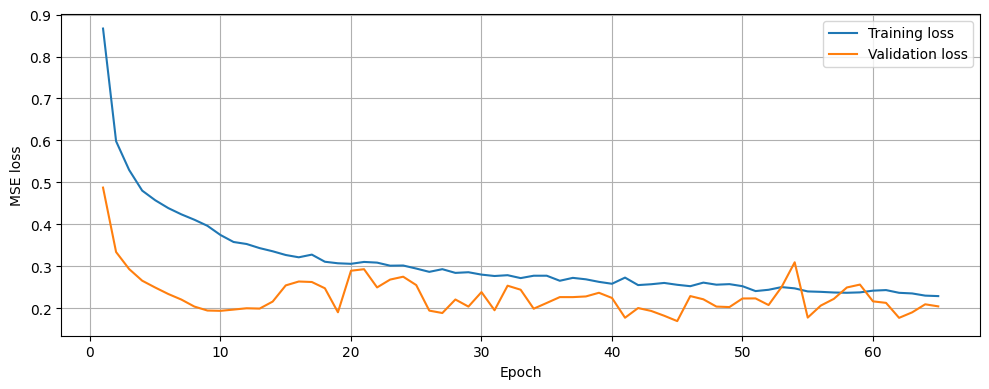

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_3.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_3.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_3.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "33_model_3_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 3**

In [ ]:
if SAVE_ARTIFACTS:
    model_3.save(
        save_path(
            "models/autoencoders/43_model_3.keras"
        )
    )

**Experiment 3.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_3 = model_3.predict(X_val, verbose=0)

val_mse_3 = np.mean(
    np.square(X_val - val_recon_3),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_3 = np.mean(val_mse_3) + 2 * np.std(val_mse_3)

# Reconstruction errors on the Calibration set
calibration_recon_3 = model_3.predict(
    X_calibration,
    verbose=0
)

calibration_mse_3 = np.mean(
    np.square(X_calibration - calibration_recon_3),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_3:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_3):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_3):.6f}")

Heuristic threshold: 6.772716
Mean Validation MSE:  0.169701
Std Validation MSE:   3.301508


In [ ]:
# Predictions on the Calibration set
y_pred_heur_3 = (
    calibration_mse_3 > threshold_heur_3
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_3,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_3):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_3 = confusion_matrix(
    y_calibration,
    y_pred_heur_3
)

print(cm_heur_3)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.91      1.00      0.95      6506
       Fraud       0.83      0.04      0.08       697

    accuracy                           0.91      7203
   macro avg       0.87      0.52      0.52      7203
weighted avg       0.90      0.91      0.87      7203

AUC-ROC: 0.8196

=== Calibration Confusion Matrix ===
[[6500    6]
 [ 667   30]]


**Conclusion Based on the Results of Experiment 3.1**

The heuristic threshold provides a very low false positive rate but detects only a small proportion of fraudulent transactions. On the Calibration set, Model 3 identifies 30 out of 697 fraudulent transactions, corresponding to a fraud detection recall of approximately 0.04. Therefore, the heuristic threshold represents an overly restrictive operating point for this model.


**Experiment 3.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_3, best_f1_3 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_3
)

print(f"Optimized threshold: {threshold_opt_3:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_3:.4f}")
print()

Optimized threshold: 1.194232
Best Calibration Fraud F1: 0.4615



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_3 = (
    calibration_mse_3 >= threshold_opt_3
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_3,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_3):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_3 = confusion_matrix(
    y_calibration,
    y_pred_opt_3
)

print(cm_opt_3)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.78      0.33      0.46       697

    accuracy                           0.93      7203
   macro avg       0.86      0.66      0.71      7203
weighted avg       0.92      0.93      0.91      7203

AUC-ROC: 0.8196

=== Calibration Confusion Matrix ===
[[6443   63]
 [ 469  228]]


**Conclusion Based on the Results of Experiment 3.2**

Optimizing the reconstruction error threshold on the Calibration set substantially increases Fraud Recall from approximately 0.04 to 0.33 and Fraud F1 from approximately 0.08 to 0.46. This is accompanied by a slight decrease in Fraud Precision from approximately 0.83 to 0.78, because more transactions are classified as anomalous at the lower threshold.

AUC-ROC remains unchanged at 0.8196 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness.

**Overall Conclusion Based on the Evaluation Results of Model 3**

Compared with Model 2, adding BatchNormalization substantially improves ranking performance on the Calibration set: AUC-ROC increases from 0.7631 to 0.8196.

At the threshold optimized for Fraud F1, the threshold-dependent metrics change only slightly. Fraud Precision increases from approximately 0.76 to 0.78, Fraud Recall decreases slightly from 0.33 to 0.33 in the rounded representation, while Fraud F1 remains at approximately 0.46.

Thus, in the considered configuration, BatchNormalization substantially improves the model's threshold-independent ability to rank normal and fraudulent transactions but does not provide a comparable improvement in classification metrics at the selected operating point.

The next experiment evaluates the effect of adding an attention mechanism to the autoencoder architecture.

# 4 Autoencoders with an Attention Mechanism

## 4.1 Creating the Attention Layer

In [ ]:
@keras.utils.register_keras_serializable(package="AE_XAI_Ethereum")
class AttentionLayer(layers.Layer):
    """Trainable attention-based weighting of hidden representations."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        hidden_dim = int(input_shape[-1])

        self.W = self.add_weight(
            shape=(hidden_dim, hidden_dim),
            initializer="glorot_uniform",
            trainable=True,
            name="attention_weights"
        )

        self.b = self.add_weight(
            shape=(hidden_dim,),
            initializer="zeros",
            trainable=True,
            name="attention_bias"
        )

        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=-1
        )

        return inputs * attention_weights

    def get_config(self):
        return super().get_config()

print(
    "AttentionLayer defined and registered successfully."
)

AttentionLayer defined and registered successfully.


## 4.2 Model No. 4

Model 4 extends Model 3 by adding an attention layer (AttentionLayer) between the final encoder layer and the compressed representation layer. All other architectural components and training parameters are kept unchanged to isolate the effect of the attention mechanism.

**Creating Model No. 4**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_4 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(inputs_4)
x = layers.BatchNormalization(name="encoder_batch_norm_1")(x)
x = layers.Dropout(0.2, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.BatchNormalization(name="encoder_batch_norm_2")(x)
x = layers.Dropout(0.2, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Attention layer
attention_4 = AttentionLayer(name="attention")(x)

# Bottleneck
bottleneck_4 = layers.Dense(
    8,
    activation="relu",
    name="bottleneck"
)(attention_4)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_4)
x = layers.BatchNormalization(name="decoder_batch_norm_1")(x)
x = layers.Dropout(0.2, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.BatchNormalization(name="decoder_batch_norm_2")(x)
x = layers.Dropout(0.2, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_4 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_4 = keras.Model(
    inputs=inputs_4,
    outputs=outputs_4,
    name="autoencoder_model_4"
)

model_4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_4.summary()

Model: "autoencoder_model_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_batch_norm_1            │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_batch_norm_2            │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_batch_norm_1            │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_batch_norm_2            │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,165 (35.80 KB)

 Trainable params: 8,877 (34.68 KB)

 Non-trainable params: 288 (1.12 KB)

**Training Model No. 4**

In [ ]:
early_stopping_4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_4 = model_4.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_4],
    verbose=1
)

best_epoch_4 = int(np.argmin(history_4.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_4.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_4}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.8752 - val_loss: 0.7915
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.6084 - val_loss: 0.4553
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.5121 - val_loss: 0.3028
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.4605 - val_loss: 0.2479
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.4262 - val_loss: 0.2608
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.4042 - val_loss: 0.2682
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.3755 - val_loss: 0.2550
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3643 - val_loss: 0.3152
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3440 - val_loss: 0.2547
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.3290 - val_loss: 0.2517
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.3184 - val_loss: 0.2493
Epoch 12/300
238/238 ━━━━━━━━━

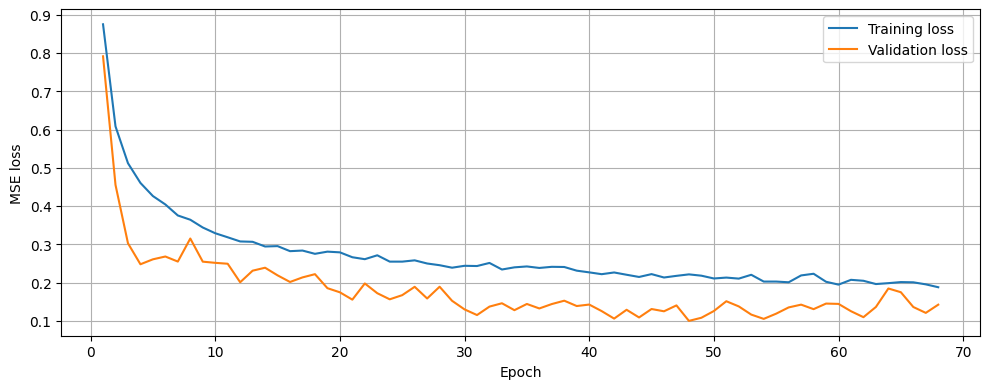

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_4.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_4.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_4.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "34_model_4_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 4**

In [ ]:
if SAVE_ARTIFACTS:
    model_4.save(
        save_path(
            "models/autoencoders/44_model_4.keras"
        )
    )

**Experiment 4.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_4 = model_4.predict(X_val, verbose=0)

val_mse_4 = np.mean(
    np.square(X_val - val_recon_4),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_4 = np.mean(val_mse_4) + 2 * np.std(val_mse_4)

# Reconstruction errors on the Calibration set
calibration_recon_4 = model_4.predict(
    X_calibration,
    verbose=0
)

calibration_mse_4 = np.mean(
    np.square(X_calibration - calibration_recon_4),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_4:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_4):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_4):.6f}")

Heuristic threshold: 2.702257
Mean Validation MSE:  0.099899
Std Validation MSE:   1.301179


In [ ]:
# Predictions on the Calibration set
y_pred_heur_4 = (
    calibration_mse_4 > threshold_heur_4
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_4,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_4):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_4 = confusion_matrix(
    y_calibration,
    y_pred_heur_4
)

print(cm_heur_4)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.91      1.00      0.95      6506
       Fraud       0.73      0.05      0.09       697

    accuracy                           0.91      7203
   macro avg       0.82      0.52      0.52      7203
weighted avg       0.89      0.91      0.87      7203

AUC-ROC: 0.8030

=== Calibration Confusion Matrix ===
[[6494   12]
 [ 665   32]]


**Conclusion Based on the Results of Experiment 4.1**

The heuristic threshold provides a low false positive rate but detects only a small proportion of fraudulent transactions. On the Calibration set, Model 4 detects 32 out of 697 fraudulent transactions, corresponding to a fraud detection recall of approximately 0.05. Therefore, the heuristic threshold represents an overly restrictive operating point for this model.

**Experiment 4.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_4, best_f1_4 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_4
)

print(f"Optimized threshold: {threshold_opt_4:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_4:.4f}")
print()

Optimized threshold: 1.162520
Best Calibration Fraud F1: 0.4750



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_4 = (
    calibration_mse_4 >= threshold_opt_4
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_4,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_4):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_4 = confusion_matrix(
    y_calibration,
    y_pred_opt_4
)

print(cm_opt_4)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.87      0.33      0.47       697

    accuracy                           0.93      7203
   macro avg       0.90      0.66      0.72      7203
weighted avg       0.93      0.93      0.92      7203

AUC-ROC: 0.8030

=== Calibration Confusion Matrix ===
[[6471   35]
 [ 469  228]]


**Conclusion Based on the Results of Experiment 4.2**

Optimizing the reconstruction error threshold on the Calibration set substantially improves the threshold-dependent anomaly detection metrics. Fraud Recall increases from approximately 0.05 to 0.33, while Fraud Precision increases from approximately 0.73 to 0.87. As a result, Fraud F1 increases from approximately 0.09 to 0.47.

AUC-ROC remains unchanged at 0.8030 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness.

**Overall Conclusion Based on the Evaluation Results of Model 4**

Compared with Model 3, adding AttentionLayer decreases AUC-ROC from 0.8196 to 0.8030, indicating a slight deterioration in the model's overall ability to rank transactions by reconstruction error.

At the same time, at the threshold optimized for Fraud F1, Model 4 achieves a higher Fraud Precision — approximately 0.87 compared with 0.78 for Model 3 — while maintaining nearly the same Fraud Recall of approximately 0.33. The number of false positives decreases from 63 to 35, while Fraud F1 increases from approximately 0.46 to 0.47.

Thus, in the considered configuration, adding AttentionLayer improves Fraud Precision and Fraud F1 at the selected operating point but does not improve the model's threshold-independent ranking ability.

## 4.3 Model No. 5

In Model 5, BatchNormalization is removed from Model 4, while the attention layer (AttentionLayer) and the rest of the architecture are retained. This configuration makes it possible to study the interaction between BatchNormalization and the attention mechanism and also provides a direct comparison with Model 2, from which Model 5 differs only by the presence of the attention layer (AttentionLayer).

**Creating Model No. 5**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_5 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(inputs_5)
x = layers.Dropout(0.2, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.Dropout(0.2, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Attention layer
attention_5 = AttentionLayer(name="attention")(x)

# Bottleneck
bottleneck_5 = layers.Dense(
    8,
    activation="relu",
    name="bottleneck"
)(attention_5)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_5)
x = layers.Dropout(0.2, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.Dropout(0.2, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_5 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_5 = keras.Model(
    inputs=inputs_5,
    outputs=outputs_5,
    name="autoencoder_model_5"
)

model_5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_5.summary()

Model: "autoencoder_model_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,589 (33.55 KB)

 Trainable params: 8,589 (33.55 KB)

 Non-trainable params: 0 (0.00 B)

**Training Model No. 5**

In [ ]:
early_stopping_5 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_5 = model_5.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_5],
    verbose=1
)

best_epoch_5 = int(np.argmin(history_5.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_5.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_5}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.8174 - val_loss: 0.5378
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.6099 - val_loss: 0.4613
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5612 - val_loss: 0.4294
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.5310 - val_loss: 0.4039
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5099 - val_loss: 0.3764
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4814 - val_loss: 0.3429
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4581 - val_loss: 0.3093
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4275 - val_loss: 0.2908
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4175 - val_loss: 0.2820
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4025 - val_loss: 0.2684
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3906 - val_loss: 0.2638
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━━━━━

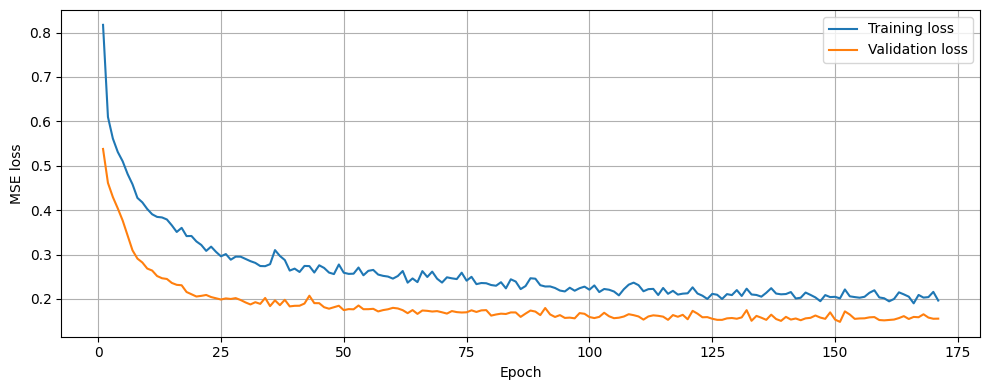

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_5.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_5.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_5.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "35_model_5_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 5**

In [ ]:
if SAVE_ARTIFACTS:
    model_5.save(
        save_path(
            "models/autoencoders/45_model_5.keras"
        )
    )

**Experiment 5.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_5 = model_5.predict(X_val, verbose=0)

val_mse_5 = np.mean(
    np.square(X_val - val_recon_5),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_5 = np.mean(val_mse_5) + 2 * np.std(val_mse_5)

# Reconstruction errors on the Calibration set
calibration_recon_5 = model_5.predict(
    X_calibration,
    verbose=0
)

calibration_mse_5 = np.mean(
    np.square(X_calibration - calibration_recon_5),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_5:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_5):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_5):.6f}")

Heuristic threshold: 0.991141
Mean Validation MSE:  0.148229
Std Validation MSE:   0.421456


In [ ]:
# Predictions on the Calibration set
y_pred_heur_5 = (
    calibration_mse_5 > threshold_heur_5
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_5,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_5):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_5 = confusion_matrix(
    y_calibration,
    y_pred_heur_5
)

print(cm_heur_5)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.91      0.99      0.95      6506
       Fraud       0.40      0.09      0.15       697

    accuracy                           0.90      7203
   macro avg       0.66      0.54      0.55      7203
weighted avg       0.86      0.90      0.87      7203

AUC-ROC: 0.7714

=== Calibration Confusion Matrix ===
[[6409   97]
 [ 632   65]]


**Conclusion Based on the Results of Experiment 5.1**

The heuristic threshold provides a relatively low false positive rate but detects only a small proportion of fraudulent transactions. On the Calibration set, Model 5 identifies 65 out of 697 fraudulent transactions, corresponding to a Fraud Recall of approximately 0.09 and a Fraud Precision of approximately 0.40. Fraud F1 is approximately 0.15. Thus, the heuristic threshold represents an overly restrictive operating point for this model.

**Experiment 5.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_5, best_f1_5 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_5
)

print(f"Optimized threshold: {threshold_opt_5:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_5:.4f}")
print()

Optimized threshold: 0.750277
Best Calibration Fraud F1: 0.4442



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_5 = (
    calibration_mse_5 >= threshold_opt_5
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_5,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_5):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_5 = confusion_matrix(
    y_calibration,
    y_pred_opt_5
)

print(cm_opt_5)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.98      0.96      6506
       Fraud       0.64      0.34      0.44       697

    accuracy                           0.92      7203
   macro avg       0.79      0.66      0.70      7203
weighted avg       0.90      0.92      0.91      7203

AUC-ROC: 0.7714

=== Calibration Confusion Matrix ===
[[6373  133]
 [ 460  237]]


**Conclusion Based on the Results of Experiment 5.2**

Optimizing the reconstruction error threshold on the Calibration set substantially improves the threshold-dependent anomaly detection metrics. Fraud Recall increases from approximately 0.09 to 0.34, Fraud Precision increases from approximately 0.40 to 0.64, and Fraud F1 increases from approximately 0.15 to 0.44.

AUC-ROC remains unchanged at 0.7714 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness.

**Overall Conclusion Based on the Evaluation Results of Model 5**

Compared with Model 4, removing BatchNormalization is accompanied by a decrease in AUC-ROC from 0.8030 to 0.7714. At the threshold optimized for Fraud F1, Fraud Recall increases slightly from approximately 0.33 to 0.34; however, Fraud Precision decreases from 0.87 to 0.64, while Fraud F1 decreases from 0.47 to 0.44. The number of false positives increases from 35 to 133. Thus, the obtained results do not indicate an improvement in the attention-based architecture resulting from the removal of BatchNormalization.

Compared with Model 2, which has the same core architecture but does not include AttentionLayer, Model 5 demonstrates a slightly higher AUC-ROC of 0.7714 versus 0.7631 and nearly the same Fraud Recall. At the same time, Fraud Precision decreases from approximately 0.76 to 0.64, while Fraud F1 decreases from approximately 0.46 to 0.44. Therefore, in this configuration, adding AttentionLayer provides a slight improvement in threshold-independent ranking ability but does not improve classification performance at the threshold optimized for Fraud F1.

Among the attention-based models considered at this stage, Model 4 demonstrates the best results in terms of AUC-ROC and Fraud F1.

## 4.4 Model No. 6

Model 6 retains the architecture and training configuration of Model 5 while reducing the Dropout rate from 0.2 to 0.1. This experiment evaluates the effect of weaker Dropout regularization on the performance of the attention-based autoencoder.

**Creating Model No. 6**

In [14]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_6 = keras.Input(shape=(INPUT_DIM,), name="input")

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(inputs_6)
x = layers.Dropout(0.1, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.Dropout(0.1, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Attention layer
attention_6 = AttentionLayer(name="attention")(x)

# Bottleneck
bottleneck_6 = layers.Dense(
    8,
    activation="relu",
    name="bottleneck"
)(attention_6)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_6)
x = layers.Dropout(0.1, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.Dropout(0.1, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_6 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_6 = keras.Model(
    inputs=inputs_6,
    outputs=outputs_6,
    name="autoencoder_model_6"
)

model_6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_6.summary()

Model: "autoencoder_model_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,589 (33.55 KB)

 Trainable params: 8,589 (33.55 KB)

 Non-trainable params: 0 (0.00 B)

**Training Model No. 6**

In [ ]:
early_stopping_6 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_6 = model_6.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_6],
    verbose=1
)

best_epoch_6 = int(np.argmin(history_6.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_6.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_6}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.7784 - val_loss: 0.4896
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5313 - val_loss: 0.3690
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4595 - val_loss: 0.3215
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4110 - val_loss: 0.2742
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3762 - val_loss: 0.2428
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3467 - val_loss: 0.2154
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3159 - val_loss: 0.1934
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.2912 - val_loss: 0.1808
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2761 - val_loss: 0.1717
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2670 - val_loss: 0.1644
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2503 - val_loss: 0.1600
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━━━━

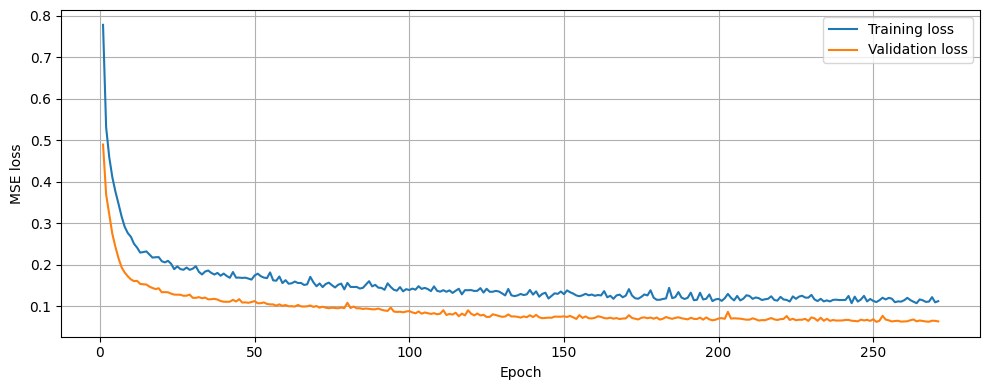

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_6.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_6.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_6.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "36_model_6_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Trained Model No. 6**

In [ ]:
if SAVE_ARTIFACTS:
    model_6.save(
        save_path(
            "models/autoencoders/46_model_6.keras"
        )
    )

**Experiment 6.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [16]:
# Reconstruction errors on the Validation set
val_recon_6 = model_6.predict(X_val, verbose=0)

val_mse_6 = np.mean(
    np.square(X_val - val_recon_6),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_6 = np.mean(val_mse_6) + 2 * np.std(val_mse_6)

# Reconstruction errors on the Calibration set
calibration_recon_6 = model_6.predict(
    X_calibration,
    verbose=0
)

calibration_mse_6 = np.mean(
    np.square(X_calibration - calibration_recon_6),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_6:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_6):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_6):.6f}")

Heuristic threshold: 0.409361
Mean Validation MSE:  0.061723
Std Validation MSE:   0.173819


In [17]:
# Predictions on the Calibration set
y_pred_heur_6 = (
    calibration_mse_6 > threshold_heur_6
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_6,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_6):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_6 = confusion_matrix(
    y_calibration,
    y_pred_heur_6
)

print(cm_heur_6)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.98      0.95      6506
       Fraud       0.62      0.35      0.45       697

    accuracy                           0.92      7203
   macro avg       0.78      0.67      0.70      7203
weighted avg       0.90      0.92      0.91      7203

AUC-ROC: 0.8420

=== Calibration Confusion Matrix ===
[[6355  151]
 [ 450  247]]


**Conclusion Based on the Results of Experiment 6.1**

The heuristic threshold detects 247 out of 697 fraudulent transactions on the Calibration set, corresponding to a fraud detection recall of approximately 0.35 and a fraud detection precision of approximately 0.62. Although this operating point provides relatively high fraud detection recall, it also results in 151 false positives.

**Experiment 6.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [18]:
threshold_opt_6, best_f1_6 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_6
)

if SAVE_ARTIFACTS:
    joblib.dump(
        float(threshold_opt_6),
        save_path(
            "results/model_6_analysis/"
            "91_model_6_threshold.pkl"
        )
    )

    print(
        "Model 6 calibrated threshold saved to "
        "91_model_6_threshold.pkl."
    )

print()

print(f"Optimized threshold: {threshold_opt_6:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_6:.4f}")
print()


Optimized threshold: 0.246948
Best Calibration Fraud F1: 0.4772



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_6 = (
    calibration_mse_6 >= threshold_opt_6
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_6,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_6):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_6 = confusion_matrix(
    y_calibration,
    y_pred_opt_6
)

print(cm_opt_6)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95      6506
       Fraud       0.54      0.43      0.48       697

    accuracy                           0.91      7203
   macro avg       0.74      0.69      0.71      7203
weighted avg       0.90      0.91      0.90      7203

AUC-ROC: 0.8420

=== Calibration Confusion Matrix ===
[[6252  254]
 [ 399  298]]


**Conclusion Based on the Results of Experiment 6.2**

Optimizing the reconstruction error threshold on the Calibration set shifts the model's operating point toward higher recall of fraudulent transactions. Fraud Recall increases from approximately 0.35 to 0.43, while Fraud Precision decreases from approximately 0.62 to 0.54. The number of true positives increases from 247 to 298, accompanied by an increase in false positives from 151 to 254. As a result, Fraud F1 increases from approximately 0.45 to 0.48.

AUC-ROC remains unchanged at 0.8420 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness.

**Overall Conclusion Based on the Evaluation Results of Model 6**

Compared with Model 5, reducing the Dropout rate from 0.2 to 0.1 is accompanied by a substantial improvement in the performance of Model 6. AUC-ROC increases from 0.7714 to 0.8420, Fraud Recall at the optimized threshold increases from approximately 0.34 to 0.43, and Fraud F1 increases from approximately 0.44 to 0.48. At the same time, Fraud Precision decreases from approximately 0.64 to 0.54, reflecting a shift in the operating point optimized for Fraud F1 toward higher detection recall.

The best Validation loss was achieved at epoch 251, while training terminated after 271 epochs due to EarlyStopping. This confirms that the overall maximum training budget of 300 epochs is sufficient for Model 6.

Among Models 1–6, Model 6 demonstrates the highest AUC-ROC and Fraud Recall on the Calibration set, as well as a slightly higher Fraud F1. Thus, at this stage, Model 6 is the strongest candidate for further use.

## 4.5 Model No. 7

Model 7 retains the fully connected layer structure, Dropout rate, and training configuration of Model 6, but moves the AttentionLayer from the hidden representation before the bottleneck directly to the model input. Since the input dimensionality of the AttentionLayer changes from 16 to 21, the number of its trainable parameters increases from 272 to 462. Thus, the experiment primarily evaluates the effect of the attention mechanism placement, although moving the layer is also accompanied by a slight increase in the total number of model parameters.

**Creating Model No. 7**

In [ ]:
# Reset random seed before model initialization
reset_seed()

# Input layer
inputs_7 = keras.Input(shape=(INPUT_DIM,), name="input")

# Attention applied directly to the input features
attention_7 = AttentionLayer(name="attention")(inputs_7)

# Encoder
x = layers.Dense(64, activation="relu", name="encoder_dense_1")(attention_7)
x = layers.Dropout(0.1, name="encoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="encoder_dense_2")(x)
x = layers.Dropout(0.1, name="encoder_dropout_2")(x)

x = layers.Dense(16, activation="relu", name="encoder_dense_3")(x)

# Bottleneck
bottleneck_7 = layers.Dense(
    8,
    activation="relu",
    name="bottleneck"
)(x)

# Decoder
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(bottleneck_7)
x = layers.Dropout(0.1, name="decoder_dropout_1")(x)

x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
x = layers.Dropout(0.1, name="decoder_dropout_2")(x)

x = layers.Dense(64, activation="relu", name="decoder_dense_3")(x)

# Output layer
outputs_7 = layers.Dense(
    INPUT_DIM,
    activation="linear",
    name="output"
)(x)

model_7 = keras.Model(
    inputs=inputs_7,
    outputs=outputs_7,
    name="autoencoder_model_7"
)

model_7.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)

model_7.summary()

Model: "autoencoder_model_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 21)             │           462 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_1 (Dropout)     │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_3 (Dense)         │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_1 (Dropout)     │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout_2 (Dropout)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_3 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 21)             │         1,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,779 (34.29 KB)

 Trainable params: 8,779 (34.29 KB)

 Non-trainable params: 0 (0.00 B)

**Training Model No. 7**

In [ ]:
early_stopping_7 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True
)

history_7 = model_7.fit(
    X_train,
    X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, X_val),
    callbacks=[early_stopping_7],
    verbose=1
)

best_epoch_7 = int(np.argmin(history_7.history["val_loss"]) + 1)

print()
print(f"Training epochs completed: {len(history_7.history['loss'])}")
print(f"Best epoch by Validation loss: {best_epoch_7}")

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.7809 - val_loss: 0.4867
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5354 - val_loss: 0.3742
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4572 - val_loss: 0.3165
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3687 - val_loss: 0.2239
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.3189 - val_loss: 0.1872
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2876 - val_loss: 0.1767
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2702 - val_loss: 0.1697
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2579 - val_loss: 0.1635
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2551 - val_loss: 0.1608
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2347 - val_loss: 0.1553
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2264 - val_loss: 0.1507
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━━━━━

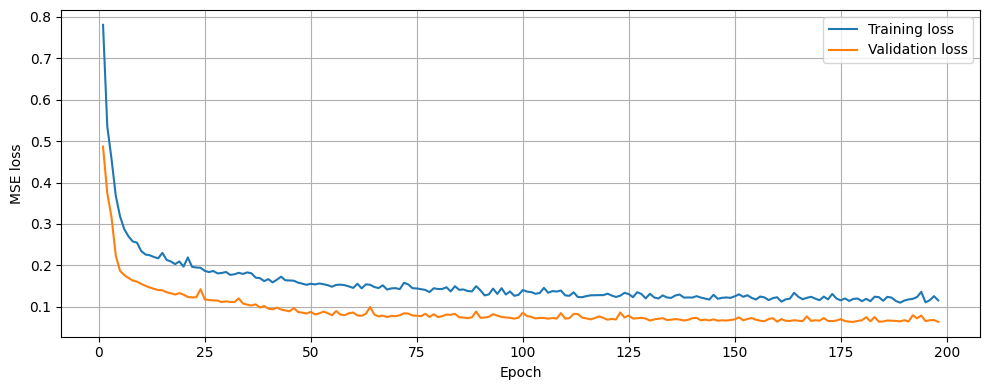

In [ ]:
# Plot training and validation loss

epochs_ran = range(1, len(history_7.history["loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epochs_ran,
    history_7.history["loss"],
    label="Training loss"
)

plt.plot(
    epochs_ran,
    history_7.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/training_history/"
            "37_model_7_training_history.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Saving Model No. 7 Weights**

In [ ]:
if SAVE_ARTIFACTS:
    model_7.save(
        save_path(
            "models/autoencoders/47_model_7.keras"
        )
    )

**Experiment 7.1 - Evaluation of Model Performance Using a Heuristic Reconstruction Error Threshold**

In [ ]:
# Reconstruction errors on the Validation set
val_recon_7 = model_7.predict(X_val, verbose=0)

val_mse_7 = np.mean(
    np.square(X_val - val_recon_7),
    axis=1
)

# Heuristic threshold: mean + 2 standard deviations
threshold_heur_7 = np.mean(val_mse_7) + 2 * np.std(val_mse_7)

# Reconstruction errors on the Calibration set
calibration_recon_7 = model_7.predict(
    X_calibration,
    verbose=0
)

calibration_mse_7 = np.mean(
    np.square(X_calibration - calibration_recon_7),
    axis=1
)

print(f"Heuristic threshold: {threshold_heur_7:.6f}")
print(f"Mean Validation MSE:  {np.mean(val_mse_7):.6f}")
print(f"Std Validation MSE:   {np.std(val_mse_7):.6f}")

Heuristic threshold: 0.421867
Mean Validation MSE:  0.063657
Std Validation MSE:   0.179105


In [ ]:
# Predictions on the Calibration set
y_pred_heur_7 = (
    calibration_mse_7 > threshold_heur_7
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_heur_7,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_7):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_heur_7 = confusion_matrix(
    y_calibration,
    y_pred_heur_7
)

print(cm_heur_7)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.94      0.98      0.96      6506
       Fraud       0.64      0.37      0.47       697

    accuracy                           0.92      7203
   macro avg       0.79      0.67      0.71      7203
weighted avg       0.91      0.92      0.91      7203

AUC-ROC: 0.8098

=== Calibration Confusion Matrix ===
[[6361  145]
 [ 439  258]]


**Conclusion Based on the Results of Experiment 7.1**

The heuristic threshold provides Model 7 with relatively high recall of fraudulent transactions. On the Calibration set, Fraud Recall is approximately 0.37, while Fraud Precision is approximately 0.64. The model correctly identifies 258 out of 697 fraudulent transactions while producing 145 false positives. Fraud F1 is approximately 0.47.

The model's AUC-ROC is 0.8098, indicating a relatively strong overall ability to rank normal and fraudulent transactions based on reconstruction error.

**Experiment 7.2 - Evaluation Using the F1-Optimized Reconstruction Error Threshold**

In [ ]:
threshold_opt_7, best_f1_7 = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_7
)

print(f"Optimized threshold: {threshold_opt_7:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_7:.4f}")
print()

Optimized threshold: 0.836006
Best Calibration Fraud F1: 0.4753



In [ ]:
# Predictions on the Calibration set using the optimized threshold
y_pred_opt_7 = (
    calibration_mse_7 >= threshold_opt_7
).astype(int)

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        y_pred_opt_7,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_mse_7):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_opt_7 = confusion_matrix(
    y_calibration,
    y_pred_opt_7
)

print(cm_opt_7)

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.84      0.33      0.48       697

    accuracy                           0.93      7203
   macro avg       0.89      0.66      0.72      7203
weighted avg       0.92      0.93      0.91      7203

AUC-ROC: 0.8098

=== Calibration Confusion Matrix ===
[[6462   44]
 [ 466  231]]


**Conclusion Based on the Results of Experiment 7.2**

Optimizing the reconstruction error threshold on the Calibration set changes the balance between Fraud Precision and Fraud Recall. Fraud Recall decreases from approximately 0.37 to 0.33, while Fraud Precision increases from approximately 0.64 to 0.84. The number of false positives decreases from 145 to 44. As a result, Fraud F1 increases slightly from approximately 0.47 to 0.48.

AUC-ROC remains unchanged at 0.8098 because this metric is independent of the classification threshold and reflects the model's overall ability to rank transactions by their degree of anomalousness.

**Overall Conclusion Based on the Evaluation Results of Model 7**

Compared with Model 6, moving the AttentionLayer from the hidden representation before the bottleneck directly to the model input is accompanied by a decrease in AUC-ROC from 0.8420 to 0.8098. At the threshold optimized for Fraud F1, Fraud Precision increases substantially from approximately 0.54 to 0.84, while Fraud Recall decreases from approximately 0.43 to 0.33. Fraud F1 remains virtually unchanged at approximately 0.48 for both models.

Thus, placing the AttentionLayer directly at the input produces an operating point with fewer false positives and higher Fraud Precision but reduces both the model's threshold-independent ranking ability and Fraud Recall. Given the adopted priority of AUC-ROC and Fraud Recall, the results do not support an advantage of moving the attention mechanism to the model input.

## 4.6 Conclusion

Based on the sequential comparison of the architectures, Model 6 was selected as the primary model for the subsequent stages of the study. On the Calibration set, it demonstrated the highest AUC-ROC among Models 1–7, reaching 0.8420, which indicates the strongest overall ability to rank normal and fraudulent transactions based on reconstruction error.

At the threshold optimized for Fraud F1, Model 6 also demonstrated the highest Fraud Recall of approximately 0.43 and a slightly higher Fraud F1 of approximately 0.48. The higher Fraud Precision achieved by some models is associated with substantially lower Fraud Recall and therefore does not compensate for their lower AUC-ROC values given the adopted prioritization of metrics.

Moving the AttentionLayer directly to the input in Model 7 did not provide further improvement: AUC-ROC decreased to 0.8098, while Fraud Recall decreased to approximately 0.33. Therefore, the Model 6 architecture, in which the AttentionLayer is located between the final encoder layer and the bottleneck and the Dropout rate is 0.1, was selected for further explainability analysis and subsequent final evaluation.

The architecture, hyperparameters, and optimized threshold of the model must be fixed after completion of the calibration stage and before the one-time evaluation on the Holdout Test set.

# 5 Explainability

## 5.1 SHAP

SHAP (SHapley Additive exPlanations) is a model-agnostic explanation method based on Shapley values from cooperative game theory.

In this analysis, SHAP is used to explain the scalar reconstruction error computed by the selected autoencoder. For each transaction, SHAP estimates how each of the 21 input features affects the reconstruction error relative to the background distribution. A positive SHAP value corresponds to a contribution that increases the reconstruction error relative to the baseline, whereas a negative value corresponds to a contribution that decreases it.

Since reconstruction error is used as the anomaly score, a larger positive contribution is associated with a higher anomaly score. However, SHAP values explain the reconstruction error and do not directly indicate whether a transaction is fraudulent.

**SHAP-Based Feature Importance Analysis for Model 6**

In [ ]:
SHAP_BACKGROUND_SIZE = 100
SHAP_EXPLAIN_SIZE = len(X_calibration)
SHAP_RANDOM_STATE = 42

N_FEATURES = len(feature_cols)

assert N_FEATURES == 21
assert SHAP_BACKGROUND_SIZE <= len(X_train)

rng_shap = np.random.default_rng(SHAP_RANDOM_STATE)


# ============================================================
# Background dataset
# ============================================================

background_idx = rng_shap.choice(
    len(X_train),
    size=SHAP_BACKGROUND_SIZE,
    replace=False
)

background = np.asarray(
    X_train[background_idx],
    dtype=np.float32
)


# ============================================================
# Transactions to explain
# ============================================================

# Use the entire Calibration set
explain_data = np.asarray(
    X_calibration,
    dtype=np.float32
)

explain_labels = y_calibration

In [ ]:
# ============================================================
# Scalar reconstruction error of Model 6
# ============================================================

def reconstruction_error_for_shap(x):
    x_tensor = tf.convert_to_tensor(
        x,
        dtype=tf.float32
    )

    x_pred = model_6(
        x_tensor,
        training=False
    )

    reconstruction_error = tf.reduce_mean(
        tf.square(x_tensor - x_pred),
        axis=1
    )

    return reconstruction_error.numpy().reshape(-1, 1)


# ============================================================
# SHAP PermutationExplainer
# ============================================================

masker = shap.maskers.Independent(
    background,
    max_samples=SHAP_BACKGROUND_SIZE
)

explainer = shap.PermutationExplainer(
    reconstruction_error_for_shap,
    masker,
    feature_names=feature_cols,
    seed=SHAP_RANDOM_STATE
)

# This is the computationally expensive step
shap_values = explainer(
    explain_data
)

print(
    "SHAP value calculation completed successfully."
)

PermutationExplainer explainer: 7204it [23:24,  5.11it/s]


SHAP value calculation completed successfully.


In [ ]:
# Validate SHAP output shapes and report class composition

print("Background shape:", background.shape)
print("Explained dataset shape:", explain_data.shape)
print("SHAP values shape:", shap_values.values.shape)

print()
print("=== Explained Calibration Set ===")
print(f"Normal: {np.sum(explain_labels == 0)}")
print(f"Fraud:  {np.sum(explain_labels == 1)}")

assert background.shape == (
    SHAP_BACKGROUND_SIZE,
    N_FEATURES
)

assert explain_data.shape == (
    SHAP_EXPLAIN_SIZE,
    N_FEATURES
)

assert shap_values.values.shape[0] == SHAP_EXPLAIN_SIZE
assert shap_values.values.shape[1] == N_FEATURES

Background shape: (100, 21)
Explained dataset shape: (7203, 21)
SHAP values shape: (7203, 21)

=== Explained Calibration Set ===
Normal: 6506
Fraud:  697


**Saving the Indices**

In [ ]:
if SAVE_ARTIFACTS:
    np.save(
        save_path(
            "results/shap/"
            "51_shap_background_indices.npy"
        ),
        background_idx
    )

For each transaction in the Calibration set, SHAP returns a vector of 21 values representing the contributions of the 21 input features to the scalar reconstruction error *e*(*x*). Since the analysis is performed for the entire Calibration set, the expected shape of the SHAP array is (7203, 21).

In [ ]:
# Convert SHAP values to a NumPy array
shap_array = np.asarray(shap_values.values)

# For a model with a single scalar output, SHAP may return
# an additional singleton output dimension.
if shap_array.ndim == 3 and shap_array.shape[-1] == 1:
    shap_array = shap_array[..., 0]

assert shap_array.shape == (
    SHAP_EXPLAIN_SIZE,
    N_FEATURES
), (
    f"Unexpected SHAP array shape: {shap_array.shape}"
)

print("SHAP array shape:", shap_array.shape)


# Global feature importance:
# mean absolute SHAP value across explained transactions
shap_importance_values = np.mean(
    np.abs(shap_array),
    axis=0
)

importance = (
    pd.DataFrame({
        "feature": feature_cols,
        "shap_importance": shap_importance_values
    })
    .sort_values(
        "shap_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# Rank 1 corresponds to the most important feature
importance["rank"] = np.arange(
    1,
    len(importance) + 1
)

importance = importance[
    ["rank", "feature", "shap_importance"]
]

print()
print("=== SHAP Feature Importance ===")
print(importance.to_string(index=False))

SHAP array shape: (7203, 21)

=== SHAP Feature Importance ===
 rank              feature  shap_importance
    1                nonce         0.051103
    2     is_contract_call         0.040290
    3             is_error         0.038871
    4     sender_unique_to         0.038207
    5  method_id_frequency         0.031083
    6 sender_avg_value_eth         0.030477
    7          is_first_tx         0.029856
    8        is_zero_value         0.029292
    9           is_weekend         0.024851
   10      sender_tx_count         0.023103
   11            gas_limit         0.020547
   12             gas_used         0.020030
   13   sender_avg_gas_eff         0.019666
   14       gas_price_gwei         0.019085
   15       gas_efficiency         0.018093
   16    sender_error_rate         0.017110
   17            value_eth         0.014514
   18             hour_cos         0.014491
   19             hour_sin         0.013611
   20      input_len_bytes         0.013417
   21         

**Saving SHAP Values**

In [ ]:
if SAVE_ARTIFACTS:
    importance.to_csv(
        save_path(
            "results/shap/52_shap_importance.csv"
        ),
        index=False
    )

    np.save(
        save_path(
            "results/shap/53_shap_values.npy"
        ),
        shap_array
    )

**Visualization**

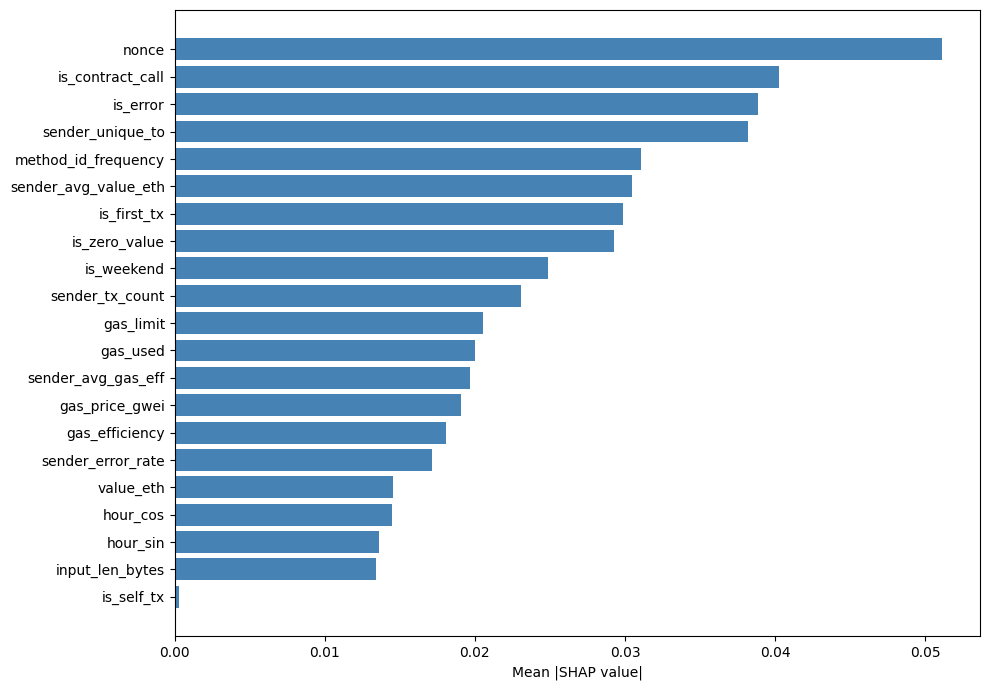

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    importance["feature"],
    importance["shap_importance"],
    color="steelblue"
)

ax.set_xlabel("Mean |SHAP value|")
ax.invert_yaxis()

fig.tight_layout()

if SAVE_ARTIFACTS:
    fig.savefig(
        save_path(
            "results/shap/"
            "54_shap_importance.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

## 5.2 Attention

The output activations of the attention layer in Model 6 are extracted and used to assess the relationship between the 21 input features and the 16 neurons of the weighted hidden representation using Pearson correlation analysis.

In [ ]:
# Auxiliary model returning the output activations
# of the AttentionLayer in Model 6: h * alpha, dimension = 16

attention_layer = model_6.get_layer("attention")

attention_model = keras.Model(
    inputs=model_6.input,
    outputs=attention_layer.output,
    name="model_6_attention_output"
)

print("Model 6 output shape:", model_6.output_shape)
print("AttentionLayer output shape:", attention_model.output_shape)

Model 6 output shape: (None, 21)
AttentionLayer output shape: (None, 16)


In [ ]:
# Use the entire Calibration set.
# For each transaction, extract the 16 output activations
# of the AttentionLayer.

X_attention = np.asarray(
    X_calibration,
    dtype=np.float32
)

att_out = attention_model.predict(
    X_attention,
    batch_size=BATCH_SIZE,
    verbose=0
)

n_samples, n_features = X_attention.shape
n_attention_units = att_out.shape[1]


# ============================================================
# Shape checks
# ============================================================

assert n_features == len(feature_cols) == 21, (
    f"Expected 21 input features, got {n_features}"
)

assert att_out.shape[0] == n_samples, (
    "The number of input transactions and "
    "AttentionLayer outputs does not match"
)

assert n_attention_units == 16, (
    f"Expected 16 AttentionLayer units, "
    f"got {n_attention_units}"
)


# ============================================================
# Variability checks
# ============================================================

# Pearson correlation is undefined for variables
# with zero variance.

constant_feature_idx = np.where(
    np.isclose(
        np.std(X_attention, axis=0),
        0.0
    )
)[0]

constant_attention_idx = np.where(
    np.isclose(
        np.std(att_out, axis=0),
        0.0
    )
)[0]

if len(constant_feature_idx) > 0:
    constant_features = [
        feature_cols[i]
        for i in constant_feature_idx
    ]

    raise ValueError(
        "Input features with zero variance detected: "
        f"{constant_features}"
    )

if len(constant_attention_idx) > 0:
    raise ValueError(
        "AttentionLayer units with zero variance detected: "
        f"{constant_attention_idx.tolist()}"
    )


# ============================================================
# Correlation analysis
# ============================================================

# Combine:
# 21 input features + 16 AttentionLayer activations
combined = np.concatenate(
    [X_attention, att_out],
    axis=1
)

# Full correlation matrix:
# (21 + 16) x (21 + 16) = 37 x 37
corr_matrix = np.corrcoef(
    combined,
    rowvar=False
)

# Absolute correlations between:
# 21 input features x 16 AttentionLayer units
corr_block = np.abs(
    corr_matrix[
        :n_features,
        n_features:
    ]
)

if not np.isfinite(corr_block).all():
    raise ValueError(
        "NaN or infinite values detected "
        "in the correlation matrix"
    )


# ============================================================
# Global correlation-based feature importance
# ============================================================

# For each input feature, calculate the mean absolute
# Pearson correlation across all 16 AttentionLayer units.
attention_feature_importance = corr_block.mean(
    axis=1
)

att_importance = (
    pd.DataFrame({
        "feature": feature_cols,
        "attention_importance":
            attention_feature_importance
    })
    .sort_values(
        "attention_importance",
        ascending=False
    )
    .reset_index(drop=True)
)

att_importance["rank"] = np.arange(
    1,
    len(att_importance) + 1
)

att_importance = att_importance[
    [
        "rank",
        "feature",
        "attention_importance"
    ]
]


# ============================================================
# Results
# ============================================================

print("Calibration input shape:", X_attention.shape)
print("AttentionLayer output shape:", att_out.shape)
print("Correlation matrix shape:", corr_matrix.shape)
print("Feature-attention correlation shape:", corr_block.shape)

print()
print("=== AttentionLayer Correlation-Based Feature Importance ===")
print(att_importance.to_string(index=False))

Calibration input shape: (7203, 21)
AttentionLayer output shape: (7203, 16)
Correlation matrix shape: (37, 37)
Feature-attention correlation shape: (21, 16)

=== AttentionLayer Correlation-Based Feature Importance ===
 rank              feature  attention_importance
    1            value_eth              0.268717
    2       gas_price_gwei              0.262213
    3            gas_limit              0.222060
    4     sender_unique_to              0.216447
    5             gas_used              0.212832
    6 sender_avg_value_eth              0.204601
    7     is_contract_call              0.195198
    8      input_len_bytes              0.176766
    9             is_error              0.175571
   10   sender_avg_gas_eff              0.173271
   11        is_zero_value              0.166852
   12                nonce              0.160920
   13           is_self_tx              0.159523
   14  method_id_frequency              0.157245
   15      sender_tx_count              0.15300

**Saving the Raw Correlation Matrix**

In [ ]:
attention_corr_df = pd.DataFrame(
    corr_block,
    index=feature_cols,
    columns=[
        f"attention_neuron_{i + 1}"
        for i in range(n_attention_units)
    ]
)

if SAVE_ARTIFACTS:
    attention_corr_df.to_csv(
        save_path(
            "results/attention/"
            "61_attention_feature_neuron_correlations.csv"
        ),
        index_label="feature"
    )

**Saving Attention Values**

In [ ]:
if SAVE_ARTIFACTS:
    att_importance.to_csv(
        save_path(
            "results/attention/62_att_importance.csv"
        ),
        index=False
    )

**Visualization**

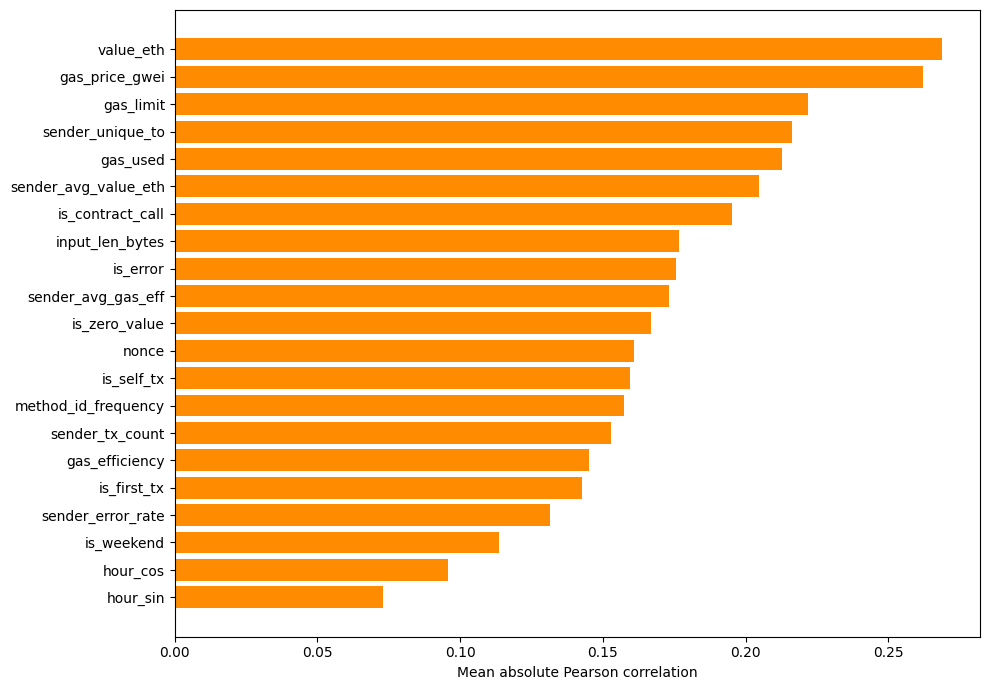

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    att_importance["feature"],
    att_importance["attention_importance"],
    color="darkorange"
)

ax.set_xlabel("Mean absolute Pearson correlation")

ax.invert_yaxis()
fig.tight_layout()

if SAVE_ARTIFACTS:
    fig.savefig(
        save_path(
            "results/attention/"
            "63_attention_importance.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

## 5.3 Comparison of the Two Methods

**Rank Comparison**

In [ ]:
shap_comparison = importance[
    ["feature", "shap_importance", "rank"]
].rename(
    columns={"rank": "shap_rank"}
)

attention_comparison = att_importance[
    ["feature", "attention_importance", "rank"]
].rename(
    columns={"rank": "attention_rank"}
)

comparison = shap_comparison.merge(
    attention_comparison,
    on="feature",
    how="inner",
    validate="one_to_one"
)

# Sanity checks
assert len(comparison) == len(feature_cols) == 21
assert set(comparison["feature"]) == set(feature_cols)

comparison = (
    comparison
    .sort_values("shap_rank")
    .reset_index(drop=True)
)

print("=== SHAP vs Attention Rank Comparison ===")
print(
    comparison[
        ["feature", "shap_rank", "attention_rank"]
    ].to_string(index=False)
)

=== SHAP vs Attention Rank Comparison ===
             feature  shap_rank  attention_rank
               nonce          1              12
    is_contract_call          2               7
            is_error          3               9
    sender_unique_to          4               4
 method_id_frequency          5              14
sender_avg_value_eth          6               6
         is_first_tx          7              17
       is_zero_value          8              11
          is_weekend          9              19
     sender_tx_count         10              15
           gas_limit         11               3
            gas_used         12               5
  sender_avg_gas_eff         13              10
      gas_price_gwei         14               2
      gas_efficiency         15              16
   sender_error_rate         16              18
           value_eth         17               1
            hour_cos         18              20
            hour_sin         19              2

**Saving the Comparison Results**

In [ ]:
if SAVE_ARTIFACTS:
    comparison.to_csv(
        save_path(
            "results/explainability_comparison/"
            "71_shap_att_comparison.csv"
        ),
        index=False
    )

**Visualization**

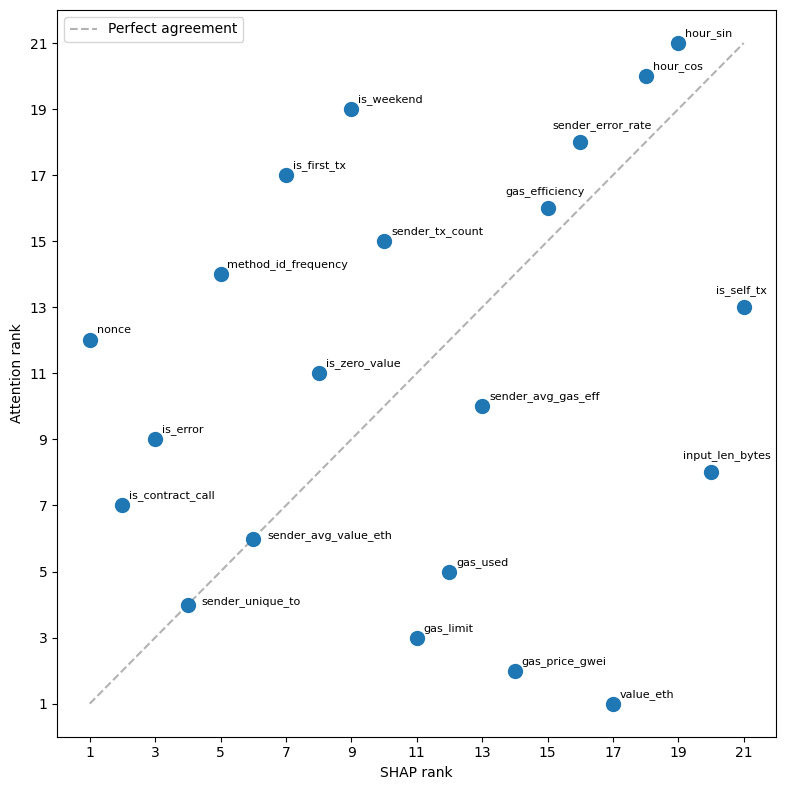

In [ ]:
fig, ax = plt.subplots(figsize=(8, 8))

n_features = len(comparison)

# Scatter plot
ax.scatter(
    comparison["shap_rank"],
    comparison["attention_rank"],
    s=100,
    zorder=5
)

# Perfect rank agreement diagonal
ax.plot(
    [1, n_features],
    [1, n_features],
    "k--",
    alpha=0.3,
    label="Perfect agreement"
)

# Individual label offsets for readability
custom_offsets = {
    "sender_error_rate": (-20, 10),
    "gas_efficiency": (-30, 10),
    "sender_unique_to": (10, 0),
    "is_self_tx": (-20, 10),
    "sender_avg_value_eth": (10, 0),
    "input_len_bytes": (-20, 10),
}

# Feature labels
for _, row in comparison.iterrows():
    feature = row["feature"]

    offset = custom_offsets.get(
        feature,
        (5, 5)
    )

    ax.annotate(
        feature,
        (
            row["shap_rank"],
            row["attention_rank"]
        ),
        textcoords="offset points",
        xytext=offset,
        fontsize=8
    )

ax.set_xlabel("SHAP rank")
ax.set_ylabel("Attention rank")

ax.set_xlim(0, n_features + 1)
ax.set_ylim(0, n_features + 1)

ax.set_xticks(range(1, n_features + 1, 2))
ax.set_yticks(range(1, n_features + 1, 2))

ax.legend()

plt.tight_layout()

if SAVE_ARTIFACTS:
    fig.savefig(
        save_path(
            "results/explainability_comparison/"
            "72_rank_scatter.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

**Comparative Horizontal Bar Chart**

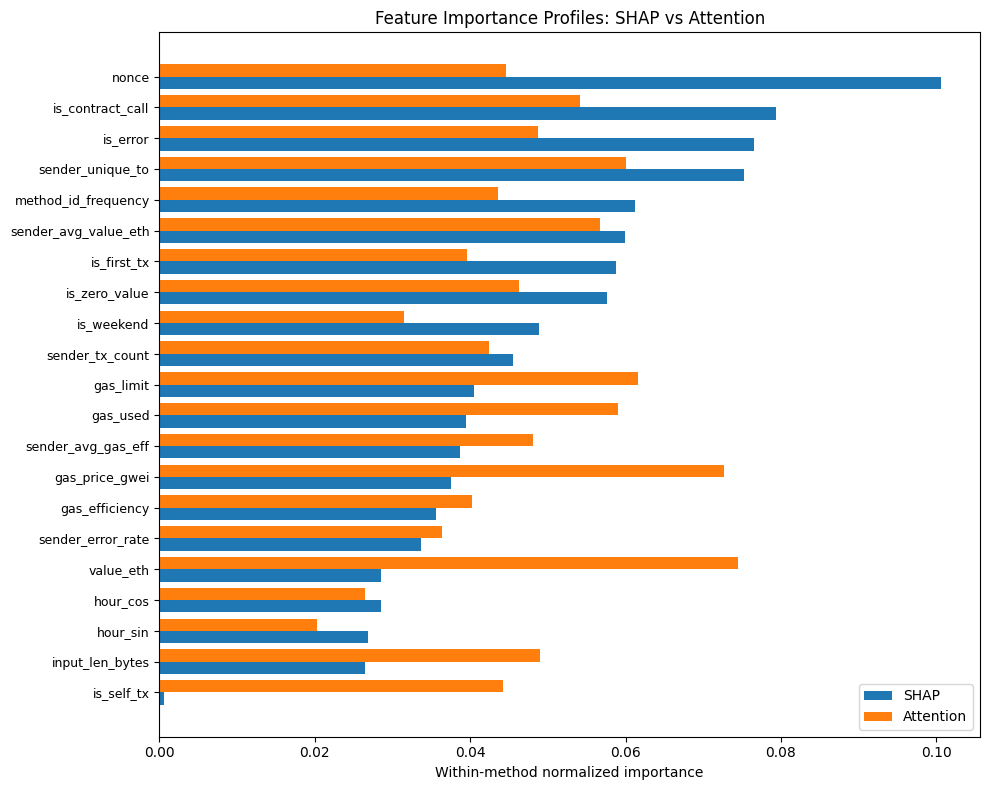

In [ ]:
# ============================================================
# Within-method normalization
# ============================================================

shap_vals = (
    importance
    .set_index("feature")["shap_importance"]
)

att_vals = (
    att_importance
    .set_index("feature")["attention_importance"]
)

# Normalize each method independently so that its values sum to 1
shap_norm = shap_vals / shap_vals.sum()
att_norm = att_vals / att_vals.sum()

# Sort features by SHAP importance for visualization
features_sorted = (
    shap_norm
    .sort_values(ascending=True)
    .index
)

shap_sorted = shap_norm.loc[features_sorted]
att_sorted = att_norm.loc[features_sorted]


# ============================================================
# Visualization
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

y = np.arange(len(features_sorted))
height = 0.4

ax.barh(
    y,
    shap_sorted.values,
    height=height,
    label="SHAP"
)

ax.barh(
    y + height,
    att_sorted.values,
    height=height,
    label="Attention"
)

ax.set_yticks(y + height / 2)
ax.set_yticklabels(
    features_sorted,
    fontsize=9
)

ax.set_xlabel("Within-method normalized importance")
ax.set_title("Feature Importance Profiles: SHAP vs Attention")

ax.legend()

plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/explainability_comparison/"
            "73_feature_importance_bar.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

**Spearman Rank Correlation**

In [ ]:
rho, pvalue = spearmanr(
    comparison["shap_rank"],
    comparison["attention_rank"]
)

alpha = 0.05

print(f"Spearman rank correlation (rho): {rho:.4f}")
print(f"p-value: {pvalue:.4f}")

if pvalue < alpha:
    print(
        "The rank correlation is statistically significant "
        "(p < 0.05)."
    )
else:
    print(
        "The rank correlation is not statistically significant "
        "(p >= 0.05)."
    )

Spearman rank correlation (rho): 0.1948
p-value: 0.3974
The rank correlation is not statistically significant (p >= 0.05).


# 6 Comparison with other methods

## 6.1 Baseline autoencoder

The baseline autoencoder (Model 1) was defined, trained, and calibrated in Subsection 3.2.

For comparison with alternative anomaly detection methods, the reconstruction errors and the optimized Fraud-F1 threshold previously obtained on the Calibration set are reused. The Holdout Test set is not used at this stage.

In [ ]:
# Baseline Autoencoder (Model 1)
# Reuse the Calibration scores and the optimized threshold
# obtained in Section 3.2.

baseline_scores = calibration_mse_1
baseline_threshold = threshold_opt_1

baseline_pred = (
    baseline_scores >= baseline_threshold
).astype(int)

print("=== Baseline Autoencoder (Model 1) ===")
print(f"Optimized threshold: {baseline_threshold:.6f}")
print()

print("=== Calibration Classification Report ===")
print(
    classification_report(
        y_calibration,
        baseline_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, baseline_scores):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

baseline_cm = confusion_matrix(
    y_calibration,
    baseline_pred
)

print(baseline_cm)

=== Baseline Autoencoder (Model 1) ===
Optimized threshold: 1.868172

=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.80      0.33      0.47       697

    accuracy                           0.93      7203
   macro avg       0.87      0.66      0.71      7203
weighted avg       0.92      0.93      0.91      7203

AUC-ROC: 0.7353

=== Calibration Confusion Matrix ===
[[6449   57]
 [ 468  229]]


## 6.2 Variational Autoencoder

**Creating the VAE Model**

In [ ]:
# Reset random seed before model initialization
reset_seed(SEED)

# VAE configuration
input_dim = INPUT_DIM
latent_dim = 8
VAE_DROPOUT_RATE = 0.1
VAE_BETA = 0.2


# ============================================================
# Custom VAE layers
# ============================================================

@keras.utils.register_keras_serializable(package="ArticleAE")
class Sampling(layers.Layer):
    """Reparameterization layer: z = μ + σ·ε."""

    def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(z_mean)
        )

        return (
            z_mean
            + tf.exp(0.5 * z_log_var) * epsilon
        )

    def get_config(self):
        return super().get_config()


@keras.utils.register_keras_serializable(package="ArticleAE")
class VAELoss(layers.Layer):
    """
    Adds the VAE loss:
    reconstruction loss + beta * KL divergence.
    """

    def __init__(self, beta=0.2, **kwargs):
        super().__init__(**kwargs)
        self.beta = beta

    def call(self, inputs):
        x, x_decoded, z_mean, z_log_var = inputs

        # Reconstruction loss:
        # mean squared reconstruction error
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_mean(
                tf.square(x - x_decoded),
                axis=1
            )
        )

        # KL divergence:
        # averaged over latent dimensions and samples
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_mean(
                1
                + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = (
            reconstruction_loss
            + self.beta * kl_loss
        )

        self.add_loss(total_loss)

        return x_decoded

    def get_config(self):
        config = super().get_config()

        config.update({
            "beta": self.beta
        })

        return config


# ============================================================
# Encoder
# ============================================================

inputs_vae = keras.Input(
    shape=(input_dim,),
    name="input"
)

encoder_dense_64 = layers.Dense(
    64,
    activation="relu",
    name="encoder_dense_64"
)

encoder_dropout_1 = layers.Dropout(
    VAE_DROPOUT_RATE,
    name="encoder_dropout_1"
)

encoder_dense_32 = layers.Dense(
    32,
    activation="relu",
    name="encoder_dense_32"
)

encoder_dropout_2 = layers.Dropout(
    VAE_DROPOUT_RATE,
    name="encoder_dropout_2"
)

encoder_dense_16 = layers.Dense(
    16,
    activation="relu",
    name="encoder_dense_16"
)


x = encoder_dense_64(inputs_vae)
x = encoder_dropout_1(x)
x = encoder_dense_32(x)
x = encoder_dropout_2(x)
x = encoder_dense_16(x)


# Latent distribution parameters
z_mean = layers.Dense(
    latent_dim,
    name="z_mean"
)(x)

z_log_var = layers.Dense(
    latent_dim,
    name="z_log_var"
)(x)


# Stochastic latent representation used during VAE training
z = Sampling(
    name="sampling"
)([z_mean, z_log_var])


# ============================================================
# Decoder layers
# ============================================================

decoder_dense_16 = layers.Dense(
    16,
    activation="relu",
    name="decoder_dense_16"
)

decoder_dropout_1 = layers.Dropout(
    VAE_DROPOUT_RATE,
    name="decoder_dropout_1"
)

decoder_dense_32 = layers.Dense(
    32,
    activation="relu",
    name="decoder_dense_32"
)

decoder_dropout_2 = layers.Dropout(
    VAE_DROPOUT_RATE,
    name="decoder_dropout_2"
)

decoder_dense_64 = layers.Dense(
    64,
    activation="relu",
    name="decoder_dense_64"
)

decoder_output_layer = layers.Dense(
    input_dim,
    activation="linear",
    name="decoder_output"
)


# Stochastic decoding path used during training
x_decoded = decoder_dense_16(z)
x_decoded = decoder_dropout_1(x_decoded)
x_decoded = decoder_dense_32(x_decoded)
x_decoded = decoder_dropout_2(x_decoded)
x_decoded = decoder_dense_64(x_decoded)

decoder_output = decoder_output_layer(
    x_decoded
)


# ============================================================
# VAE training loss
# ============================================================

outputs_vae = VAELoss(
    beta=VAE_BETA,
    name="vae_loss"
)(
    [
        inputs_vae,
        decoder_output,
        z_mean,
        z_log_var
    ]
)


# ============================================================
# Full VAE model
# ============================================================

vae = keras.Model(
    inputs=inputs_vae,
    outputs=outputs_vae,
    name="variational_autoencoder"
)

vae.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )
)


# ============================================================
# Deterministic inference model
# ============================================================

# For anomaly detection, use z_mean instead of stochastic
# latent sampling to obtain reproducible reconstruction errors.

x_inference = decoder_dense_16(z_mean)
x_inference = decoder_dropout_1(
    x_inference,
    training=False
)

x_inference = decoder_dense_32(
    x_inference
)

x_inference = decoder_dropout_2(
    x_inference,
    training=False
)

x_inference = decoder_dense_64(
    x_inference
)

inference_output = decoder_output_layer(
    x_inference
)


vae_inference = keras.Model(
    inputs=inputs_vae,
    outputs=inference_output,
    name="vae_inference"
)


# ============================================================
# Model summary
# ============================================================

vae.summary()

Model: "variational_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 21)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_64    │ (None, 64)        │      1,408 │ input[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout_1   │ (None, 64)        │          0 │ encoder_dense_64… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_32    │ (None, 32)        │      2,080 │ encoder_dropout_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout_2   │ (None, 32)        │          0 │ encoder_dense_32… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dense_16    │ (None, 16)        │        528 │ encoder_dropout_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 8)         │        136 │ encoder_dense_16… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 8)         │        136 │ encoder_dense_16… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 8)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_16    │ (None, 16)        │        144 │ sampling[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout_1   │ (None, 16)        │          0 │ decoder_dense_16… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_32    │ (None, 32)        │        544 │ decoder_dropout_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout_2   │ (None, 32)        │          0 │ decoder_dense_32… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense_64    │ (None, 64)        │      2,112 │ decoder_dropout_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 21)        │      1,365 │ decoder_dense_64… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vae_loss (VAELoss)  │ (None, 21)        │          0 │ input[0][0],      │
│                     │                   │            │ decoder_output[0… │
│                     │                   │            │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,453 (33.02 KB)

 Trainable params: 8,453 (33.02 KB)

 Non-trainable params: 0 (0.00 B)

**Training the VAE Model**

In [ ]:
early_stopping_vae = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOP_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

history_vae = vae.fit(
    x=X_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val,),
    callbacks=[
        early_stopping_vae
    ],
    shuffle=True,
    verbose=1
)

print()
print(
    f"VAE training completed after "
    f"{len(history_vae.history['loss'])} epochs."
)

print(
    f"Best validation loss: "
    f"{min(history_vae.history['val_loss']):.6f}"
)

Epoch 1/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 1.1774 - val_loss: 0.8108
Epoch 2/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.8254 - val_loss: 0.6486
Epoch 3/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.7268 - val_loss: 0.6007
Epoch 4/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.6872 - val_loss: 0.5703
Epoch 5/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.6574 - val_loss: 0.5406
Epoch 6/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.6316 - val_loss: 0.4960
Epoch 7/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5944 - val_loss: 0.4654
Epoch 8/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.5731 - val_loss: 0.4533
Epoch 9/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5499 - val_loss: 0.4321
Epoch 10/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5372 - val_loss: 0.4239
Epoch 11/300
238/238 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.5105 - val_loss: 0.4136
Epoch 12/300
238/238 ━━━━━━━━━━━━━━━━

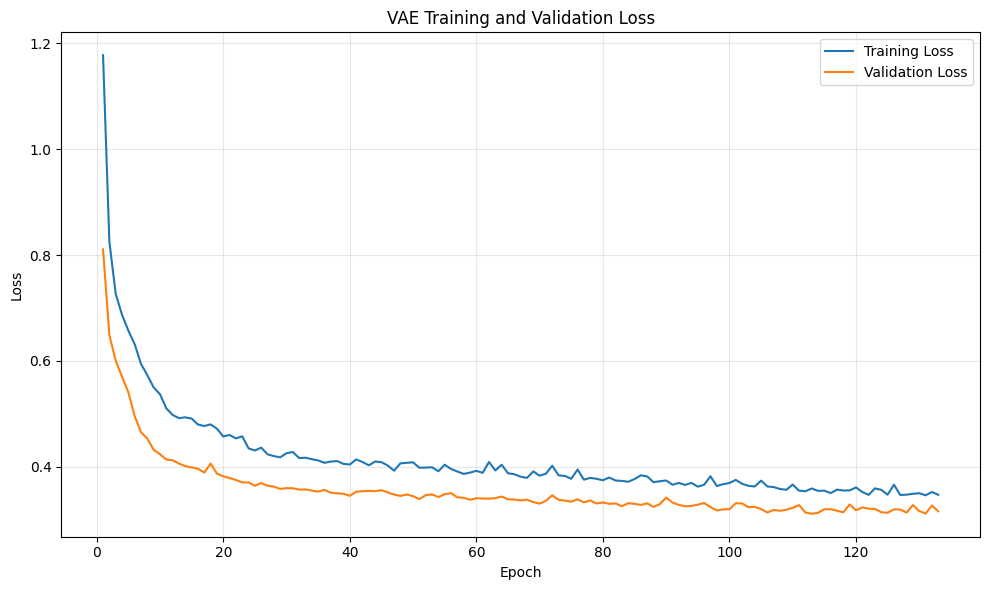

In [ ]:
# Plot VAE training and validation loss

epochs_ran = range(
    1,
    len(history_vae.history["loss"]) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_ran,
    history_vae.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_ran,
    history_vae.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

if SAVE_ARTIFACTS:
    plt.savefig(
        save_path(
            "results/alternative_methods/"
            "83_vae_training_history.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

**Saving the Trained VAE Model**

In [ ]:
# ============================================================
# Save VAE models and weights
# ============================================================

if SAVE_ARTIFACTS:
    VAE_MODEL_PATH = save_path(
        "models/alternative_methods/"
        "84_vae_model.keras"
    )

    VAE_WEIGHTS_PATH = save_path(
        "models/alternative_methods/"
        "85_vae_model.weights.h5"
    )

    VAE_INFERENCE_PATH = save_path(
        "models/alternative_methods/"
        "86_vae_inference.keras"
    )


    # Save the complete VAE model
    # Includes architecture, trained weights, and optimizer state.
    vae.save(VAE_MODEL_PATH)


    # Save VAE weights separately
    vae.save_weights(VAE_WEIGHTS_PATH)


    # Save the deterministic inference model
    # This model uses z_mean instead of stochastic sampling.
    vae_inference.save(VAE_INFERENCE_PATH)


    print(f"VAE model saved to: {VAE_MODEL_PATH}")
    print(f"VAE weights saved to: {VAE_WEIGHTS_PATH}")
    print(f"VAE inference model saved to: {VAE_INFERENCE_PATH}")

**Evaluating the VAE Model**

In [ ]:
# ============================================================
# Evaluate VAE on the Calibration set
# ============================================================

# Obtain deterministic reconstructions using z_mean
calibration_recon_vae = vae_inference.predict(
    X_calibration,
    verbose=0
)

# Calculate reconstruction error for each transaction
calibration_mse_vae = np.mean(
    np.square(
        X_calibration - calibration_recon_vae
    ),
    axis=1
)


# ============================================================
# Fraud-F1-optimized threshold
# ============================================================

threshold_opt_vae, best_f1_vae = select_f1_optimal_threshold(
    y_calibration,
    calibration_mse_vae
)

print(f"Optimized threshold: {threshold_opt_vae:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_vae:.4f}")
print()


# ============================================================
# Predictions
# ============================================================

y_pred_vae = (
    calibration_mse_vae >= threshold_opt_vae
).astype(int)


# ============================================================
# Classification metrics
# ============================================================

print("=== Variational Autoencoder ===")
print("=== Calibration Classification Report ===")

print(
    classification_report(
        y_calibration,
        y_pred_vae,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

auc_roc_vae = roc_auc_score(
    y_calibration,
    calibration_mse_vae
)

print(f"AUC-ROC: {auc_roc_vae:.4f}")


# ============================================================
# Confusion matrix
# ============================================================

print()
print("=== Calibration Confusion Matrix ===")

cm_vae = confusion_matrix(
    y_calibration,
    y_pred_vae
)

print(cm_vae)

Optimized threshold: 0.965378
Best Calibration Fraud F1: 0.4586

=== Variational Autoencoder ===
=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.93      0.99      0.96      6506
       Fraud       0.75      0.33      0.46       697

    accuracy                           0.92      7203
   macro avg       0.84      0.66      0.71      7203
weighted avg       0.91      0.92      0.91      7203

AUC-ROC: 0.7757

=== Calibration Confusion Matrix ===
[[6430   76]
 [ 467  230]]


In [ ]:
# ============================================================
# Store VAE metrics for method comparison
# ============================================================

precision_vae = precision_score(
    y_calibration,
    y_pred_vae,
    pos_label=1,
    zero_division=0
)

recall_vae = recall_score(
    y_calibration,
    y_pred_vae,
    pos_label=1,
    zero_division=0
)

f1_vae = f1_score(
    y_calibration,
    y_pred_vae,
    pos_label=1,
    zero_division=0
)

print("=== VAE Calibration Metrics ===")
print(f"AUC-ROC:        {auc_roc_vae:.4f}")
print(f"Fraud Recall:   {recall_vae:.4f}")
print(f"Fraud Precision:{precision_vae:.4f}")
print(f"Fraud F1:       {f1_vae:.4f}")

=== VAE Calibration Metrics ===
AUC-ROC:        0.7757
Fraud Recall:   0.3300
Fraud Precision:0.7516
Fraud F1:       0.4586


## 6.3 Isolation Forest

In [ ]:
# Train Isolation Forest on normal transactions only.
# The built-in decision threshold is not used because
# the anomaly-score threshold is calibrated separately.

iso_forest = IsolationForest(
    contamination="auto",
    random_state=SEED
)

iso_forest.fit(X_train)


# ============================================================
# Anomaly scores on the Calibration set
# ============================================================

# sklearn IsolationForest assigns lower scores
# to more anomalous observations.
# Negate the scores so that larger values correspond
# to a higher degree of anomaly.

calibration_score_if = -iso_forest.score_samples(
    X_calibration
)


# ============================================================
# Fraud-F1-optimized threshold
# ============================================================

threshold_opt_if, best_f1_if = select_f1_optimal_threshold(
    y_calibration,
    calibration_score_if
)

print(f"Optimized threshold: {threshold_opt_if:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_if:.4f}")
print()


# ============================================================
# Evaluation on the Calibration set
# ============================================================

y_pred_if = (
    calibration_score_if >= threshold_opt_if
).astype(int)

print("=== Isolation Forest ===")
print("=== Calibration Classification Report ===")

print(
    classification_report(
        y_calibration,
        y_pred_if,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_score_if):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_if = confusion_matrix(
    y_calibration,
    y_pred_if
)

print(cm_if)

Optimized threshold: 0.449711
Best Calibration Fraud F1: 0.2643

=== Isolation Forest ===
=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.96      0.58      0.72      6506
       Fraud       0.16      0.75      0.26       697

    accuracy                           0.60      7203
   macro avg       0.56      0.66      0.49      7203
weighted avg       0.88      0.60      0.68      7203

AUC-ROC: 0.7021

=== Calibration Confusion Matrix ===
[[3775 2731]
 [ 175  522]]


**Saving**

In [ ]:
# ============================================================
# Save Isolation Forest model and calibrated threshold
# ============================================================

if SAVE_ARTIFACTS:
    ISOLATION_FOREST_PATH = save_path(
        "models/alternative_methods/"
        "81_isolation_forest.pkl"
    )

    isolation_forest_artifact = {
        "model": iso_forest,
        "threshold": threshold_opt_if
    }

    joblib.dump(
        isolation_forest_artifact,
        ISOLATION_FOREST_PATH
    )

    print(
        f"Isolation Forest model and threshold saved to: "
        f"{ISOLATION_FOREST_PATH}"
    )

## 6.4 Local Outlier Factor

In [ ]:
# Train Local Outlier Factor on normal transactions only.
# novelty=True allows scoring previously unseen transactions.
# The built-in decision threshold is not used because
# the anomaly-score threshold is calibrated separately.

lof = LocalOutlierFactor(
    contamination="auto",
    novelty=True
)

lof.fit(X_train)


# ============================================================
# Anomaly scores on the Calibration set
# ============================================================

# sklearn LOF assigns lower scores to more anomalous observations.
# Negate the scores so that larger values correspond
# to a higher degree of anomaly.

calibration_score_lof = -lof.score_samples(
    X_calibration
)


# ============================================================
# Fraud-F1-optimized threshold
# ============================================================

threshold_opt_lof, best_f1_lof = select_f1_optimal_threshold(
    y_calibration,
    calibration_score_lof
)

print(f"Optimized threshold: {threshold_opt_lof:.6f}")
print(f"Best Calibration Fraud F1: {best_f1_lof:.4f}")
print()


# ============================================================
# Evaluation on the Calibration set
# ============================================================

y_pred_lof = (
    calibration_score_lof >= threshold_opt_lof
).astype(int)

print("=== Local Outlier Factor ===")
print("=== Calibration Classification Report ===")

print(
    classification_report(
        y_calibration,
        y_pred_lof,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print(
    f"AUC-ROC: "
    f"{roc_auc_score(y_calibration, calibration_score_lof):.4f}"
)

print()
print("=== Calibration Confusion Matrix ===")

cm_lof = confusion_matrix(
    y_calibration,
    y_pred_lof
)

print(cm_lof)

Optimized threshold: 1.137897
Best Calibration Fraud F1: 0.3011

=== Local Outlier Factor ===
=== Calibration Classification Report ===
              precision    recall  f1-score   support

      Normal       0.98      0.56      0.71      6506
       Fraud       0.18      0.91      0.30       697

    accuracy                           0.59      7203
   macro avg       0.58      0.73      0.51      7203
weighted avg       0.90      0.59      0.67      7203

AUC-ROC: 0.7351

=== Calibration Confusion Matrix ===
[[3637 2869]
 [  65  632]]


**Saving**

In [ ]:
# ============================================================
# Save Local Outlier Factor model and calibrated threshold
# ============================================================

if SAVE_ARTIFACTS:
    LOF_MODEL_PATH = save_path(
        "models/alternative_methods/"
        "82_lof_model.pkl"
    )

    lof_artifact = {
        "model": lof,
        "threshold": threshold_opt_lof
    }

    joblib.dump(
        lof_artifact,
        LOF_MODEL_PATH
    )

    print(
        f"LOF model and threshold saved to: "
        f"{LOF_MODEL_PATH}"
    )

## 6.5 Results and Conclusions

**Results**

In [ ]:
# ============================================================
# Comparison of anomaly detection methods
# ============================================================

def collect_metrics(
    method_name,
    scores,
    y_true,
    threshold
):
    """
    Calculate anomaly detection metrics using
    a threshold calibrated on the Calibration set.
    """

    y_pred = (
        scores >= threshold
    ).astype(int)

    return {
        "Method": method_name,

        "AUC-ROC": roc_auc_score(
            y_true,
            scores
        ),

        "Fraud Recall": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "Fraud Precision": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "Fraud F1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        )
    }


# ============================================================
# Collect Calibration metrics
# ============================================================

comparison_rows = [

    collect_metrics(
        "Baseline AE (Model 1)",
        calibration_mse_1,
        y_calibration,
        threshold_opt_1
    ),

    collect_metrics(
        "VAE",
        calibration_mse_vae,
        y_calibration,
        threshold_opt_vae
    ),

    collect_metrics(
        "Isolation Forest",
        calibration_score_if,
        y_calibration,
        threshold_opt_if
    ),

    collect_metrics(
        "LOF",
        calibration_score_lof,
        y_calibration,
        threshold_opt_lof
    ),

    collect_metrics(
        "AE + Attention (Model 6)",
        calibration_mse_6,
        y_calibration,
        threshold_opt_6
    )
]


# ============================================================
# Comparison table
# ============================================================

df_comparison = pd.DataFrame(
    comparison_rows
)

print(
    "=== Calibration Set: Method Comparison ==="
)

print(
    df_comparison
    .round(4)
    .to_string(index=False)
)


# ============================================================
# Styled table for notebook display
# ============================================================

metric_columns = [
    "AUC-ROC",
    "Fraud Recall",
    "Fraud Precision",
    "Fraud F1"
]

df_styled = (
    df_comparison.style
    .highlight_max(
        subset=metric_columns,
        color="lightgreen"
    )
    .set_caption(
        "Comparison of Anomaly Detection Methods "
        "on the Calibration Set"
    )
    .format({
        column: "{:.4f}"
        for column in metric_columns
    })
)


# ============================================================
# Save comparison results
# ============================================================

if SAVE_ARTIFACTS:
    df_comparison.to_csv(
        save_path(
            "results/alternative_methods/"
            "87_method_comparison.csv"
        ),
        index=False
    )

df_styled

=== Calibration Set: Method Comparison ===
                  Method  AUC-ROC  Fraud Recall  Fraud Precision  Fraud F1
   Baseline AE (Model 1)   0.7353        0.3286           0.8007    0.4659
                     VAE   0.7757        0.3300           0.7516    0.4586
        Isolation Forest   0.7021        0.7489           0.1605    0.2643
                     LOF   0.7351        0.9067           0.1805    0.3011
AE + Attention (Model 6)   0.8420        0.4275           0.5399    0.4772


,Method,AUC-ROC,Fraud Recall,Fraud Precision,Fraud F1
0,Baseline AE (Model 1),0.7353,0.3286,0.8007,0.4659
1,VAE,0.7757,0.3300,0.7516,0.4586
2,Isolation Forest,0.7021,0.7489,0.1605,0.2643
3,LOF,0.7351,0.9067,0.1805,0.3011
4,AE + Attention (Model 6),0.8420,0.4275,0.5399,0.4772


**Conclusions**

The comparison on the Calibration set showed that AE + Attention (Model No. 6) achieved the highest AUC-ROC (0.8420) and Fraud F1 (0.4772) among all methods considered. Its Fraud Recall was 0.4275, exceeding the results of the baseline AE (0.3286) and VAE (0.3300), while its Fraud Precision (0.5399) was lower than that of these two methods.

The baseline AE demonstrated the highest Fraud Precision (0.8007); however, its Fraud Recall was only 0.3286 and its AUC-ROC was 0.7353. The VAE achieved AUC-ROC = 0.7757, Fraud Recall = 0.3300, Fraud Precision = 0.7516, and Fraud F1 = 0.4586, underperforming Model No. 6 in terms of AUC-ROC, Fraud Recall, and Fraud F1.

Isolation Forest and LOF demonstrated substantially higher Fraud Recall values of 0.7489 and 0.9067, respectively. However, this was accompanied by low Fraud Precision values of 0.1605 and 0.1805 and corresponding Fraud F1 values of 0.2643 and 0.3011. These results indicate operating points that are substantially shifted toward high anomaly-detection recall at the cost of a large number of false positives.

Thus, none of the methods considered outperforms all others across all metrics simultaneously. Given the prioritization of metrics adopted in this study, Model No. 6 demonstrated the best overall result: the highest threshold-independent AUC-ROC and the highest Fraud F1, as well as higher Fraud Recall compared with the baseline AE and VAE. These results confirm the previously made choice of Model No. 6 as the final architecture.

The Holdout Test set was not used either for method selection or threshold optimization. Therefore, the architecture, hyperparameters, and calibrated decision threshold of Model No. 6 remained fixed until the final evaluation on the Holdout Test set.

# 7 Final Evaluation on the Holdout Test Set

After completion of model selection and comparison on the Calibration set, Model 6, its architecture, hyperparameters, and decision threshold were fixed. The Holdout Test set was then used for the final independent evaluation.

In [ ]:
# ------------------------------------------------------------
# Holdout Test data
# ------------------------------------------------------------

X_holdout_test = holdout_test_features[
    feature_cols
].to_numpy(dtype=np.float32)

y_holdout_test = holdout_test_features[
    "label"
].to_numpy(dtype=int)

assert X_holdout_test.shape == (7204, 21)
assert np.sum(y_holdout_test == 0) == 6507
assert np.sum(y_holdout_test == 1) == 697


# ------------------------------------------------------------
# Obtain reconstructions for the Holdout Test set
# ------------------------------------------------------------

holdout_recon_6 = model_6.predict(
    X_holdout_test,
    batch_size=256,
    verbose=0
)


# ------------------------------------------------------------
# Calculate reconstruction error for each transaction
# ------------------------------------------------------------

holdout_mse_6 = np.mean(
    np.square(
        X_holdout_test - holdout_recon_6
    ),
    axis=1
)


# ------------------------------------------------------------
# Apply the threshold previously selected
# on the Calibration set
# ------------------------------------------------------------

y_pred_holdout_6 = (
    holdout_mse_6 >= threshold_opt_6
).astype(int)


# ============================================================
# Final Holdout Test metrics
# ============================================================

print(
    "=== Model 6: Final Holdout Test Evaluation ==="
)

print()

print(
    classification_report(
        y_holdout_test,
        y_pred_holdout_6,
        target_names=[
            "Normal",
            "Fraud"
        ],
        zero_division=0
    )
)

holdout_auc_roc_6 = roc_auc_score(
    y_holdout_test,
    holdout_mse_6
)

print(
    f"AUC-ROC: "
    f"{holdout_auc_roc_6:.4f}"
)

print()

print(
    "=== Holdout Test Confusion Matrix ==="
)

cm_holdout_6 = confusion_matrix(
    y_holdout_test,
    y_pred_holdout_6
)

print(
    cm_holdout_6
)

=== Model 6: Final Holdout Test Evaluation ===

              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95      6507
       Fraud       0.57      0.46      0.51       697

    accuracy                           0.91      7204
   macro avg       0.76      0.71      0.73      7204
weighted avg       0.91      0.91      0.91      7204

AUC-ROC: 0.8489

=== Holdout Test Confusion Matrix ===
[[6267  240]
 [ 378  319]]


In [ ]:
# ============================================================
# Store final Holdout Test metrics
# ============================================================

holdout_precision_6 = precision_score(
    y_holdout_test,
    y_pred_holdout_6,
    pos_label=1,
    zero_division=0
)

holdout_recall_6 = recall_score(
    y_holdout_test,
    y_pred_holdout_6,
    pos_label=1,
    zero_division=0
)

holdout_f1_6 = f1_score(
    y_holdout_test,
    y_pred_holdout_6,
    pos_label=1,
    zero_division=0
)

print("=== Final Model 6 Holdout Test Metrics ===")
print(f"AUC-ROC:         {holdout_auc_roc_6:.4f}")
print(f"Fraud Recall:    {holdout_recall_6:.4f}")
print(f"Fraud Precision: {holdout_precision_6:.4f}")
print(f"Fraud F1:        {holdout_f1_6:.4f}")
print(f"Threshold:       {threshold_opt_6:.6f}")

=== Final Model 6 Holdout Test Metrics ===
AUC-ROC:         0.8489
Fraud Recall:    0.4577
Fraud Precision: 0.5707
Fraud F1:        0.5080
Threshold:       0.246948


For an additional assessment of the sampling uncertainty of the obtained metrics, a stratified bootstrap evaluation is performed in Subsection 8.4.

# 8 Additional Checks

Checks 8.1–8.5 are conducted as post-hoc exploratory analyses without changing the model architecture, its parameters, or the selected threshold. Subsection 8.4 separately assesses the sampling uncertainty of the final Holdout metrics.

## 8.1 Variability of Attention Mechanism Weights

### 8.1.1 Task

**Statement (fact):**

In Model No. 6, the AttentionLayer receives the 16-dimensional hidden representation *h* after encoder_dense_3. For each transaction, the layer computes

$$s=tanh(hW+b), α=softmax(s)$$

, after which it forms the output representation

$$ \hat h=h\odot\alpha. $$

Thus, each transaction has its own 16-dimensional weight vector α, whose components sum to 1. However, the architecture alone does not imply that these weights differ substantially from the uniform distribution (1/16 = 0.0625) or vary noticeably across transactions. The current explainability analysis uses the output activations *h^*, rather than the *α* values directly.

**Hypothesis:**

The trained AttentionLayer of Model 6 produces non-uniform and transaction-specific attention weights; that is, the mechanism does not reduce to nearly uniform or practically constant scaling of the 16 components of the hidden representation.

**Procedure:**

For all 7,203 transactions in the Calibration set, directly reconstruct the *α* vectors from the trained parameters of the AttentionLayer and examine two independent properties.

The first is non-uniformity within an individual transaction. Useful measures include:

- maximum weight max(α_i);
- mean absolute deviation of the weights from the uniform value \(1/16\);
- normalized entropy

$$ H_{\mathrm{norm}}(\alpha)= -\frac{\sum_i\alpha_i\ln\alpha_i}{\ln16}. $$

For a strictly uniform distribution, it is equal to 1. The greater the concentration of the weights, the lower its value.

The second is variability across transactions. For this purpose:

- calculate the standard deviation of each of the 16 weights *α_i* across the Calibration set;
- estimate the mean distance of each *α* vector from the mean weight vector across the entire Calibration set.

Check: shape (7203, 16), finite values, weights within the range [0,1], and the sum of each row ≈ 1.

**Possible Results and Interpretations:**

- If the entropy is close to 1.0, max(*α*) is close to 0.0625, and the deviation from the uniform distribution is minimal, then the layer effectively performs almost no selective reweighting. This would weaken the interpretation of the AttentionLayer as a meaningful attention mechanism.

- If the weights are noticeably non-uniform but their standard deviation across transactions is practically zero, then the layer mainly performs static learned reweighting of the hidden-space components. In this case, it would not be possible to claim pronounced transaction-specific adaptation of attention.

- If the weights are both non-uniform within transactions and vary noticeably across transactions, the result would be consistent with the hypothesis: the AttentionLayer indeed implements input-dependent redistribution of relative weights among the components of the hidden representation.

- An intermediate result is also possible: for example, most components may vary only slightly, while several vary substantially. This would indicate that the adaptivity of attention is concentrated in only part of the hidden space.

### 8.1.2 Verification

**Reconstructing Attention Weights and Calculating the Metrics**

In [ ]:
# The AttentionLayer in Model 6 receives the 16-dimensional
# output of encoder_dense_3.
attention_layer = model_6.get_layer("attention")

hidden_model = keras.Model(
    inputs=model_6.input,
    outputs=model_6.get_layer("encoder_dense_3").output,
    name="model_6_pre_attention_representation"
)

# Extract the hidden representation h for the entire
# Calibration set.
X_hypothesis = np.asarray(
    X_calibration,
    dtype=np.float32
)

hidden_out = hidden_model.predict(
    X_hypothesis,
    batch_size=BATCH_SIZE,
    verbose=0
)

# ============================================================
# Reconstruct attention weights:
#
# s = tanh(hW + b)
# alpha = softmax(s)
# ============================================================

W = attention_layer.W.numpy()
b = attention_layer.b.numpy()

attention_scores = np.tanh(
    hidden_out @ W + b
)

attention_alpha = tf.nn.softmax(
    attention_scores,
    axis=1
).numpy()


# ============================================================
# Sanity checks
# ============================================================

n_samples, n_attention_units = attention_alpha.shape

assert n_samples == X_calibration.shape[0]
assert n_attention_units == 16
assert np.isfinite(attention_alpha).all()
assert np.all(attention_alpha >= 0.0)
assert np.all(attention_alpha <= 1.0)

row_sums = attention_alpha.sum(axis=1)

assert np.allclose(
    row_sums,
    1.0,
    atol=1e-6
), "Attention weights do not sum to 1."


# ============================================================
# Reference value for uniform attention
# ============================================================

uniform_weight = 1.0 / n_attention_units


# ============================================================
# 1. Non-uniformity within individual transactions
# ============================================================

max_alpha = attention_alpha.max(axis=1)

mean_abs_deviation_from_uniform = np.mean(
    np.abs(attention_alpha - uniform_weight),
    axis=1
)

# Normalized entropy:
# 1.0 = perfectly uniform attention
# lower values = more concentrated attention
eps = 1e-12

entropy = -np.sum(
    attention_alpha
    * np.log(attention_alpha + eps),
    axis=1
)

normalized_entropy = (
    entropy / np.log(n_attention_units)
)


# ============================================================
# 2. Variability across transactions
# ============================================================

alpha_mean_by_unit = attention_alpha.mean(axis=0)
alpha_std_by_unit = attention_alpha.std(axis=0)

mean_alpha_std = alpha_std_by_unit.mean()
max_alpha_std = alpha_std_by_unit.max()

# Distance of each transaction-specific attention vector
# from the global mean attention vector
distance_from_mean_alpha = np.linalg.norm(
    attention_alpha - alpha_mean_by_unit,
    axis=1
)


# ============================================================
# Summary
# ============================================================

print("=== Variability of Attention Weights ===")
print()

print("Attention weights shape:", attention_alpha.shape)
print(f"Uniform reference weight: {uniform_weight:.6f}")
print()

print("--- Non-uniformity within transactions ---")

print(
    f"Mean max(alpha): "
    f"{np.mean(max_alpha):.6f}"
)

print(
    f"Median max(alpha): "
    f"{np.median(max_alpha):.6f}"
)

print(
    f"Mean absolute deviation from uniform: "
    f"{np.mean(mean_abs_deviation_from_uniform):.6f}"
)

print(
    f"Median normalized entropy: "
    f"{np.median(normalized_entropy):.6f}"
)

print(
    f"Mean normalized entropy: "
    f"{np.mean(normalized_entropy):.6f}"
)

print(
    f"Normalized entropy range: "
    f"{np.min(normalized_entropy):.6f} "
    f"to {np.max(normalized_entropy):.6f}"
)

print()

print("--- Variability across transactions ---")

print(
    f"Mean std(alpha) across attention units: "
    f"{mean_alpha_std:.6f}"
)

print(
    f"Maximum std(alpha) among attention units: "
    f"{max_alpha_std:.6f}"
)

print(
    f"Mean distance from global mean alpha: "
    f"{np.mean(distance_from_mean_alpha):.6f}"
)

print(
    f"Median distance from global mean alpha: "
    f"{np.median(distance_from_mean_alpha):.6f}"
)


# ============================================================
# Per-unit summary
# ============================================================

attention_weight_summary = pd.DataFrame({
    "attention_unit": [
        f"attention_unit_{i + 1}"
        for i in range(n_attention_units)
    ],
    "mean_alpha": alpha_mean_by_unit,
    "std_alpha": alpha_std_by_unit,
    "min_alpha": attention_alpha.min(axis=0),
    "max_alpha": attention_alpha.max(axis=0)
})

print()
print("=== Per-Unit Attention Weight Summary ===")

print(
    attention_weight_summary
    .round(6)
    .to_string(index=False)
)

=== Variability of Attention Weights ===

Attention weights shape: (7203, 16)
Uniform reference weight: 0.062500

--- Non-uniformity within transactions ---
Mean max(alpha): 0.162601
Median max(alpha): 0.165754
Mean absolute deviation from uniform: 0.046625
Median normalized entropy: 0.877926
Mean normalized entropy: 0.881630
Normalized entropy range: 0.829347 to 0.934106

--- Variability across transactions ---
Mean std(alpha) across attention units: 0.032461
Maximum std(alpha) among attention units: 0.054689
Mean distance from global mean alpha: 0.142318
Median distance from global mean alpha: 0.146345

=== Per-Unit Attention Weight Summary ===
   attention_unit  mean_alpha  std_alpha  min_alpha  max_alpha
 attention_unit_1    0.109300   0.041153   0.019717   0.256760
 attention_unit_2    0.086658   0.050367   0.016469   0.207720
 attention_unit_3    0.022303   0.002879   0.015884   0.049111
 attention_unit_4    0.044714   0.033432   0.015884   0.159000
 attention_unit_5    0.028960 

**Distribution of Normalized Attention-Weight Entropy**

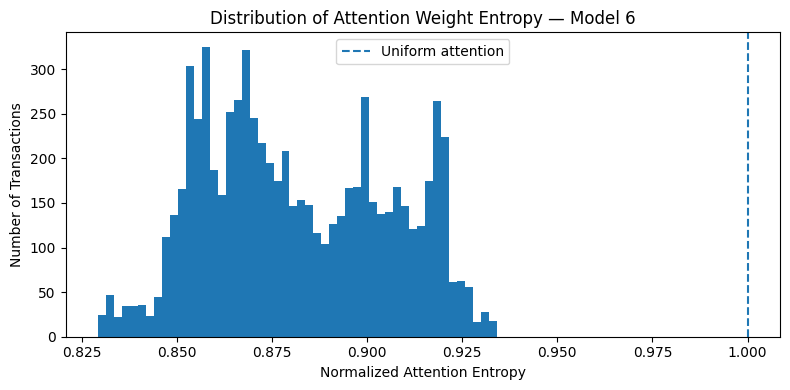

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    normalized_entropy,
    bins=50
)

ax.axvline(
    1.0,
    linestyle="--",
    label="Uniform attention"
)

ax.set_xlabel("Normalized Attention Entropy")
ax.set_ylabel("Number of Transactions")
ax.set_title(
    "Distribution of Attention Weight Entropy — Model 6"
)

ax.legend()

plt.tight_layout()
plt.show()

**Quantiles of Normalized Entropy and Maximum Attention Weight**

In [ ]:
quantiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

print("\n=== Normalized Entropy Quantiles ===")
for q in quantiles:
    print(
        f"Q{int(q * 100):02d}: "
        f"{np.quantile(normalized_entropy, q):.6f}"
    )

print("\n=== max(alpha) Quantiles ===")
for q in quantiles:
    print(
        f"Q{int(q * 100):02d}: "
        f"{np.quantile(max_alpha, q):.6f}"
    )


=== Normalized Entropy Quantiles ===
Q01: 0.833896
Q05: 0.847801
Q10: 0.852562
Q25: 0.861659
Q50: 0.877926
Q75: 0.901672
Q90: 0.917452
Q95: 0.920378
Q99: 0.927469

=== max(alpha) Quantiles ===
Q01: 0.122373
Q05: 0.133255
Q10: 0.135883
Q25: 0.147947
Q50: 0.165754
Q75: 0.176030
Q90: 0.187735
Q95: 0.191975
Q99: 0.204976


### 8.1.3 Result and Conclusion

**Result:**

The analysis of the AttentionLayer weights showed a pronounced deviation from the uniform distribution and noticeable variability across transactions. The median normalized entropy was 0.8779, while the median maximum weight was 0.1658, compared with the uniform reference value of 0.0625. The mean standard deviation of the weights across transactions was 0.0325, with individual components exhibiting a substantial range of values.

**Conclusion:**

The obtained results are consistent with the original hypothesis: the AttentionLayer produces non-uniform and transaction-specific attention weights. The observed distribution of *α* indicates pronounced adaptive reweighting of the components of the 16-dimensional hidden representation.

## 8.2 Comparison of Explainability Profiles for Normal and Fraud

### 8.2.1 Task

**Statement (fact):**

The main SHAP and AttentionLayer analyses were performed on the entire Calibration set — 7,203 transactions, including 6,506 Normal and 697 Fraud. SHAP characterizes the contribution of features to reconstruction error, while the AttentionLayer correlation analysis characterizes their linear relationships with the 16 components of the internal weighted representation. Since Normal transactions substantially predominate, aggregated rankings may conceal differences between the classes.

**Hypothesis:**

The model's explainability profiles differ between Normal and Fraud. The weak agreement between the global SHAP and AttentionLayer rankings (*ρ* = 0.1948) may be partly related to pooling two classes with different feature-importance structures and internal dependencies.

**Procedure:**

1. For SHAP, mean(|SHAP|) values are calculated separately for 6,506 Normal and 697 Fraud transactions, and feature rankings are constructed within each class. Since SHAP explains reconstruction error, absolute mean(|SHAP|) values cannot be directly interpreted across classes as differences in the "strength of importance"; the primary comparison is therefore based on feature ranks.
2. For the AttentionLayer, the mean absolute Pearson correlation of the 21 input features with the 16 output activations is calculated separately for Normal and Fraud.
3. The following are compared:
- SHAP Normal ↔ SHAP Fraud;
- Attention Normal ↔ Attention Fraud;
- SHAP ↔ Attention within Normal;
- SHAP ↔ Attention within Fraud.
4. The composition of the Top-5 features is additionally compared.

**Possible Results and Interpretations:**

- If SHAP and/or Attention rank features differently for Normal and Fraud, this indicates class-specific explainability profiles.
- If SHAP-Attention agreement within Fraud is noticeably higher than the global value (*ρ* = 0.1948), this would be consistent with the assumption that the pooled analysis partially conceals agreement between the methods specifically for the anomalous class.
- If the class-specific profiles differ, but SHAP–Attention agreement within Fraud remains weak, class specificity exists but does not explain the main discrepancy between the methods.
- If Normal and Fraud produce similar rankings and SHAP–Attention agreement remains weak in both classes, class pooling is not a substantial cause of the discrepancy.
- The Spearman p-value here refers to the presence of a rank association and does not test the statistical significance of the difference between two *ρ* coefficients.

### 8.2.2 Verification

**Preparing SHAP Values for Each Transaction**

In [ ]:
# ------------------------------------------------------------
# Prepare per-transaction SHAP values
# ------------------------------------------------------------

shap_array_h2 = np.asarray(
    shap_array
)

assert shap_array_h2.shape == (
    7203,
    21
)

assert np.isfinite(
    shap_array_h2
).all()

**Analysis of Class-Specific SHAP Profiles**

In [ ]:
# ------------------------------------------------------------
# Prepare Calibration data
# ------------------------------------------------------------

X_h2 = calibration_features[
    feature_cols
].to_numpy(dtype=np.float32)

y_h2 = calibration_features[
    "label"
].to_numpy(dtype=int)

assert X_h2.shape == (7203, 21)
assert np.sum(y_h2 == 0) == 6506
assert np.sum(y_h2 == 1) == 697

normal_mask_h2 = (
    y_h2 == 0
)

fraud_mask_h2 = (
    y_h2 == 1
)


# ------------------------------------------------------------
# Validate against canonical pooled SHAP importance
# ------------------------------------------------------------

pooled_shap_h2 = np.mean(
    np.abs(shap_array_h2),
    axis=0
)

pooled_shap_df_h2 = pd.DataFrame({
    "feature":
        feature_cols,

    "recomputed_shap_importance":
        pooled_shap_h2
})

shap_check_h2 = (
    importance[
        [
            "feature",
            "shap_importance"
        ]
    ]
    .merge(
        pooled_shap_df_h2,
        on="feature",
        how="inner",
        validate="one_to_one"
    )
)

shap_check_h2[
    "abs_difference"
] = np.abs(
    shap_check_h2[
        "shap_importance"
    ]
    - shap_check_h2[
        "recomputed_shap_importance"
    ]
)

max_shap_difference_h2 = (
    shap_check_h2[
        "abs_difference"
    ].max()
)

print(
    "Maximum pooled SHAP importance difference:",
    f"{max_shap_difference_h2:.10f}"
)

assert max_shap_difference_h2 < 1e-6, (
    "The per-transaction SHAP values do not "
    "reproduce the canonical Section 5.1 results."
)


# ------------------------------------------------------------
# Class-specific mean absolute SHAP values
# ------------------------------------------------------------

shap_normal_scores_h2 = np.mean(
    np.abs(
        shap_array_h2[
            normal_mask_h2
        ]
    ),
    axis=0
)

shap_fraud_scores_h2 = np.mean(
    np.abs(
        shap_array_h2[
            fraud_mask_h2
        ]
    ),
    axis=0
)


# ------------------------------------------------------------
# Rankings
# ------------------------------------------------------------

shap_normal_ranks_h2 = rankdata(
    -shap_normal_scores_h2,
    method="average"
)

shap_fraud_ranks_h2 = rankdata(
    -shap_fraud_scores_h2,
    method="average"
)


# ------------------------------------------------------------
# Normal vs Fraud SHAP agreement
# ------------------------------------------------------------

(
    rho_shap_classes_h2,
    p_shap_classes_h2
) = spearmanr(
    shap_normal_ranks_h2,
    shap_fraud_ranks_h2
)


# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

shap_comparison_h2 = pd.DataFrame({
    "feature":
        feature_cols,

    "shap_normal_score":
        shap_normal_scores_h2,

    "shap_normal_rank":
        shap_normal_ranks_h2,

    "shap_fraud_score":
        shap_fraud_scores_h2,

    "shap_fraud_rank":
        shap_fraud_ranks_h2
})

shap_comparison_h2[
    "shap_rank_change_fraud_minus_normal"
] = (
    shap_comparison_h2[
        "shap_fraud_rank"
    ]
    - shap_comparison_h2[
        "shap_normal_rank"
    ]
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print()
print(
    "=== Class-Specific SHAP Profiles ==="
)

print()

print(
    "SHAP Normal vs Fraud ranking: "
    f"rho = {rho_shap_classes_h2:.4f}, "
    f"p = {p_shap_classes_h2:.4g}"
)

print()

print(
    shap_comparison_h2
    .sort_values(
        "shap_fraud_rank"
    )
    .round(6)
    .to_string(index=False)
)

Maximum pooled SHAP importance difference: 0.0000000000

=== Class-Specific SHAP Profiles ===

SHAP Normal vs Fraud ranking: rho = 0.0974, p = 0.6745

             feature  shap_normal_score  shap_normal_rank  shap_fraud_score  shap_fraud_rank  shap_rank_change_fraud_minus_normal
            is_error           0.010710              20.0          0.301735              1.0                                -19.0
sender_avg_value_eth           0.017889              13.0          0.147979              2.0                                -11.0
    is_contract_call           0.032082               3.0          0.116905              3.0                                  0.0
      gas_price_gwei           0.012940              17.0          0.076436              4.0                                -13.0
               nonce           0.048839               1.0          0.072242              5.0                                  4.0
      gas_efficiency           0.014711              15.0          0.

**Comparison of SHAP and Attention Mechanisms Accounting for Class Specificity**

Calculating Attention for the Classes

In [ ]:
# ------------------------------------------------------------
# Extract AttentionLayer output
# ------------------------------------------------------------

attention_model_h2 = keras.Model(
    inputs=model_6.input,
    outputs=model_6.get_layer(
        "attention"
    ).output
)

attention_out_h2 = attention_model_h2.predict(
    X_h2,
    batch_size=256,
    verbose=0
)

assert attention_out_h2.shape == (
    7203,
    16
)


# ------------------------------------------------------------
# Mean absolute Pearson correlation between
# input features and AttentionLayer outputs
# ------------------------------------------------------------

def mean_abs_pearson_h2(
    X,
    representation
):

    scores = np.full(
        X.shape[1],
        np.nan,
        dtype=float
    )

    for j in range(
        X.shape[1]
    ):

        x = X[:, j]

        # Pearson correlation is undefined
        # for a constant feature.
        if np.isclose(
            np.std(x),
            0.0
        ):
            continue

        correlations = []

        for i in range(
            representation.shape[1]
        ):

            h = representation[:, i]

            if np.isclose(
                np.std(h),
                0.0
            ):
                continue

            corr = np.corrcoef(
                x,
                h
            )[0, 1]

            if np.isfinite(corr):
                correlations.append(
                    abs(corr)
                )

        if correlations:
            scores[j] = np.mean(
                correlations
            )

    return scores


# ------------------------------------------------------------
# Class-specific Attention scores
# ------------------------------------------------------------

attention_normal_scores_h2 = (
    mean_abs_pearson_h2(
        X_h2[
            normal_mask_h2
        ],
        attention_out_h2[
            normal_mask_h2
        ]
    )
)

attention_fraud_scores_h2 = (
    mean_abs_pearson_h2(
        X_h2[
            fraud_mask_h2
        ],
        attention_out_h2[
            fraud_mask_h2
        ]
    )
)


# ------------------------------------------------------------
# Identify features with undefined correlations
# ------------------------------------------------------------

undefined_normal_h2 = [
    feature_cols[i]
    for i in range(len(feature_cols))
    if not np.isfinite(
        attention_normal_scores_h2[i]
    )
]

undefined_fraud_h2 = [
    feature_cols[i]
    for i in range(len(feature_cols))
    if not np.isfinite(
        attention_fraud_scores_h2[i]
    )
]

Constructing and Comparing SHAP and Attention Rankings

In [ ]:
# ------------------------------------------------------------
# Ranking helper
# ------------------------------------------------------------

def rank_scores_h2(scores):

    ranks = np.full(
        len(scores),
        np.nan,
        dtype=float
    )

    valid = np.isfinite(
        scores
    )

    ranks[valid] = rankdata(
        -scores[valid],
        method="average"
    )

    return ranks


attention_normal_ranks_h2 = (
    rank_scores_h2(
        attention_normal_scores_h2
    )
)

attention_fraud_ranks_h2 = (
    rank_scores_h2(
        attention_fraud_scores_h2
    )
)


# ------------------------------------------------------------
# Safe rank comparison
# ------------------------------------------------------------

def compare_ranks_h2(
    ranks_a,
    ranks_b
):

    valid = (
        np.isfinite(ranks_a)
        & np.isfinite(ranks_b)
    )

    rho, p_value = spearmanr(
        ranks_a[valid],
        ranks_b[valid]
    )

    return (
        rho,
        p_value,
        int(np.sum(valid))
    )


# ------------------------------------------------------------
# Between-class agreement
# ------------------------------------------------------------

(
    rho_attention_classes_h2,
    p_attention_classes_h2,
    n_attention_classes_h2
) = compare_ranks_h2(
    attention_normal_ranks_h2,
    attention_fraud_ranks_h2
)


# ------------------------------------------------------------
# SHAP vs Attention within each class
# ------------------------------------------------------------

(
    rho_normal_methods_h2,
    p_normal_methods_h2,
    n_normal_methods_h2
) = compare_ranks_h2(
    shap_normal_ranks_h2,
    attention_normal_ranks_h2
)

(
    rho_fraud_methods_h2,
    p_fraud_methods_h2,
    n_fraud_methods_h2
) = compare_ranks_h2(
    shap_fraud_ranks_h2,
    attention_fraud_ranks_h2
)

Checking Consistency with the Global Estimates

In [ ]:
# ------------------------------------------------------------
# Pooled SHAP scores
# ------------------------------------------------------------

shap_all_scores_h2 = np.mean(
    np.abs(shap_array_h2),
    axis=0
)

shap_all_ranks_h2 = rank_scores_h2(
    shap_all_scores_h2
)


# ------------------------------------------------------------
# Pooled Attention scores
# ------------------------------------------------------------

attention_all_scores_h2 = (
    mean_abs_pearson_h2(
        X_h2,
        attention_out_h2
    )
)

attention_all_ranks_h2 = (
    rank_scores_h2(
        attention_all_scores_h2
    )
)


# ------------------------------------------------------------
# Validate pooled Attention against Section 5.2
# ------------------------------------------------------------

current_attention_h2 = pd.DataFrame({
    "feature":
        feature_cols,

    "current_attention_importance":
        attention_all_scores_h2
})

attention_check_h2 = (
    current_attention_h2
    .merge(
       att_importance[
            [
                "feature",
                "attention_importance"
            ]
        ],
        on="feature",
        how="inner",
        validate="one_to_one"
    )
)

attention_check_h2[
    "abs_difference"
] = np.abs(
    attention_check_h2[
        "current_attention_importance"
    ]
    - attention_check_h2[
        "attention_importance"
    ]
)

max_attention_difference_h2 = (
    attention_check_h2[
        "abs_difference"
    ].max()
)


# ------------------------------------------------------------
# Pooled SHAP-Attention agreement
# ------------------------------------------------------------

(
    rho_all_methods_h2,
    p_all_methods_h2,
    n_all_methods_h2
) = compare_ranks_h2(
    shap_all_ranks_h2,
    attention_all_ranks_h2
)


# ------------------------------------------------------------
# Top-5 helper
# ------------------------------------------------------------

def top_features_h2(
    features,
    ranks,
    k=5
):

    valid = np.isfinite(
        ranks
    )

    table = pd.DataFrame({
        "feature":
            np.asarray(features)[valid],

        "rank":
            ranks[valid]
    })

    return (
        table
        .sort_values("rank")
        .head(k)["feature"]
        .tolist()
    )


shap_normal_top5_h2 = top_features_h2(
    feature_cols,
    shap_normal_ranks_h2
)

attention_normal_top5_h2 = top_features_h2(
    feature_cols,
    attention_normal_ranks_h2
)

shap_fraud_top5_h2 = top_features_h2(
    feature_cols,
    shap_fraud_ranks_h2
)

attention_fraud_top5_h2 = top_features_h2(
    feature_cols,
    attention_fraud_ranks_h2
)


normal_top5_overlap_h2 = [
    feature
    for feature in shap_normal_top5_h2
    if feature in attention_normal_top5_h2
]

fraud_top5_overlap_h2 = [
    feature
    for feature in shap_fraud_top5_h2
    if feature in attention_fraud_top5_h2
]

**Final Table and Checks**

In [ ]:
# ------------------------------------------------------------
# Full comparison table
# ------------------------------------------------------------

comparison_h2 = pd.DataFrame({
    "feature":
        feature_cols,

    "shap_normal_score":
        shap_normal_scores_h2,

    "shap_normal_rank":
        shap_normal_ranks_h2,

    "shap_fraud_score":
        shap_fraud_scores_h2,

    "shap_fraud_rank":
        shap_fraud_ranks_h2,

    "attention_normal_score":
        attention_normal_scores_h2,

    "attention_normal_rank":
        attention_normal_ranks_h2,

    "attention_fraud_score":
        attention_fraud_scores_h2,

    "attention_fraud_rank":
        attention_fraud_ranks_h2
})


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "=== Class-Specific Explainability Comparison ==="
)

print()

print(
    "Undefined Attention scores in Normal:",
    undefined_normal_h2
)

print(
    "Undefined Attention scores in Fraud:",
    undefined_fraud_h2
)

print()

print(
    "--- Between-Class Agreement ---"
)

print(
    "SHAP Normal vs Fraud: "
    f"rho = {rho_shap_classes_h2:.4f}, "
    f"p = {p_shap_classes_h2:.4g}, "
    "n = 21"
)

print(
    "Attention Normal vs Fraud: "
    f"rho = {rho_attention_classes_h2:.4f}, "
    f"p = {p_attention_classes_h2:.4g}, "
    f"n = {n_attention_classes_h2}"
)

print()

print(
    "--- SHAP vs Attention Within Each Class ---"
)

print(
    "Normal: "
    f"rho = {rho_normal_methods_h2:.4f}, "
    f"p = {p_normal_methods_h2:.4g}, "
    f"n = {n_normal_methods_h2}"
)

print(
    "Fraud:  "
    f"rho = {rho_fraud_methods_h2:.4f}, "
    f"p = {p_fraud_methods_h2:.4g}, "
    f"n = {n_fraud_methods_h2}"
)

print()

print(
    "--- Consistency Checks ---"
)

print(
    "Maximum pooled Attention importance difference: "
    f"{max_attention_difference_h2:.10f}"
)

print(
    "All Calibration SHAP vs Attention: "
    f"rho = {rho_all_methods_h2:.4f}, "
    f"p = {p_all_methods_h2:.4g}, "
    f"n = {n_all_methods_h2}"
)

print()

print(
    "--- Top-5 Overlap ---"
)

print(
    "Normal SHAP Top-5:",
    shap_normal_top5_h2
)

print(
    "Normal Attention Top-5:",
    attention_normal_top5_h2
)

print(
    "Normal overlap:",
    normal_top5_overlap_h2,
    f"({len(normal_top5_overlap_h2)}/5)"
)

print()

print(
    "Fraud SHAP Top-5:",
    shap_fraud_top5_h2
)

print(
    "Fraud Attention Top-5:",
    attention_fraud_top5_h2
)

print(
    "Fraud overlap:",
    fraud_top5_overlap_h2,
    f"({len(fraud_top5_overlap_h2)}/5)"
)

print()

print(
    "=== Full Rank Comparison ==="
)

print(
    comparison_h2
    .sort_values(
        "shap_fraud_rank"
    )
    .round(6)
    .to_string(index=False)
)


# ------------------------------------------------------------
# Mandatory consistency checks
# ------------------------------------------------------------

assert max_attention_difference_h2 < 1e-8, (
    "The current Attention profile does not reproduce "
    "the canonical Section 5.2 results."
)

assert np.isclose(
    rho_all_methods_h2,
    0.1948,
    atol=5e-4
), (
    "The pooled SHAP-Attention ranking does not "
    "reproduce canonical rho = 0.1948."
)

assert np.isclose(
    p_all_methods_h2,
    0.3974,
    atol=5e-4
), (
    "The pooled SHAP-Attention comparison does not "
    "reproduce canonical p = 0.3974."
)

print()
print(
    "All consistency checks passed."
)

=== Class-Specific Explainability Comparison ===

Undefined Attention scores in Normal: []
Undefined Attention scores in Fraud: ['is_self_tx']

--- Between-Class Agreement ---
SHAP Normal vs Fraud: rho = 0.0974, p = 0.6745, n = 21
Attention Normal vs Fraud: rho = 0.0406, p = 0.865, n = 20

--- SHAP vs Attention Within Each Class ---
Normal: rho = 0.3714, p = 0.09736, n = 21
Fraud:  rho = 0.7173, p = 0.0003711, n = 20

--- Consistency Checks ---
Maximum pooled Attention importance difference: 0.0000000000
All Calibration SHAP vs Attention: rho = 0.1948, p = 0.3974, n = 21

--- Top-5 Overlap ---
Normal SHAP Top-5: ['nonce', 'sender_unique_to', 'is_contract_call', 'method_id_frequency', 'is_first_tx']
Normal Attention Top-5: ['value_eth', 'gas_limit', 'sender_unique_to', 'is_contract_call', 'gas_used']
Normal overlap: ['sender_unique_to', 'is_contract_call'] (2/5)

Fraud SHAP Top-5: ['is_error', 'sender_avg_value_eth', 'is_contract_call', 'gas_price_gwei', 'nonce']
Fraud Attention Top-5: 

### 8.2.3 Result and Conclusion

**Result:**

Separate analysis of Normal and Fraud revealed pronounced class specificity in both explainability profiles. Agreement between the SHAP rankings across the classes was virtually absent (*ρ* = 0.0974, p-value = 0.6745), with a similar result obtained for the AttentionLayer correlation estimates (*ρ* = 0.0406, p-value = 0.8650); 20 comparable features were used. Within the Normal class, agreement between SHAP and AttentionLayer was moderate but statistically non-significant (*ρ* = 0.3714, p-value = 0.0974). For Fraud, in contrast, a strong positive and statistically significant rank correlation was observed (*ρ* = 0.7173, p-value < 0.001). The Top-5 rankings for Fraud shared four features: is_error, sender_avg_value_eth, gas_price_gwei, and nonce. is_self_tx was constant within Fraud, so its Pearson correlation was undefined; the corresponding Attention comparisons were therefore performed using 20 features.

**Conclusion:**

The obtained results are consistent with the assumption that pooled analysis may conceal stronger agreement between the methods within the Fraud class. The weak global correlation does not imply an absence of agreement across all data subgroups: for Fraud, the two approaches demonstrate a strong positive rank correlation and identify a substantially overlapping set of the most important features.

## 8.3 Detection Robustness for Senders Absent from the Train Set

### 8.3.1 Task

**Statement (fact):**

The data split was performed at the level of individual transactions. Therefore, the Calibration set contains transactions from both senders previously present in the Train set and new senders. For senders absent from the Train set, the values of the five sender-level features are replaced with medians calculated exclusively from the Train set.

This is particularly important in the current Calibration set: unseen senders account for approximately 23.62% of Normal transactions but 75.32% of Fraud transactions.

**Hypothesis:**

The absence of sender history in the Train set is associated with differences in the detection characteristics of Model 6. At the same time, the model retains the ability to distinguish between Normal and Fraud among transactions from unseen senders, despite the replacement of sender-level features with Train-set medians.

**Procedure:**

The Calibration set is divided into two groups:

- seen sender — the sender was present in the Train set;
- unseen sender — the sender was absent from the Train set.

For both groups, using the same fixed Model 6 and the same t_opt = 0.246948, the following are compared:

- AUC-ROC;
- Fraud Recall;
- FPR;
- additionally, Precision and F1;
- reconstruction error distributions separately for Normal and Fraud.

Since t_opt was previously selected on the entire Calibration set, Recall, Precision, F1, and FPR for the seen/unseen subgroups are treated as post-hoc descriptive estimates rather than as an independent out-of-sample evaluation.

Particular attention is given to AUC-ROC, Recall, and FPR. Precision and F1 should be interpreted cautiously when comparing seen and unseen groups: the proportion of Fraud differs substantially between these groups, so Precision is strongly affected by the different class prevalence.

**Possible Results and Interpretations:**

- If AUC-ROC, Recall, and FPR for unseen senders are close to those for seen senders, this would indicate the absence of a pronounced degradation in performance on the Calibration set when sender history is unavailable.

- If reconstruction error is higher for unseen Normal transactions and FPR increases, this would be consistent with the idea that replacing sender-level features with medians makes accurate reconstruction of new senders more difficult.

- If reconstruction errors and Recall are higher for unseen Fraud transactions, this should not automatically be interpreted as the model "generalizing better": new fraudulent senders may simply differ more strongly from the normal Train distribution.

- If AUC-ROC and/or Fraud Recall decrease in the unseen-sender group, this would indicate a limitation in the model's applicability to new senders.

### 8.3.2 Verification

**Data Preparation and Identification of Seen/Unseen Senders**

In [ ]:
BATCH_SIZE_H3 = 256


# ------------------------------------------------------------
# Validate parsed transactions for sender-address recovery
# ------------------------------------------------------------

assert parsed_df["hash"].is_unique


# ------------------------------------------------------------
# Calibration data
# ------------------------------------------------------------

X_h3 = calibration_features[
    feature_cols
].to_numpy(dtype=np.float32)

y_h3 = calibration_features[
    "label"
].to_numpy(dtype=int)

assert X_h3.shape == (7203, 21)
assert np.sum(y_h3 == 0) == 6506
assert np.sum(y_h3 == 1) == 697


# ------------------------------------------------------------
# Restore sender addresses by transaction hash
# ------------------------------------------------------------

sender_by_hash_h3 = (
    parsed_df
    .set_index("hash")["from"]
)


train_sender_h3 = (
    train_features["hash"]
    .map(sender_by_hash_h3)
)

calibration_sender_h3 = (
    calibration_features["hash"]
    .map(sender_by_hash_h3)
)

assert train_sender_h3.notna().all()
assert calibration_sender_h3.notna().all()


# Normalize sender addresses
train_sender_h3 = (
    train_sender_h3
    .astype(str)
    .str.lower()
)

calibration_sender_h3 = (
    calibration_sender_h3
    .astype(str)
    .str.lower()
)


# ------------------------------------------------------------
# Seen / unseen sender status
# ------------------------------------------------------------

train_sender_set_h3 = set(
    train_sender_h3
)

seen_mask_h3 = (
    calibration_sender_h3
    .isin(train_sender_set_h3)
    .to_numpy()
)

unseen_mask_h3 = ~seen_mask_h3


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print()

print(
    "Seen sender transactions:",
    np.sum(seen_mask_h3)
)

print(
    "Unseen sender transactions:",
    np.sum(unseen_mask_h3)
)

print()

print(
    "Unseen Normal:",
    np.sum(
        unseen_mask_h3
        & (y_h3 == 0)
    ),
    "/",
    np.sum(y_h3 == 0)
)

print(
    "Unseen Fraud:",
    np.sum(
        unseen_mask_h3
        & (y_h3 == 1)
    ),
    "/",
    np.sum(y_h3 == 1)
)


assert np.sum(
    unseen_mask_h3
    & (y_h3 == 0)
) == 1537

assert np.sum(
    unseen_mask_h3
    & (y_h3 == 1)
) == 525


Seen sender transactions: 5141
Unseen sender transactions: 2062

Unseen Normal: 1537 / 6506
Unseen Fraud: 525 / 697


**Calculating Reconstruction Errors and Metrics**

In [ ]:
# ------------------------------------------------------------
# Reconstruction error
# ------------------------------------------------------------

reconstructed_h3 = model_6.predict(
    X_h3,
    batch_size=BATCH_SIZE_H3,
    verbose=0
)

reconstruction_error_h3 = np.mean(
    np.square(
        X_h3 - reconstructed_h3
    ),
    axis=1
)


# ------------------------------------------------------------
# Canonical AUC sanity check
# ------------------------------------------------------------

auc_all_h3 = roc_auc_score(
    y_h3,
    reconstruction_error_h3
)

print()

print(
    "Calibration AUC-ROC:",
    f"{auc_all_h3:.6f}"
)

assert np.isclose(
    auc_all_h3,
    0.841998,
    atol=5e-6
)


# ------------------------------------------------------------
# Performance helper
# ------------------------------------------------------------

def evaluate_sender_group_h3(mask):

    y = y_h3[mask]

    errors = reconstruction_error_h3[
        mask
    ]

    predictions = (
        errors >= threshold_opt_6
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1]
    ).ravel()

    auc = roc_auc_score(
        y,
        errors
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (
            np.isfinite(precision)
            and np.isfinite(recall)
            and (precision + recall) > 0
        )
        else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    return {
        "n": len(y),
        "normal": int(np.sum(y == 0)),
        "fraud": int(np.sum(y == 1)),
        "fraud_prevalence": np.mean(y == 1),

        "auc_roc": auc,
        "fraud_recall": recall,
        "fraud_precision": precision,
        "fraud_f1": f1,
        "fpr": fpr,

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


Calibration AUC-ROC: 0.841998


**Evaluating Detection Performance**

In [ ]:
# ------------------------------------------------------------
# Evaluate all groups
# ------------------------------------------------------------

results_all_h3 = evaluate_sender_group_h3(
    np.ones(
        len(y_h3),
        dtype=bool
    )
)

results_seen_h3 = evaluate_sender_group_h3(
    seen_mask_h3
)

results_unseen_h3 = evaluate_sender_group_h3(
    unseen_mask_h3
)


performance_h3 = pd.DataFrame(
    [
        {
            "group": "All Calibration",
            **results_all_h3
        },
        {
            "group": "Seen sender",
            **results_seen_h3
        },
        {
            "group": "Unseen sender",
            **results_unseen_h3
        }
    ]
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print()
print(
    "=== Detection Performance by Sender Status ==="
)

print()

print(
    performance_h3[
        [
            "group",
            "n",
            "normal",
            "fraud",
            "fraud_prevalence",
            "auc_roc",
            "fraud_recall",
            "fraud_precision",
            "fraud_f1",
            "fpr"
        ]
    ]
    .round(6)
    .to_string(index=False)
)

print()

print(
    "=== Confusion Matrices ==="
)

print()

for _, row in performance_h3.iterrows():

    print(row["group"])

    print(
        np.array([
            [row["tn"], row["fp"]],
            [row["fn"], row["tp"]]
        ]).astype(int)
    )

    print()


=== Detection Performance by Sender Status ===

          group    n  normal  fraud  fraud_prevalence  auc_roc  fraud_recall  fraud_precision  fraud_f1      fpr
All Calibration 7203    6506    697          0.096765 0.841998      0.427547         0.539855  0.477182 0.039041
    Seen sender 5141    4969    172          0.033457 0.773282      0.389535         0.249071  0.303855 0.040652
  Unseen sender 2062    1537    525          0.254607 0.844501      0.440000         0.816254  0.571782 0.033832

=== Confusion Matrices ===

All Calibration
[[6252  254]
 [ 399  298]]

Seen sender
[[4767  202]
 [ 105   67]]

Unseen sender
[[1485   52]
 [ 294  231]]



**Statistical comparison of reconstruction errors**

In [ ]:
# ------------------------------------------------------------
# Statistical comparison helper
# ------------------------------------------------------------

def compare_seen_unseen_errors_h3(
    class_label,
    class_name
):

    class_mask = (
        y_h3 == class_label
    )

    seen_errors = reconstruction_error_h3[
        class_mask
        & seen_mask_h3
    ]

    unseen_errors = reconstruction_error_h3[
        class_mask
        & unseen_mask_h3
    ]

    u_stat, p_value = mannwhitneyu(
        unseen_errors,
        seen_errors,
        alternative="two-sided",
        method="asymptotic"
    )

    # Positive value:
    # unseen senders tend to have larger errors.
    rank_biserial = (
        2 * u_stat
        / (
            len(unseen_errors)
            * len(seen_errors)
        )
        - 1
    )

    return {
        "class": class_name,

        "seen_n":
            len(seen_errors),

        "unseen_n":
            len(unseen_errors),

        "seen_mean":
            np.mean(seen_errors),

        "seen_median":
            np.median(seen_errors),

        "unseen_mean":
            np.mean(unseen_errors),

        "unseen_median":
            np.median(unseen_errors),

        "U":
            u_stat,

        "p_value":
            p_value,

        "rank_biserial":
            rank_biserial
    }


# ------------------------------------------------------------
# Run comparisons
# ------------------------------------------------------------

normal_error_h3 = compare_seen_unseen_errors_h3(
    0,
    "Normal"
)

fraud_error_h3 = compare_seen_unseen_errors_h3(
    1,
    "Fraud"
)


error_comparison_h3 = pd.DataFrame([
    normal_error_h3,
    fraud_error_h3
])


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "=== Reconstruction Error: "
    "Seen vs Unseen Senders ==="
)

print()

print(
    error_comparison_h3
    .round(6)
    .to_string(index=False)
)

=== Reconstruction Error: Seen vs Unseen Senders ===

 class  seen_n  unseen_n  seen_mean  seen_median  unseen_mean  unseen_median         U  p_value  rank_biserial
Normal    4969      1537   0.061276     0.021389     0.075130       0.039113 4766838.5 0.000000       0.248296
 Fraud     172       525   1.149342     0.132647     0.449524       0.122502   51566.0 0.005121       0.142104


### 8.3.3 Result and Conclusion

**Result:**

Splitting the Calibration set according to whether the sender was present in the Train set revealed substantial differences between the groups. Among transactions from unseen senders, the proportion of Fraud was 25.46%, whereas among seen senders it was 3.35%. Using the same Model 6 and the fixed threshold t_opt = 0.246948, the unseen-sender group yielded AUC-ROC = 0.8445, Fraud Recall = 0.4400, and FPR = 0.0338; for seen senders, the corresponding values were 0.7733, 0.3895, and 0.0407. For Normal transactions, reconstruction error was statistically significantly higher for unseen senders (median 0.0391 versus 0.0214; rank-biserial = 0.2483; p-value < 0.001). For Fraud transactions, a statistically significant difference between the distributions was also observed (p-value = 0.0051), although the effect was weaker (rank-biserial = 0.1421), while the differences between the means and medians indicate pronounced distributional asymmetry.

*Note: The Mann–Whitney U test is applied at the level of individual transactions and does not account for possible dependence among multiple transactions from the same sender. Therefore, the corresponding p-values are interpreted as exploratory, with the primary emphasis placed on effect size and descriptive differences between the distributions.*

**Conclusion:**

The obtained results are consistent with the formulated hypothesis. The absence of sender history in the Train set is associated with changes in the reconstruction error distribution, particularly for Normal transactions. At the same time, no decrease was observed on the Calibration set in the ability of Model 6 to distinguish Normal from Fraud among unseen senders: the point estimates of AUC-ROC and Fraud Recall in this subgroup were not lower than those for seen senders. However, this result should not be interpreted as evidence of better generalization of the model to new senders, because the seen and unseen groups differ substantially in composition and Fraud prevalence. In addition, for unseen senders, sender-level features are replaced with Train-set medians, so part of the observed effect may be associated with this specific imputation pattern.

## 8.4 Bootstrap Estimation of Uncertainty in the Final Metrics

### 8.4.1 Task

**Objective:**

Estimate the sampling uncertainty of the final Model 6 metrics on the Holdout Test set while keeping the model architecture and detection threshold unchanged.

**Procedure:**

A stratified bootstrap with replacement is performed on the Holdout Test set separately within the Normal and Fraud classes. In each iteration, the original number of observations in each class is preserved, after which AUC-ROC, Fraud Recall, Fraud Precision, Fraud F1, and FPR are calculated using the fixed threshold t_opt = 0.246948. Based on 5,000 bootstrap iterations, 95% percentile confidence intervals are determined. The model is not retrained, and the threshold is not reoptimized.

**Possible Results and Interpretations:**

Narrow confidence intervals would indicate relative stability of the obtained point estimates with respect to changes in the composition of the Holdout Test set while preserving the class ratio. Wide intervals, particularly for Recall, Precision, or F1, would indicate substantial sampling uncertainty. At the same time, the bootstrap does not estimate variability associated with a different split of the original dataset or retraining the model with a different random seed and therefore does not eliminate this limitation of the study.

### 8.4.2 Verification

**Preparing the Bootstrap Analysis**

In [ ]:
# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

N_BOOTSTRAP_H4 = 5000
BOOTSTRAP_RANDOM_STATE_H4 = 42
CI_LEVEL_H4 = 0.95
BATCH_SIZE_H4 = 256


# ------------------------------------------------------------
# Holdout Test data
# ------------------------------------------------------------

X_holdout_h4 = holdout_test_features[
    feature_cols
].to_numpy(dtype=np.float32)

y_holdout_h4 = holdout_test_features[
    "label"
].to_numpy(dtype=int)


# ------------------------------------------------------------
# Basic dataset checks
# ------------------------------------------------------------

assert X_holdout_h4.shape == (
    7204,
    21
)

assert len(
    y_holdout_h4
) == 7204

assert np.sum(
    y_holdout_h4 == 0
) == 6507

assert np.sum(
    y_holdout_h4 == 1
) == 697

assert np.isfinite(
    X_holdout_h4
).all()


# ------------------------------------------------------------
# Reconstruction errors
# ------------------------------------------------------------

holdout_reconstructed_h4 = (
    model_6.predict(
        X_holdout_h4,
        batch_size=BATCH_SIZE_H4,
        verbose=0
    )
)

holdout_error_h4 = np.mean(
    np.square(
        X_holdout_h4
        - holdout_reconstructed_h4
    ),
    axis=1
)

assert np.isfinite(
    holdout_error_h4
).all()


# ------------------------------------------------------------
# Metric calculation helper
# ------------------------------------------------------------

def calculate_metrics_h4(
    y_true,
    scores,
    threshold
):

    y_pred = (
        scores >= threshold
    ).astype(int)

    normal_mask = (
        y_true == 0
    )

    fraud_mask = (
        y_true == 1
    )

    tp = int(
        np.sum(
            fraud_mask
            & (y_pred == 1)
        )
    )

    fn = int(
        np.sum(
            fraud_mask
            & (y_pred == 0)
        )
    )

    fp = int(
        np.sum(
            normal_mask
            & (y_pred == 1)
        )
    )

    tn = int(
        np.sum(
            normal_mask
            & (y_pred == 0)
        )
    )

    auc = roc_auc_score(
        y_true,
        scores
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (
            np.isfinite(precision)
            and np.isfinite(recall)
            and (precision + recall) > 0
        )
        else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    return {
        "auc_roc": auc,
        "fraud_recall": recall,
        "fraud_precision": precision,
        "fraud_f1": f1,
        "fpr": fpr,

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

print(
    "Bootstrap evaluation setup prepared successfully."
)

print(
    f"Holdout Test shape: {X_holdout_h4.shape}"
)

print(
    f"Bootstrap repetitions: {N_BOOTSTRAP_H4}"
)

Bootstrap evaluation setup prepared successfully.
Holdout Test shape: (7204, 21)
Bootstrap repetitions: 5000


**Point Estimates on the Holdout Test Set**

In [ ]:
# ------------------------------------------------------------
# Point estimates on the original Holdout Test
# ------------------------------------------------------------

point_results_h4 = (
    calculate_metrics_h4(
        y_holdout_h4,
        holdout_error_h4,
        threshold_opt_6
    )
)


# ------------------------------------------------------------
# Model / Holdout consistency check
# ------------------------------------------------------------

assert np.isclose(
    point_results_h4[
        "auc_roc"
    ],
    0.848895,
    atol=5e-6
), (
    "The loaded Model 6 does not reproduce "
    "the expected Holdout AUC-ROC."
)


# ------------------------------------------------------------
# Display point estimates
# ------------------------------------------------------------

print(
    "=== Final Holdout Point Estimates ==="
)

print(
    "Threshold:",
    f"{threshold_opt_6:.6f}"
)

print(
    f"AUC-ROC         : "
    f"{point_results_h4['auc_roc']:.6f}"
)

print(
    f"Fraud Recall    : "
    f"{point_results_h4['fraud_recall']:.6f}"
)

print(
    f"Fraud Precision : "
    f"{point_results_h4['fraud_precision']:.6f}"
)

print(
    f"Fraud F1        : "
    f"{point_results_h4['fraud_f1']:.6f}"
)

print(
    f"FPR             : "
    f"{point_results_h4['fpr']:.6f}"
)

print()

print(
    "Confusion matrix:"
)

print(
    np.array([
        [
            point_results_h4["tn"],
            point_results_h4["fp"]
        ],
        [
            point_results_h4["fn"],
            point_results_h4["tp"]
        ]
    ])
)

=== Final Holdout Point Estimates ===
Threshold: 0.246948
AUC-ROC         : 0.848895
Fraud Recall    : 0.457676
Fraud Precision : 0.570662
Fraud F1        : 0.507962
FPR             : 0.036883

Confusion matrix:
[[6267  240]
 [ 378  319]]


**Stratified Bootstrap**

In [ ]:
# ------------------------------------------------------------
# Prepare class-specific index sets
# for stratified bootstrap
# ------------------------------------------------------------

normal_indices_h4 = np.flatnonzero(
    y_holdout_h4 == 0
)

fraud_indices_h4 = np.flatnonzero(
    y_holdout_h4 == 1
)

n_normal_h4 = len(
    normal_indices_h4
)

n_fraud_h4 = len(
    fraud_indices_h4
)


# ------------------------------------------------------------
# Random generator
# ------------------------------------------------------------

rng_h4 = np.random.default_rng(
    BOOTSTRAP_RANDOM_STATE_H4
)


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

metric_names_h4 = [
    "AUC-ROC",
    "Fraud Recall",
    "Fraud Precision",
    "Fraud F1",
    "FPR"
]

bootstrap_results_h4 = np.empty(
    (
        N_BOOTSTRAP_H4,
        len(metric_names_h4)
    ),
    dtype=float
)


# ------------------------------------------------------------
# Stratified bootstrap
#
# Normal and Fraud are sampled separately so that
# every bootstrap sample preserves the original
# Holdout class sizes.
#
# Model parameters and the decision threshold
# remain fixed throughout the procedure.
# ------------------------------------------------------------

for i in range(N_BOOTSTRAP_H4):

    sampled_normal_h4 = rng_h4.choice(
        normal_indices_h4,
        size=n_normal_h4,
        replace=True
    )

    sampled_fraud_h4 = rng_h4.choice(
        fraud_indices_h4,
        size=n_fraud_h4,
        replace=True
    )

    sampled_indices_h4 = np.concatenate(
        [
            sampled_normal_h4,
            sampled_fraud_h4
        ]
    )

    y_sample_h4 = y_holdout_h4[
        sampled_indices_h4
    ]

    score_sample_h4 = holdout_error_h4[
        sampled_indices_h4
    ]

    sample_results_h4 = calculate_metrics_h4(
        y_sample_h4,
        score_sample_h4,
        threshold_opt_6
    )

    bootstrap_results_h4[i] = [
        sample_results_h4["auc_roc"],
        sample_results_h4["fraud_recall"],
        sample_results_h4["fraud_precision"],
        sample_results_h4["fraud_f1"],
        sample_results_h4["fpr"]
    ]


# ------------------------------------------------------------
# Check bootstrap output
# ------------------------------------------------------------

assert bootstrap_results_h4.shape == (
    N_BOOTSTRAP_H4,
    5
)

assert np.isfinite(
    bootstrap_results_h4
).all()

print(
    f"Stratified bootstrap completed successfully: "
    f"{N_BOOTSTRAP_H4} repetitions."
)

Stratified bootstrap completed successfully: 5000 repetitions.


**Confidence Intervals and Final Table**

In [ ]:
# ------------------------------------------------------------
# Percentile confidence intervals
# ------------------------------------------------------------

alpha_h4 = (
    1.0 - CI_LEVEL_H4
)

lower_percentile_h4 = (
    100.0
    * alpha_h4
    / 2.0
)

upper_percentile_h4 = (
    100.0
    * (
        1.0
        - alpha_h4 / 2.0
    )
)


ci_lower_h4 = np.percentile(
    bootstrap_results_h4,
    lower_percentile_h4,
    axis=0
)

ci_upper_h4 = np.percentile(
    bootstrap_results_h4,
    upper_percentile_h4,
    axis=0
)

bootstrap_mean_h4 = np.mean(
    bootstrap_results_h4,
    axis=0
)

bootstrap_std_h4 = np.std(
    bootstrap_results_h4,
    axis=0,
    ddof=1
)


# ------------------------------------------------------------
# Point estimates in the same order as bootstrap metrics
# ------------------------------------------------------------

point_estimates_h4 = np.array([
    point_results_h4["auc_roc"],
    point_results_h4["fraud_recall"],
    point_results_h4["fraud_precision"],
    point_results_h4["fraud_f1"],
    point_results_h4["fpr"]
])


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

bootstrap_summary_h4 = pd.DataFrame({
    "metric":
        metric_names_h4,

    "point_estimate":
        point_estimates_h4,

    "bootstrap_mean":
        bootstrap_mean_h4,

    "bootstrap_std":
        bootstrap_std_h4,

    "ci_2.5%":
        ci_lower_h4,

    "ci_97.5%":
        ci_upper_h4
})


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print()

print(
    "=== Stratified Bootstrap "
    f"({N_BOOTSTRAP_H4} repetitions, "
    f"{CI_LEVEL_H4:.0%} CI) ==="
)

print()

print(
    bootstrap_summary_h4
    .round(6)
    .to_string(index=False)
)


=== Stratified Bootstrap (5000 repetitions, 95% CI) ===

         metric  point_estimate  bootstrap_mean  bootstrap_std  ci_2.5%  ci_97.5%
        AUC-ROC        0.848895        0.848909       0.007573 0.833731  0.863102
   Fraud Recall        0.457676        0.457785       0.019292 0.420373  0.494978
Fraud Precision        0.570662        0.570927       0.018549 0.534479  0.606829
       Fraud F1        0.507962        0.507967       0.017058 0.473941  0.541412
            FPR        0.036883        0.036878       0.002335 0.032273  0.041494


### 8.4.3 Result and Conclusion

**Result:**

The stratified bootstrap with 5,000 repetitions showed that the point estimates of the final Model 6 metrics on the Holdout Test set are robust to transaction resampling while preserving the original number of observations in each class. For AUC-ROC = 0.8489, the 95% confidence interval was [0.8337; 0.8631]. For Fraud Recall = 0.4577, the interval was [0.4204; 0.4950]; for Fraud Precision = 0.5707, [0.5345; 0.6068]; for Fraud F1 = 0.5080, [0.4739; 0.5414]; and for FPR = 0.0369, [0.0323; 0.0415]. The bootstrap means for all metrics were virtually identical to the corresponding point estimates.

**Conclusion:**

The obtained confidence intervals indicate relative stability of the final Model 6 metrics to changes in the composition of the Holdout Test set within the stratified bootstrap procedure. In particular, AUC-ROC remains approximately within the range 0.834–0.863, while Fraud F1 remains within 0.474–0.541. However, this analysis characterizes only the sampling uncertainty of the fixed predictions on the current Holdout Test set and does not estimate variability associated with a different initial data split, model retraining, or a change in the random seed.

*Note: The bootstrap is performed at the level of individual transactions and does not account for possible dependence among multiple transactions from the same sender. Therefore, the resulting intervals characterize transaction-level sampling uncertainty.*

## 8.5 Distribution of the is_self_tx Feature and Its SHAP Contribution

### 8.5.1 Task

**Statement (fact):**

In the global SHAP analysis, the is_self_tx feature had the lowest mean absolute importance among the 21 features — approximately 0.000305. The class-specific analysis in Subsection 8.2 also established that this feature is constant within the Fraud class. One possible explanation for the low global SHAP importance is the rarity and, consequently, low variability of is_self_tx in the Calibration set.

**Hypothesis:**

The low global SHAP importance of is_self_tx is consistent with the low prevalence and variability of this feature in the Calibration set.

**Procedure:**

1. For the 7,203 transactions in the Calibration set, the original binary values of is_self_tx before standardization are reconstructed.
2. The count, proportion, and variance of is_self_tx = 1 are determined for the entire Calibration set and separately for Normal and Fraud.
3. The absolute SHAP values of is_self_tx are extracted from the saved per-transaction SHAP array.
4. The mean absolute SHAP contribution is compared between transactions with is_self_tx = 0 and is_self_tx = 1, and the proportion of the total absolute SHAP contribution of this feature attributable to self-transactions is determined.

**Possible Results and Interpretations:**

- If is_self_tx = 1 occurs extremely rarely, the low global mean(|SHAP|) would be consistent with the low variability of the feature.
- If the rare self-transactions also have noticeably higher local |SHAP| values than the other transactions, this would additionally indicate that the low global importance is partly associated with the low prevalence of the event.
- If is_self_tx occurs sufficiently often but its |SHAP| remains close to zero regardless of the feature value, the explanation based on rarity of support would not be supported.
- The analysis is descriptive and does not by itself establish a causal relationship between feature rarity and its SHAP importance.

### 8.5.2 Verification

**Reconstructing is_self_tx and Analyzing Its Distribution**

In [ ]:
# ------------------------------------------------------------
# Restore original feature values before standardization
# ------------------------------------------------------------

calibration_unscaled_h5 = calibration_features.copy()

calibration_unscaled_h5[
    feature_cols
] = scaler.inverse_transform(
    calibration_features[
        feature_cols
    ]
)

is_self_tx_raw_h5 = (
    calibration_unscaled_h5[
        "is_self_tx"
    ].to_numpy(dtype=float)
)

# is_self_tx must be binary before scaling
assert np.allclose(
    is_self_tx_raw_h5,
    np.rint(is_self_tx_raw_h5),
    atol=1e-6
)

is_self_tx_h5 = np.rint(
    is_self_tx_raw_h5
).astype(int)

assert set(
    np.unique(is_self_tx_h5)
).issubset({0, 1})


labels_h5 = calibration_features[
    "label"
].to_numpy(dtype=int)

assert len(is_self_tx_h5) == 7203
assert np.sum(labels_h5 == 0) == 6506
assert np.sum(labels_h5 == 1) == 697


# ------------------------------------------------------------
# Distribution helper
# ------------------------------------------------------------

def summarize_is_self_tx_h5(
    mask,
    group_name
):

    values = is_self_tx_h5[
        mask
    ]

    self_count = int(
        np.sum(values == 1)
    )

    return {
        "group":
            group_name,

        "n":
            len(values),

        "self_tx_count":
            self_count,

        "self_tx_share":
            self_count / len(values),

        "variance":
            np.var(values)
    }


# ------------------------------------------------------------
# Distribution in Calibration and by class
# ------------------------------------------------------------

distribution_h5 = pd.DataFrame([
    summarize_is_self_tx_h5(
        np.ones(
            len(labels_h5),
            dtype=bool
        ),
        "All Calibration"
    ),

    summarize_is_self_tx_h5(
        labels_h5 == 0,
        "Normal"
    ),

    summarize_is_self_tx_h5(
        labels_h5 == 1,
        "Fraud"
    )
])

**Checking SHAP Values**

In [ ]:
# ------------------------------------------------------------
# Extract SHAP contributions for is_self_tx
# ------------------------------------------------------------

assert shap_array.shape == (
    7203,
    21
)

idx_is_self_tx_h5 = feature_cols.index(
    "is_self_tx"
)

abs_shap_is_self_tx_h5 = np.abs(
    shap_array[
        :,
        idx_is_self_tx_h5
    ]
)


# ------------------------------------------------------------
# Validate against canonical global SHAP importance
# ------------------------------------------------------------

canonical_shap_h5 = (
    importance
    .loc[
       importance[
            "feature"
        ] == "is_self_tx",
        "shap_importance"
    ]
    .iloc[0]
)

recomputed_shap_h5 = np.mean(
    abs_shap_is_self_tx_h5
)

assert np.isclose(
    recomputed_shap_h5,
    canonical_shap_h5,
    atol=1e-6
)

**SHAP Contribution of the is_self_tx Feature**

In [ ]:
# ------------------------------------------------------------
# SHAP contribution by feature state
# ------------------------------------------------------------

shap_state_results_h5 = []

total_abs_shap_h5 = np.sum(
    abs_shap_is_self_tx_h5
)

for state_h5 in [0, 1]:

    state_mask_h5 = (
        is_self_tx_h5
        == state_h5
    )

    state_abs_shap_h5 = (
        abs_shap_is_self_tx_h5[
            state_mask_h5
        ]
    )

    state_sum_h5 = np.sum(
        state_abs_shap_h5
    )

    shap_state_results_h5.append({
        "is_self_tx":
            state_h5,

        "n":
            int(
                np.sum(state_mask_h5)
            ),

        "sample_share":
            np.mean(state_mask_h5),

        "mean_abs_shap":
            np.mean(state_abs_shap_h5),

        "median_abs_shap":
            np.median(state_abs_shap_h5),

        "share_of_total_abs_shap":
            (
                state_sum_h5
                / total_abs_shap_h5
                if total_abs_shap_h5 > 0
                else np.nan
            )
    })


shap_by_state_h5 = pd.DataFrame(
    shap_state_results_h5
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(
    "=== Distribution of is_self_tx ==="
)

print()

print(
    distribution_h5
    .round(6)
    .to_string(index=False)
)

print()

print(
    "=== SHAP Contribution of is_self_tx ==="
)

print(
    "Canonical global mean(|SHAP|):",
    f"{canonical_shap_h5:.6f}"
)

print()

print(
    shap_by_state_h5
    .round(6)
    .to_string(index=False)
)

=== Distribution of is_self_tx ===

          group    n  self_tx_count  self_tx_share  variance
All Calibration 7203              2       0.000278  0.000278
         Normal 6506              2       0.000307  0.000307
          Fraud  697              0       0.000000  0.000000

=== SHAP Contribution of is_self_tx ===
Canonical global mean(|SHAP|): 0.000305

 is_self_tx    n  sample_share  mean_abs_shap  median_abs_shap  share_of_total_abs_shap
          0 7201      0.999722       0.000000         0.000000                      0.0
          1    2      0.000278       1.099643         1.099643                      1.0


### 8.5.3 Results and Conclusions

**Result:**

In the Calibration set, is_self_tx = 1 was observed for only 2 of 7,203 transactions (0.0278%), both of which belonged to the Normal class. Among the 697 Fraud transactions, the feature value was constantly equal to zero. For the 7,201 transactions with is_self_tx = 0, the absolute SHAP contribution of the feature was zero, whereas for the two self-transactions, the mean absolute SHAP value was 1.099643. Thus, the entire total absolute SHAP contribution of is_self_tx was attributable to the two transactions for which the feature was active.

**Conclusion:**

The hypothesis was supported. The minimal global SHAP importance of is_self_tx (0.000305) is primarily attributable to the extremely low prevalence of the feature in the Calibration set. At the same time, for the rare transactions in which is_self_tx = 1, its local SHAP contribution was substantially higher than the global mean. Therefore, the low global importance in this case should not be interpreted as an absence of influence of the feature across all individual transactions.

# Appendices

## A. Visualization of Reconstruction Error Distributions

**KDE-plot Normal vs Fraud**

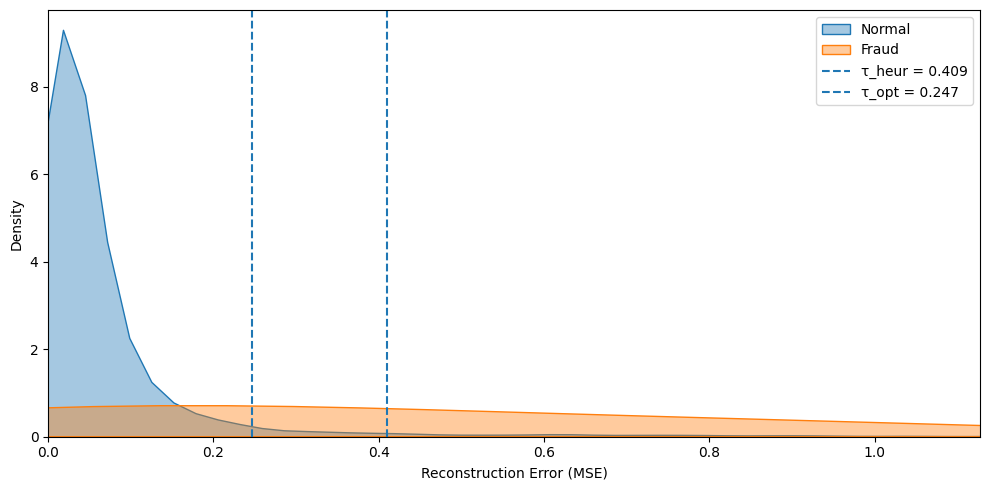

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

# KDE distributions for normal and fraudulent transactions
sns.kdeplot(
    calibration_mse_6[y_calibration == 0],
    ax=ax,
    label="Normal",
    fill=True,
    alpha=0.4
)

sns.kdeplot(
    calibration_mse_6[y_calibration == 1],
    ax=ax,
    label="Fraud",
    fill=True,
    alpha=0.4
)

# Decision thresholds
ax.axvline(
    threshold_heur_6,
    linestyle="--",
    label=f"τ_heur = {threshold_heur_6:.3f}"
)

ax.axvline(
    threshold_opt_6,
    linestyle="--",
    label=f"τ_opt = {threshold_opt_6:.3f}"
)

ax.set_xlabel("Reconstruction Error (MSE)")
ax.set_ylabel("Density")

ax.legend()

# Limit the displayed range only for visualization.
# The KDE itself is calculated using the complete Calibration set.
x_upper = np.quantile(calibration_mse_6, 0.99)
ax.set_xlim(0, x_upper)

plt.tight_layout()

if SAVE_ARTIFACTS:
    fig.savefig(
        save_path(
            "results/model_6_analysis/"
            "92_model_6_reconstruction_error_distribution.pdf"
        ),
        format="pdf",
        bbox_inches="tight"
    )

plt.show()

In [ ]:
x_upper = np.quantile(calibration_mse_6, 0.99)
print(x_upper)

1.1274087511033484


In [ ]:
for label, name in [(0, "Normal"), (1, "Fraud")]:
    values = calibration_mse_6[y_calibration == label]

    print(f"\n{name}")
    print(f"Count:  {len(values)}")
    print(f"Mean:   {np.mean(values):.6f}")
    print(f"Median: {np.median(values):.6f}")
    print(f"Std:    {np.std(values):.6f}")
    print(f"Q25:    {np.quantile(values, 0.25):.6f}")
    print(f"Q75:    {np.quantile(values, 0.75):.6f}")
    print(f"Q90:    {np.quantile(values, 0.90):.6f}")
    print(f"Q95:    {np.quantile(values, 0.95):.6f}")
    print(f"Q99:    {np.quantile(values, 0.99):.6f}")


Normal
Count:  6506
Mean:   0.064549
Median: 0.024693
Std:    0.175457
Q25:    0.012331
Q75:    0.056807
Q90:    0.125720
Q95:    0.212478
Q99:    0.725515

Fraud
Count:  697
Mean:   0.622219
Median: 0.125624
Std:    1.438195
Q25:    0.057372
Q75:    0.792645
Q90:    0.915531
Q95:    1.402726
Q99:    8.071012


## B. Loading Saved Artifacts

Appendix B is intended for loading previously saved results.

Some cells intentionally partially duplicate definitions from the main sections.

The subsections of Appendix B should be executed only when explicitly needed, as part of specific tasks related to restoring previously obtained results.

### B.1 Information on the Main Saved Artifacts

LIST OF MAIN SAVED ARTIFACTS

*Source and Intermediate Datasets*

- **01_ethereum_raw.csv** - Raw Ethereum transaction dataset collected from Etherscan

- **02_ethereum_parsed.csv** - Parsed transaction dataset after basic data cleaning and field conversion

*Prepared Data Splits*

- **11_train.csv** - Training set used to train the autoencoder on normal transactions

- **12_validation.csv** - Validation set used for training monitoring and early stopping

- **13_calibration.csv** - Calibration set used for threshold selection and model comparison

- **14_holdout_test.csv**- Holdout test set used for final model evaluation

*Preprocessing Artifacts*

- **21_sender_stats.csv** - Sender-level reference statistics calculated from the training set

- **22_method_id_frequency.csv** - Training-based frequency mapping for methodId encoding

- **23_standard_scaler.pkl** - StandardScaler fitted exclusively on the training set

*Pretrained Models*

- **41_model_1.keras** - Model 1
- **42_model_2.keras** - Model 2
- **43_model_3.keras** - Model 3
- **44_model_4.keras** - Model 4
- **45_model_5.keras** - Model 5
- **46_model_6.keras** - Model 6
- **47_model_7.keras** - Model 7

*SHAP artifacts:*

- **51_shap_background_indices.npy** - Background sample indices

- **52_shap_importance.csv** - Feature importance values

- **53_shap_values.npy** - Per-transaction SHAP values for all Calibration transactions

*Attention artifacts:*

- **61_attention_feature_neuron_correlations.csv** - Absolute Attention feature-neuron correlation matrix

- **62_att_importance.csv** - Attention-based feature importance values

*Comparison of the two methods:*

- **71_shap_att_comparison.csv** - Comparison of feature importance ranks produced by the two methods

*Alternative Method Artifacts*

- **81_isolation_forest.pkl** - Trained Isolation Forest model and calibrated threshold

- **82_lof_model.pkl** - Trained Local Outlier Factor model and calibrated threshold

- **84_vae_model.keras** - Complete trained VAE model

- **85_vae_model.weights.h5** - Trained VAE model weights

- **86_vae_inference.keras** - Deterministic VAE inference model for anomaly scoring

- **87_method_comparison.csv** — Calibration-set comparison metrics for all evaluated anomaly detection methods

*Auxiliary Artifacts*

- **91_model_6_threshold.pkl** - Calibrated decision threshold for Model 6


---


LIST OF NOTEBOOK SUBSECTION DEPENDENCIES ON SAVED ARTIFACTS

(applicable to execution scenario 2)

| Main-Body Subsection | Required Appendix B Subsections |
|---|---|
| 3.1 | B.3 |
| 5.1 | B.3, B.5, B.6 |
| 5.2 | B.3, B.5, B.6 |
| 5.3 | B.3, B.7, B.8 |
| 7 | B.3, B.5, B.6, B.14 |
| 8.1 | B.3, B.5, B.6 |
| 8.2 | B.3, B.5, B.6, B.7, B.8 |
| 8.3 | B.2, B.3, B.5, B.6, B.14 |
| 8.4 | B.3, B.5, B.6, B.14 |
| 8.5 | B.3, B.4, B.7 |

### B.2 Raw and Parsed Datasets

In [ ]:
raw_df = pd.read_csv(
    github_file(
        "data/source/01_ethereum_raw.csv"
    ),
    low_memory=False
)

parsed_df = pd.read_csv(
    github_file(
        "data/source/02_ethereum_parsed.csv"
    ),
    low_memory=False
)

print("Dataset loaded successfully.")

### B.3 Prepared Data Splits

In [ ]:
train_features = pd.read_csv(
    github_file(
        "data/splits/11_train.csv"
    ),
    low_memory=False
)

val_features = pd.read_csv(
    github_file(
        "data/splits/12_validation.csv"
    ),
    low_memory=False
)

calibration_features = pd.read_csv(
    github_file(
        "data/splits/13_calibration.csv"
    ),
    low_memory=False
)

holdout_test_features = pd.read_csv(
    github_file(
        "data/splits/14_holdout_test.csv"
    ),
    low_memory=False
)

feature_cols = [
    col for col in train_features.columns
    if col not in ["hash", "label"]
]

print("Prepared data splits loaded successfully.")

### B.4 Saved Artifacts

In [ ]:
sender_stats = pd.read_csv(
    github_file(
        "preprocessing/21_sender_stats.csv"
    ),
    index_col=0
)

method_id_frequency = (
    pd.read_csv(
        github_file(
            "preprocessing/22_method_id_frequency.csv"
        ),
        index_col=0
    )
    .iloc[:, 0]
)

scaler = joblib.load(
    github_file(
        "preprocessing/23_standard_scaler.pkl"
    )
)

print("Preprocessing artifacts loaded successfully.")

### B.5 Attention Layer

In [ ]:
@keras.utils.register_keras_serializable(package="AE_XAI_Ethereum")
class AttentionLayer(layers.Layer):
    """Trainable attention-based weighting of hidden representations."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        hidden_dim = int(input_shape[-1])

        self.W = self.add_weight(
            shape=(hidden_dim, hidden_dim),
            initializer="glorot_uniform",
            trainable=True,
            name="attention_weights"
        )

        self.b = self.add_weight(
            shape=(hidden_dim,),
            initializer="zeros",
            trainable=True,
            name="attention_bias"
        )

        super().build(input_shape)

    def call(self, inputs):
        scores = tf.nn.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        attention_weights = tf.nn.softmax(
            scores,
            axis=-1
        )

        return inputs * attention_weights

    def get_config(self):
        return super().get_config()

print(
    "AttentionLayer registered successfully."
)

### B.6 Saved Trained Models

In [ ]:
model_1 = keras.models.load_model(
    github_file("models/autoencoders/41_model_1.keras"),
    compile=False
)

model_2 = keras.models.load_model(
    github_file("models/autoencoders/42_model_2.keras"),
    compile=False
)

model_3 = keras.models.load_model(
    github_file("models/autoencoders/43_model_3.keras"),
    compile=False
)

model_4 = keras.models.load_model(
    github_file("models/autoencoders/44_model_4.keras"),
    compile=False
)

model_5 = keras.models.load_model(
    github_file("models/autoencoders/45_model_5.keras"),
    compile=False
)

model_6 = keras.models.load_model(
    github_file("models/autoencoders/46_model_6.keras"),
    compile=False
)

model_7 = keras.models.load_model(
    github_file("models/autoencoders/47_model_7.keras"),
    compile=False
)

print("Models 1–7 loaded successfully.")

### B.7 Saved SHAP Artifacts

In [ ]:
# ============================================================
# Load saved SHAP indices
# ============================================================

background_idx = np.load(
    github_file(
        "results/shap/51_shap_background_indices.npy"
    )
)

print(
    f"SHAP background indices loaded successfully: "
    f"{len(background_idx)} indices."
)

In [ ]:
# ============================================================
# Load saved SHAP feature importance
# ============================================================

importance = pd.read_csv(
    github_file(
        "results/shap/52_shap_importance.csv"
    )
)

print(importance)

In [ ]:
# ============================================================
# Load saved per-transaction SHAP values
# ============================================================

shap_array = np.load(
    github_file(
        "results/shap/53_shap_values.npy"
    )
)

assert shap_array.shape == (
    7203,
    21
)

print(
    "Per-transaction SHAP values loaded successfully."
)
print(
    "SHAP array shape:",
    shap_array.shape
)

### B.8 Attention Correlation Matrix and Feature Rankings

In [ ]:
# ============================================================
# Load Attention correlation matrix
# ============================================================

attention_corr_df = pd.read_csv(
    github_file(
        "results/attention/61_attention_feature_neuron_correlations.csv"
    ),
    index_col="feature"
)

print(
    "Attention correlation matrix loaded successfully. "
    f"Shape: {attention_corr_df.shape}"
)

In [ ]:
# ============================================================
# Load Attention feature importance
# ============================================================

att_importance = pd.read_csv(
    github_file(
        "results/attention/62_att_importance.csv"
    )
)

print(
    "Attention feature importance loaded successfully. "
    f"Shape: {att_importance.shape}"
)

### B.9 Comparison of SHAP-Based and Attention-Based Rankings

In [ ]:
comparison = pd.read_csv(
    github_file(
        "results/explainability_comparison/71_shap_att_comparison.csv"
    )
)

print(
    "SHAP-Attention comparison loaded successfully. "
    f"Shape: {comparison.shape}"
)

### B.10 Isolation Forest

In [ ]:
# ============================================================
# Load Isolation Forest model and calibrated threshold
# ============================================================

isolation_forest_artifact = joblib.load(
    github_file(
        "models/alternative_methods/81_isolation_forest.pkl"
    )
)

iso_forest_loaded = isolation_forest_artifact["model"]
threshold_opt_if_loaded = isolation_forest_artifact["threshold"]

print(
    f"Loaded threshold: "
    f"{threshold_opt_if_loaded:.6f}"
)

### B.11 Local Outlier Factor

In [ ]:
# ============================================================
# Load Local Outlier Factor model and calibrated threshold
# ============================================================

lof_artifact = joblib.load(
    github_file(
        "models/alternative_methods/82_lof_model.pkl"
    )
)

lof_loaded = lof_artifact["model"]
threshold_opt_lof_loaded = lof_artifact["threshold"]

print(
    f"Loaded threshold: "
    f"{threshold_opt_lof_loaded:.6f}"
)

### B.12 Variational Autoencoder

In [ ]:
# ============================================================
# Load VAE models and weights
# ============================================================

VAE_MODEL_PATH = github_file(
    "models/alternative_methods/84_vae_model.keras"
)

VAE_WEIGHTS_PATH = github_file(
    "models/alternative_methods/85_vae_model.weights.h5"
)

VAE_INFERENCE_PATH = github_file(
    "models/alternative_methods/86_vae_inference.keras"
)


# ============================================================
# Custom VAE layers
# Required for loading the complete VAE model
# ============================================================

@keras.utils.register_keras_serializable(package="ArticleAE")
class Sampling(layers.Layer):
    """Reparameterization layer: z = μ + σ·ε."""

    def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(z_mean)
        )

        return (
            z_mean
            + tf.exp(0.5 * z_log_var) * epsilon
        )

    def get_config(self):
        return super().get_config()


@keras.utils.register_keras_serializable(package="ArticleAE")
class VAELoss(layers.Layer):
    """
    Adds the VAE loss:
    reconstruction loss + beta * KL divergence.
    """

    def __init__(self, beta=0.2, **kwargs):
        super().__init__(**kwargs)
        self.beta = beta

    def call(self, inputs):
        x, x_decoded, z_mean, z_log_var = inputs

        reconstruction_loss = tf.reduce_mean(
            tf.reduce_mean(
                tf.square(x - x_decoded),
                axis=1
            )
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_mean(
                1
                + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = (
            reconstruction_loss
            + self.beta * kl_loss
        )

        self.add_loss(total_loss)

        return x_decoded

    def get_config(self):
        config = super().get_config()

        config.update({
            "beta": self.beta
        })

        return config


# ============================================================
# Load complete VAE
# ============================================================

vae_loaded = keras.models.load_model(
    VAE_MODEL_PATH
)

print("Complete VAE model loaded successfully.")


# ============================================================
# Load weights explicitly
# ============================================================

# The .keras file already contains the trained weights.
# This step explicitly restores the separately saved weights
# and can be used as an additional reproducibility check.

vae_loaded.load_weights(
    VAE_WEIGHTS_PATH
)

print("VAE weights loaded successfully.")


# ============================================================
# Load deterministic inference model
# ============================================================

vae_inference_loaded = keras.models.load_model(
    VAE_INFERENCE_PATH
)

print("VAE inference model loaded successfully.")


# ============================================================
# Model information
# ============================================================

print()
print("=== Complete VAE ===")
vae_loaded.summary()

print()
print("=== Deterministic VAE Inference Model ===")
vae_inference_loaded.summary()

### B.13 Results of the Comparison of Anomaly Detection Methods

This subsection allows the final comparison table of the methods obtained in Subsection 6.5 to be loaded without rerunning Experiments 6.1–6.5.

In [ ]:
# ============================================================
# Load anomaly detection method comparison results
# ============================================================

df_comparison = pd.read_csv(
    github_file(
        "results/alternative_methods/87_method_comparison.csv"
    )
)

print(
    "=== Calibration Set: Method Comparison ==="
)

print(
    df_comparison
    .round(4)
    .to_string(index=False)
)

### B.14 Calibrated Threshold for Model 6

In [ ]:
threshold_opt_6 = joblib.load(
    github_file(
        "results/model_6_analysis/91_model_6_threshold.pkl"
    )
)

print(f"Loaded threshold: {threshold_opt_6:.6f}")